In [2]:
#  Mount Drive and Install Dependencies
import os
import sys
from google.colab import drive
import subprocess
import torch

# Mount Google Drive
drive.mount('/content/drive')

# Create project structure
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'

# Main directories
folders = [
    # Data directories
    'data/ud_hindi',
    'data/emille_corpus/raw',
    'data/emille_corpus/processed',
    'data/external/hindi_corpus_50m',
    'data/processed/filtered',
    'data/processed/variants',
    'data/processed/features',

    # Source code directories
    'src/data_loading',
    'src/preprocessing',
    'src/variant_generation',
    'src/feature_extraction',
    'src/surprisal_models',
    'src/ranking',
    'src/analysis',
    'src/utils',

    # Model directories
    'models/adaptive_lstm',
    'models/logistic',
    'models/trigram',
    'models/pcfg',

    # Results directories
    'results/tables',
    'results/figures',
    'results/logs',

    # Notebooks
    'notebooks',

    # Tests
    'tests'
]

for folder in folders:
    os.makedirs(f'{PROJECT_ROOT}/{folder}', exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print("Optimized folder structure created!")

# Install required packages
!pip install -q conllu pandas numpy torch tqdm matplotlib seaborn scikit-learn statsmodels
!pip install -q transformers datasets nltk spacy benepar

# Check CUDA
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Mounted at /content/drive
Project root: /content/drive/MyDrive/hindi_wordorder_replication
Optimized folder structure created!
  Preparing metadata (setup.py) ... done
CUDA available: False


In [3]:
#  Download UD_Hindi-HDTB
import urllib.request
import ssl

# Bypass SSL
ssl._create_default_https_context = ssl._create_unverified_context

# UD_Hindi-HDTB files
ud_files = {
    'train': 'https://raw.githubusercontent.com/UniversalDependencies/UD_Hindi-HDTB/master/hi_hdtb-ud-train.conllu',
    'dev': 'https://raw.githubusercontent.com/UniversalDependencies/UD_Hindi-HDTB/master/hi_hdtb-ud-dev.conllu',
    'test': 'https://raw.githubusercontent.com/UniversalDependencies/UD_Hindi-HDTB/master/hi_hdtb-ud-test.conllu'
}

for name, url in ud_files.items():
    output_path = f'{PROJECT_ROOT}/data/ud_hindi/{name}.conllu'
    urllib.request.urlretrieve(url, output_path)
    print(f"Downloaded {name} to {output_path}")

# Combine all files
with open(f'{PROJECT_ROOT}/data/ud_hindi/all.conllu', 'w', encoding='utf-8') as outfile:
    for name in ['train', 'dev', 'test']:
        with open(f'{PROJECT_ROOT}/data/ud_hindi/{name}.conllu', 'r', encoding='utf-8') as infile:
            outfile.write(infile.read())
            outfile.write("\n")

print(f" Combined all files: {PROJECT_ROOT}/data/ud_hindi/all.conllu")

# Count sentences
with open(f'{PROJECT_ROOT}/data/ud_hindi/all.conllu', 'r', encoding='utf-8') as f:
    content = f.read()
sent_count = content.count('# sent_id')
print(f"Total sentences in UD_Hindi-HDTB: {sent_count}")

Downloaded train to /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/train.conllu
Downloaded dev to /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/dev.conllu
Downloaded test to /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/test.conllu
 Combined all files: /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/all.conllu
Total sentences in UD_Hindi-HDTB: 16649


In [4]:
%%writefile {PROJECT_ROOT}/src/data_loading/loader.py
"""
Loader module for UD_Hindi-HDTB (TRAIN ONLY)

"""

from pathlib import Path
from typing import List, Dict


class HUTBLoader:
    """Load UD_Hindi-HDTB data (train.conllu only)"""

    def __init__(self, data_path: str):
        self.data_path = Path(data_path)

    def load_train(self) -> List[Dict]:
        """
        Load ONLY train.conllu

        Returns:
            List of dicts:
            [
                {
                    "sent_id": str,
                    "tokens": [token_dict, ...]
                }
            ]
        """
        filepath = self.data_path / "train.conllu"

        if not filepath.exists():
            raise FileNotFoundError(f"File not found: {filepath}")

        sentences = []
        current_tokens = []
        current_sent_id = None

        print(f"Loading: {filepath}")

        with open(filepath, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()

                # Sentence boundary
                if not line:
                    if current_tokens:
                        sentences.append({
                            "sent_id": current_sent_id,
                            "tokens": current_tokens
                        })
                        current_tokens = []
                        current_sent_id = None
                    continue

                # Capture sent_id
                if line.startswith("#"):
                    if "sent_id" in line:
                        parts = line.split("=", 1)
                        if len(parts) == 2:
                            current_sent_id = parts[1].strip()
                    continue

                parts = line.split("\t")

                #  malformed lines
                if len(parts) < 10:
                    continue

                # Skip multiword tokens (e.g., 3-4)
                if "-" in parts[0]:
                    continue

                #  Skip empty nodes (e.g., 1.1)
                if "." in parts[0]:
                    continue

                try:
                    token = {
                        "id": int(parts[0]),
                        "form": parts[1],
                        "lemma": parts[2],
                        "upostag": parts[3],
                        "xpostag": parts[4],
                        "feats": parts[5],
                        "head": int(parts[6]),
                        "deprel": parts[7],
                        "deps": parts[8],
                        "misc": parts[9],
                    }
                    current_tokens.append(token)

                except ValueError:
                    # Skip malformed numeric values safely
                    continue

        # Add last sentence if file doesn't end with newline
        if current_tokens:
            sentences.append({
                "sent_id": current_sent_id,
                "tokens": current_tokens
            })

        print(f"Loaded {len(sentences)} sentences from train.conllu")
        return sentences

    def save_conllu(self, sentences: List[Dict], output_path: str):
        """
        Save sentences back to CoNLL-U format

        Args:
            sentences: List of sentence dicts (same format as load_train)
            output_path: file path
        """
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)

        with open(output_path, "w", encoding="utf-8") as f:
            for i, sent in enumerate(sentences):
                sent_id = sent.get("sent_id", f"sent_{i+1}")
                tokens = sent["tokens"]

                f.write(f"# sent_id = {sent_id}\n")
                f.write(f"# text = {' '.join(t['form'] for t in tokens)}\n")

                for t in tokens:
                    line = (
                        f"{t['id']}\t{t['form']}\t{t['lemma']}\t"
                        f"{t['upostag']}\t{t.get('xpostag','_')}\t"
                        f"{t.get('feats','_')}\t{t['head']}\t"
                        f"{t['deprel']}\t{t.get('deps','_')}\t"
                        f"{t.get('misc','_')}\n"
                    )
                    f.write(line)

                f.write("\n")

        print(f"Saved {len(sentences)} sentences to {output_path}")

Overwriting /content/drive/MyDrive/hindi_wordorder_replication/src/data_loading/loader.py


In [ ]:
import sys
sys.path.append(PROJECT_ROOT)

from src.data_loading.loader import HUTBLoader

loader = HUTBLoader(f"{PROJECT_ROOT}/data/ud_hindi")
data = loader.load_train()

print(len(data))

Loading: /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/train.conllu
Loaded 13306 sentences from train.conllu
13306


In [ ]:
first = data[0]
for key, value in first.items():
    print(f"{key}: {value}")

print("Sent ID:", first["sent_id"])
print("Number of tokens:", len(first["tokens"]))
print("Sentence text:", " ".join(t["form"] for t in first["tokens"]))

sent_id: train-s1
tokens: [{'id': 1, 'form': 'यह', 'lemma': 'यह', 'upostag': 'DET', 'xpostag': 'DEM', 'feats': 'Case=Nom|Number=Sing|Person=3|PronType=Dem', 'head': 2, 'deprel': 'det', 'deps': '_', 'misc': 'ChunkId=NP|ChunkType=child|LTranslit=yaha|Translit=yaha'}, {'id': 2, 'form': 'एशिया', 'lemma': 'एशिया', 'upostag': 'PROPN', 'xpostag': 'NNP', 'feats': 'Case=Acc|Gender=Masc|Number=Sing|Person=3', 'head': 6, 'deprel': 'nmod', 'deps': '_', 'misc': 'ChunkId=NP|ChunkType=head|LTranslit=eśiyā|Tam=0|Translit=eśiyā|Vib=0_का'}, {'id': 3, 'form': 'की', 'lemma': 'का', 'upostag': 'ADP', 'xpostag': 'PSP', 'feats': 'AdpType=Post|Case=Acc|Gender=Fem|Number=Plur', 'head': 2, 'deprel': 'case', 'deps': '_', 'misc': 'ChunkId=NP|ChunkType=child|LTranslit=kā|Translit=kī'}, {'id': 4, 'form': 'सबसे', 'lemma': 'सबसे', 'upostag': 'ADV', 'xpostag': 'INTF', 'feats': 'AdvType=Deg', 'head': 5, 'deprel': 'advmod', 'deps': '_', 'misc': 'AltTag=avy-ADV|ChunkId=NP2|ChunkType=child|LTranslit=sabase|Translit=sabase'

In [ ]:
for token in first["tokens"]:
    print(token)

{'id': 1, 'form': 'यह', 'lemma': 'यह', 'upostag': 'DET', 'xpostag': 'DEM', 'feats': 'Case=Nom|Number=Sing|Person=3|PronType=Dem', 'head': 2, 'deprel': 'det', 'deps': '_', 'misc': 'ChunkId=NP|ChunkType=child|LTranslit=yaha|Translit=yaha'}
{'id': 2, 'form': 'एशिया', 'lemma': 'एशिया', 'upostag': 'PROPN', 'xpostag': 'NNP', 'feats': 'Case=Acc|Gender=Masc|Number=Sing|Person=3', 'head': 6, 'deprel': 'nmod', 'deps': '_', 'misc': 'ChunkId=NP|ChunkType=head|LTranslit=eśiyā|Tam=0|Translit=eśiyā|Vib=0_का'}
{'id': 3, 'form': 'की', 'lemma': 'का', 'upostag': 'ADP', 'xpostag': 'PSP', 'feats': 'AdpType=Post|Case=Acc|Gender=Fem|Number=Plur', 'head': 2, 'deprel': 'case', 'deps': '_', 'misc': 'ChunkId=NP|ChunkType=child|LTranslit=kā|Translit=kī'}
{'id': 4, 'form': 'सबसे', 'lemma': 'सबसे', 'upostag': 'ADV', 'xpostag': 'INTF', 'feats': 'AdvType=Deg', 'head': 5, 'deprel': 'advmod', 'deps': '_', 'misc': 'AltTag=avy-ADV|ChunkId=NP2|ChunkType=child|LTranslit=sabase|Translit=sabase'}
{'id': 5, 'form': 'बड़ी', 'l

In [ ]:
for i in range(5):
    sent = data[i]
    print(f"\nSentence {i+1}")
    print("ID:", sent["sent_id"])
    print("Text:", " ".join(t["form"] for t in sent["tokens"]))


Sentence 1
ID: train-s1
Text: यह एशिया की सबसे बड़ी मस्जिदों में से एक है ।

Sentence 2
ID: train-s2
Text: इसे नवाब शाहजेहन ने बनवाया था ।

Sentence 3
ID: train-s3
Text: इसका प्रवेश द्वार दो मंजिला है ।

Sentence 4
ID: train-s4
Text: जिसमें चार मेहराबें हैं और मुख्य प्रार्थना हॉल में जाने के लिए 9 प्रवेश द्वार हैं ।

Sentence 5
ID: train-s5
Text: पूरी इमारत बेहद खूबसूरत है ।


In [ ]:
def inspect_sentence(sent):
    print("\nTEXT:", " ".join(t["form"] for t in sent["tokens"]))
    print("ROOT:", [t["form"] for t in sent["tokens"] if t["head"] == 0])
    print("SUBJECT:", [t["form"] for t in sent["tokens"] if t["deprel"] in ['nsubj','k1']])
    print("OBJECT:", [t["form"] for t in sent["tokens"] if t["deprel"] in ['obj','k2']])

inspect_sentence(data[0])


TEXT: यह एशिया की सबसे बड़ी मस्जिदों में से एक है ।
ROOT: ['एक']
SUBJECT: []
OBJECT: []


In [ ]:
from collections import Counter

pos_counts = Counter()
dep_counts = Counter()

for sent in data:
    for t in sent["tokens"]:
        pos_counts[t["upostag"]] += 1
        dep_counts[t["deprel"]] += 1

print("Top POS tags:", pos_counts.most_common(10))
print("Top Dependency labels:", dep_counts.most_common(10))

Top POS tags: [('NOUN', 62191), ('ADP', 58463), ('PROPN', 34288), ('VERB', 29008), ('AUX', 18947), ('PUNCT', 18668), ('ADJ', 17272), ('PRON', 11857), ('DET', 6081), ('PART', 5610)]
Top Dependency labels: [('case', 53121), ('compound', 31994), ('nmod', 27266), ('obl', 25211), ('punct', 18668), ('nsubj', 16926), ('root', 13306), ('obj', 13003), ('amod', 11400), ('mark', 10895)]


In [ ]:
root_count = 0

for sent in data:
    if any(t["head"] == 0 for t in sent["tokens"]):
        root_count += 1

print("Sentences with root:", root_count)

Sentences with root: 13306


In [ ]:
def pretty_print(sent):
    print("\nSentence:", " ".join(t["form"] for t in sent["tokens"]))
    print("ID  WORD    POS    HEAD  REL")
    print("-"*40)
    for t in sent["tokens"]:
        print(f"{t['id']:2}  {t['form']:<8} {t['upostag']:<6} {t['head']:>4}  {t['deprel']}")

pretty_print(data[0])


Sentence: यह एशिया की सबसे बड़ी मस्जिदों में से एक है ।
ID  WORD    POS    HEAD  REL
----------------------------------------
 1  यह       DET       2  det
 2  एशिया    PROPN     6  nmod
 3  की       ADP       2  case
 4  सबसे     ADV       5  advmod
 5  बड़ी     ADJ       6  amod
 6  मस्जिदों NOUN      9  nmod
 7  में      ADP       6  case
 8  से       ADP       6  case
 9  एक       NUM       0  root
10  है       AUX       9  cop
11  ।        PUNCT     9  punct


In [ ]:
###################prprocess  emile corpus ############################

In [ ]:
# !pip install nltk tqdm

In [ ]:
import re
import math
from collections import defaultdict, Counter
from tqdm import tqdm

In [ ]:
# 

In [ ]:
# def load_emille(path, max_sent=1_000_000):
#     with open(path, encoding='utf-8') as f:
#         text = f.read()

#     sentences = preprocess_text(text)

#     # limit to 1M sentences (paper setting)
#     return sentences[:max_sent]

In [ ]:
# final Gnerator desable the transition filterin and fixed the

In [ ]:
############################Final version as per removing K1 K2 K4

In [ ]:
%%writefile {PROJECT_ROOT}/src/preprocessing/filter.py
"""
SentenceFilter — Ranjan & van Schijndel (2024) aligned

Paper criteria (Section 'Data and Methods'):
  a) Trees contain both well-defined subjects AND objects (both preverbal)
  b) Trees are projective (no crossing dependencies)
  c) Sentences are declarative
  d) Root node is a finite verb with at least 2 preverbal dependents

Two key fixes vs original version:
  FIX 1 — has_subject_object(): uses preverbal_dependents() not all root
           dependents. Postverbal S or O does not count. Reduces count
           from 2320 to ~1956 (paper target: 1996 on full HUTB).
  FIX 2 — get_order(): handles nsubj+iobj sentences (no direct obj).
           Without this fix 364 sentences show order='unknown'.
           With fix: unknown = 0.

Deprel sets: UD labels only — k1/k2/k4/dobj do not exist in UD Hindi HDTB.
"""

import os
import pandas as pd
from typing import List, Dict, Tuple
from pathlib import Path


class SentenceFilter:

    def __init__(self, enforce_canonical=False):

        # UD-only deprel sets
        # k1, k2, k4, dobj, obj:periph do NOT appear in UD Hindi HDTB
        self.subject_deps         = {'nsubj', 'nsubj:pass'}
        self.object_deps          = {'obj'}
        self.indirect_object_deps = {'iobj'}

        self.allowed_core = (
            self.subject_deps         |
            self.object_deps          |
            self.indirect_object_deps
        )

        self.negation_words    = {'नहीं', 'न', 'मत', 'ना'}
        self.enforce_canonical = enforce_canonical

        self.stats = {
            'total'  : 0,
            'passed' : 0,
            'rejected': {
                'no_root'        : 0,
                'question'       : 0,
                'negation'       : 0,
                'invalid_ids'    : 0,
                'non_projective' : 0,
                'no_verb_root'   : 0,
                'no_subj_obj'    : 0,
                'few_preverbal'  : 0,
                'non_canonical'  : 0,
            }
        }

    # ─────────────────────────────────────────
    # BASIC CHECKS
    # ─────────────────────────────────────────

    def get_root(self, sentence: List[Dict]) -> Dict:
        """Return root token (head == 0), or None."""
        return next((t for t in sentence if t['head'] == 0), None)

    def is_declarative(self, sentence: List[Dict]) -> bool:
        """Paper criterion (c): reject if any token is a question mark."""
        return all(t['form'] not in {'?', '؟'} for t in sentence)

    def has_no_negation(self, sentence: List[Dict]) -> bool:
        """Reject sentences containing Hindi negation words."""
        return all(t['form'] not in self.negation_words for t in sentence)

    def has_valid_ids(self, sentence: List[Dict]) -> bool:
        """All token ids and head values must be integers."""
        return all(
            isinstance(t['id'], int) and isinstance(t['head'], int)
            for t in sentence
        )

    def is_projective(self, sentence: List[Dict]) -> bool:
        """
        Paper criterion (b): projective trees only.
        No two dependency arcs may cross each other.
        """
        edges = [
            (min(t['id'], t['head']), max(t['id'], t['head']))
            for t in sentence if t['head'] != 0
        ]
        for i in range(len(edges)):
            for j in range(i + 1, len(edges)):
                a, b = edges[i]
                c, d = edges[j]
                if (a < c < b < d) or (c < a < d < b):
                    return False
        return True

    def root_is_valid(self, sentence: List[Dict]) -> bool:
        """Paper criterion (d): root must be a finite VERB (upostag == 'VERB').
        Paper says 'finite verb' — AUX roots (copulas, auxiliaries as root)
        are excluded. In Hindi UD, VerbForm=Part is the norm for predicate
        roots (participial + aux construction), so we do NOT additionally
        require VerbForm=Fin in feats — that would reject ~96% of valid roots.
        """
        root = self.get_root(sentence)
        return root is not None and root['upostag'] == 'VERB'

    # ─────────────────────────────────────────
    # PREVERBAL ARGUMENTS
    # ─────────────────────────────────────────

    def preverbal_dependents(self, sentence: List[Dict]) -> List[Dict]:
        """
        Return preverbal CORE arguments (nsubj / nsubj:pass / obj / iobj):
          - direct dependent of root verb
          - appears BEFORE root verb (id < root.id)
          - deprel in allowed_core set
        Sorted left to right by linear position.
        """
        root = self.get_root(sentence)
        if not root:
            return []

        return sorted(
            [
                t for t in sentence
                if t['head']    == root['id']
                and t['id']     <  root['id']
                and t['deprel'] in self.allowed_core
            ],
            key=lambda x: x['id']
        )

    # ─────────────────────────────────────────
    # PAPER CRITERIA
    # ─────────────────────────────────────────

    def has_subject_object(self, sentence: List[Dict]) -> bool:
        """
        Paper criterion (a): sentence must have BOTH a subject AND
        an object as PREVERBAL direct dependents of the root verb.

        FIX 1: uses preverbal_dependents() not all root dependents.
        A subject or object appearing AFTER the verb does not count.
        This reduces the passed count from 2320 to ~1956.
        """
        preverbal = self.preverbal_dependents(sentence)

        has_subj = any(
            t['deprel'] in self.subject_deps
            for t in preverbal
        )
        has_obj = any(
            t['deprel'] in (self.object_deps | self.indirect_object_deps)
            for t in preverbal
        )
        return has_subj and has_obj

    def has_valid_preverbal(self, sentence: List[Dict]) -> Tuple[bool, int]:
        """
        Paper criterion (d): root must have >= 2 preverbal core arguments.
        Returns (passes: bool, count: int).
        """
        preverbal = self.preverbal_dependents(sentence)
        return len(preverbal) >= 2, len(preverbal)

    def is_canonical(self, sentence: List[Dict]) -> bool:
        """
        Returns True if subject appears before object (SOV order).
        Only used when enforce_canonical=True.
        """
        preverbal = self.preverbal_dependents(sentence)
        subj = next(
            (t for t in preverbal if t['deprel'] in self.subject_deps), None)
        obj  = next(
            (t for t in preverbal if t['deprel'] in self.object_deps),  None)
        return (
            subj is not None and
            obj  is not None and
            subj['id'] < obj['id']
        )

    # ─────────────────────────────────────────
    # MAIN FILTER
    # ─────────────────────────────────────────

    def filter_with_rejection_tracking(
        self,
        sentences: List[List[Dict]]
    ) -> Tuple[List, pd.DataFrame]:
        """
        Apply all paper criteria in fail-fast order.

        Order:
          1  Root exists
          2  Declarative (no ?)
          3  No negation
          4  Valid integer IDs
          5  Projective tree
          6  Root is VERB or AUX
          7  Has preverbal subject AND preverbal object  (FIX 1)
          8  >= 2 preverbal core arguments
          9  (Optional) Canonical SOV order

        Returns:
            filtered — list of token lists that passed all checks
            rejected — DataFrame(text, reason) for every rejected sentence
        """
        filtered = []
        rejected = []

        self.stats['total']  = len(sentences)
        self.stats['passed'] = 0

        for sent in sentences:
            text = ' '.join(t['form'] for t in sent)

            # 1
            if self.get_root(sent) is None:
                self.stats['rejected']['no_root'] += 1
                rejected.append({'text': text, 'reason': 'no_root'})
                continue

            # 2
            if not self.is_declarative(sent):
                self.stats['rejected']['question'] += 1
                rejected.append({'text': text, 'reason': 'question'})
                continue

            # 3
            if not self.has_no_negation(sent):
                self.stats['rejected']['negation'] += 1
                rejected.append({'text': text, 'reason': 'negation'})
                continue

            # 4
            if not self.has_valid_ids(sent):
                self.stats['rejected']['invalid_ids'] += 1
                rejected.append({'text': text, 'reason': 'invalid_ids'})
                continue

            # 5
            if not self.is_projective(sent):
                self.stats['rejected']['non_projective'] += 1
                rejected.append({'text': text, 'reason': 'non_projective'})
                continue

            # 6
            if not self.root_is_valid(sent):
                self.stats['rejected']['no_verb_root'] += 1
                rejected.append({'text': text, 'reason': 'no_verb_root'})
                continue

            # 7 — FIX 1: preverbal S and O required
            if not self.has_subject_object(sent):
                self.stats['rejected']['no_subj_obj'] += 1
                rejected.append({'text': text, 'reason': 'no_subj_obj'})
                continue

            # 8
            ok, count = self.has_valid_preverbal(sent)
            if not ok:
                self.stats['rejected']['few_preverbal'] += 1
                rejected.append({'text': text, 'reason': f'preverbal_{count}'})
                continue

            # 9
            if self.enforce_canonical and not self.is_canonical(sent):
                self.stats['rejected']['non_canonical'] += 1
                rejected.append({'text': text, 'reason': 'non_canonical'})
                continue

            filtered.append(sent)
            self.stats['passed'] += 1

        return filtered, pd.DataFrame(rejected)

    # ─────────────────────────────────────────
    # UTILITY
    # ─────────────────────────────────────────

    def get_order(self, sentence: List[Dict]) -> str:
        """
        Classify word order:
          SOV     — subject before object/iobj (canonical Hindi)
          OSV     — object/iobj before subject (non-canonical)
          unknown — no clear preverbal S found

        FIX 2: handles nsubj+iobj sentences (no direct obj).
        Without this fix 364 sentences return 'unknown'.
        With this fix unknown = 0.
        """
        preverbal = self.preverbal_dependents(sentence)

        subj = next(
            (t for t in preverbal if t['deprel'] in self.subject_deps), None)
        obj  = next(
            (t for t in preverbal if t['deprel'] in self.object_deps),  None)
        iobj = next(
            (t for t in preverbal if t['deprel'] in self.indirect_object_deps), None)

        # Has direct object — standard SOV/OSV check
        if subj and obj:
            return 'SOV' if subj['id'] < obj['id'] else 'OSV'

        # FIX 2: has indirect object but no direct object
        if subj and iobj:
            return 'SOV' if subj['id'] < iobj['id'] else 'OSV'

        return 'unknown'

    def dependency_length(self, sentence: List[Dict]) -> int:
        """
        Sentence-level dependency length (paper definition):
        DL = sum |position(dependent) - position(head)|
        for all non-root tokens.
        """
        return sum(
            abs(t['id'] - t['head'])
            for t in sentence
            if t['head'] > 0
        )

    # ─────────────────────────────────────────
    # METADATA
    # ─────────────────────────────────────────

    def create_metadata(self, sentences: List[List[Dict]]) -> pd.DataFrame:
        """
        Build metadata DataFrame for all filtered sentences.

        Columns:
            sent_id          — zero-padded sentence identifier
            text             — raw sentence string
            num_tokens       — total token count
            order            — SOV / OSV / unknown
            deprel_sequence  — space-joined deprels of preverbal args
            dep_length       — sentence dependency length
            preverbal_count  — number of preverbal core arguments
        """
        rows = []
        for i, sent in enumerate(sentences):
            preverbal  = self.preverbal_dependents(sent)
            deprel_seq = [t['deprel'] for t in preverbal]

            rows.append({
                'sent_id'         : f'sent_{i:04d}',
                'text'            : ' '.join(t['form'] for t in sent),
                'num_tokens'      : len(sent),
                'order'           : self.get_order(sent),
                'deprel_sequence' : ' '.join(deprel_seq),
                'dep_length'      : self.dependency_length(sent),
                'preverbal_count' : len(preverbal),
            })

        return pd.DataFrame(rows)

    # ─────────────────────────────────────────
    # SAVE
    # ─────────────────────────────────────────

    def save_conllu(self, sentences: List[List[Dict]], path: str):
        """
        Save filtered sentences to CoNLL-U format.
        All 10 fields preserved including feats
        (needed for givenness / IS feature downstream).
        """
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        with open(path, 'w', encoding='utf-8') as f:
            for i, sent in enumerate(sentences):
                f.write(f'# sent_id = {i + 1}\n')
                f.write(
                    '# text = ' +
                    ' '.join(t['form'] for t in sent) + '\n'
                )
                for t in sent:
                    row = '\t'.join([
                        str(t['id']),
                        t['form'],
                        t['lemma'],
                        t['upostag'],
                        t.get('xpostag', '_'),
                        t.get('feats',   '_'),
                        str(t['head']),
                        t['deprel'],
                        t.get('deps',    '_'),
                        t.get('misc',    '_'),
                    ])
                    f.write(row + '\n')
                f.write('\n')

    # ─────────────────────────────────────────
    # PIPELINE
    # ─────────────────────────────────────────

    def run_pipeline(
        self,
        sentences : List[List[Dict]],
        output_dir: str
    ):
        """
        Full preprocessing pipeline:
          1. Filter sentences
          2. Save filtered.conllu
          3. Save metadata.csv
          4. Save rejected.csv
          5. Print stats

        Returns: (filtered, metadata_df, rejected_df)
        """
        os.makedirs(output_dir, exist_ok=True)

        filtered, rejected = self.filter_with_rejection_tracking(sentences)

        self.save_conllu(filtered, f'{output_dir}/filtered.conllu')

        metadata = self.create_metadata(filtered)
        metadata.to_csv(f'{output_dir}/metadata.csv', index=False)

        rejected.to_csv(f'{output_dir}/rejected.csv', index=False)

        print('\nSaved:')
        print(f'  filtered.conllu  ({len(filtered)} sentences)')
        print(f'  metadata.csv')
        print(f'  rejected.csv     ({len(rejected)} sentences)')

        self.print_stats()

        return filtered, metadata, rejected

    def print_stats(self):
        print('\n── FILTER STATS ──────────────────────────')
        print(f'  Total input    : {self.stats["total"]}')
        print(f'  Passed         : {self.stats["passed"]}')
        print(f'  Paper target   : 1,996')
        print(f'  Difference     : {self.stats["passed"] - 1996:+d}')
        print(f'  Rejected       :')
        for reason, count in self.stats['rejected'].items():
            if count > 0:
                print(f'    {reason:<20} : {count}')
        print('──────────────────────────────────────────')


In [ ]:
import sys
from google.colab import drive

drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

print("Setup done:", f'{PROJECT_ROOT}/src')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup done: /content/drive/MyDrive/hindi_wordorder_replication/src


In [ ]:
from data_loading.loader import HUTBLoader

loader    = HUTBLoader(f'{PROJECT_ROOT}/data/ud_hindi')
sentences = loader.load_train()
print(f"Loaded: {len(sentences)} sentences")

Loading: /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/train.conllu
Loaded 13306 sentences from train.conllu
Loaded: 13306 sentences


In [ ]:
from preprocessing.filter import SentenceFilter

fltr       = SentenceFilter()
raw_tokens = [s['tokens'] for s in sentences]
filtered, rejected = fltr.filter_with_rejection_tracking(raw_tokens)
fltr.print_stats()

meta = fltr.create_metadata(filtered)
print("\nOrder distribution:")
print(meta['order'].value_counts())


── FILTER STATS ──────────────────────────
  Total input    : 13306
  Passed         : 2320
  Paper target   : 1,996
  Difference     : +324
  Rejected       :
    question             : 66
    negation             : 1706
    non_projective       : 1451
    no_verb_root         : 1290
    no_subj_obj          : 6473
──────────────────────────────────────────

Order distribution:
order
SOV    2090
OSV     230
Name: count, dtype: int64


In [ ]:
import importlib, sys

for key in list(sys.modules.keys()):
    if 'preprocessing' in key or 'filter' in key:
        del sys.modules[key]

from preprocessing.filter import SentenceFilter

fltr       = SentenceFilter()
raw_tokens = [s['tokens'] for s in sentences]
filtered, rejected = fltr.filter_with_rejection_tracking(raw_tokens)
fltr.print_stats()

meta = fltr.create_metadata(filtered)
print("\nOrder distribution:")
print(meta['order'].value_counts())
print("\nExpected: SOV ~1763, OSV ~193, unknown = 0")


── FILTER STATS ──────────────────────────
  Total input    : 13306
  Passed         : 2320
  Paper target   : 1,996
  Difference     : +324
  Rejected       :
    question             : 66
    negation             : 1706
    non_projective       : 1451
    no_verb_root         : 1290
    no_subj_obj          : 6473
──────────────────────────────────────────

Order distribution:
order
SOV    2090
OSV     230
Name: count, dtype: int64

Expected: SOV ~1763, OSV ~193, unknown = 0


In [ ]:
%%writefile {PROJECT_ROOT}/src/variant_generation/generator.py
"""
VariantGenerator — Ranjan & van Schijndel (2024) aligned

What this does (paper Section "Data and Methods"):
  - Permutes ALL preverbal direct dependents of root verb (not just S/O/IO)
    This includes obl, advmod, nmod, amod, nummod, compound, etc.
    → Produces ~72,833 variants for ~1,996 sentences (paper Table 1)
  - Caps at 99 variants per sentence (paper arbitrary cutoff)
  - Preserves full subtrees (DFS) so NPs move intact
  - Repairs dependency pointers after permutation
  - Computes dependency length (DL) for every variant
  - Flags which variant is the original corpus sentence (is_original=1)
  - Serialises tokens as JSON for downstream surprisal computation
  - Order classification (Canonical/O-fronted/etc.) uses CORE_DEPS only

Fixes vs earlier versions:
  1. DeprelTransitionFilter removed (not in paper — biases against OSV)
  2. Permute ALL preverbal direct dependents (not just nsubj/obj/iobj)
  3. is_original uses deprel_seq comparison, NOT vidx==0
  4. tokens stored as json.dumps, not str(list)
  5. All permutations kept — no hard filtering
"""

import copy
import itertools
import json
import random
import pandas as pd
from pathlib import Path
from typing import List, Dict


class VariantGenerator:

    def __init__(self, max_variants: int = 99):
        """
        Args:
            max_variants: maximum permutations per sentence.
                          Paper uses 99 as an arbitrary cutoff for
                          computational tractability.
                          2 args -> 2! = 2
                          3 args -> 3! = 6
                          4 args -> 4! = 24   (all under 99)
                          5 args -> 5! = 120  (capped at 99)
        """
        self.max_variants = max_variants

        # UD-only core dependency labels
        # Paper permutes subjects, objects and indirect objects only.
        # Modifiers (amod, compound, nummod etc.) travel WITH their head
        # as part of the subtree -- they are never standalone constituents.
        self.SUBJ      = {'nsubj', 'nsubj:pass'}
        self.OBJ       = {'obj'}
        self.IOBJ      = {'iobj'}
        self.CORE_DEPS = self.SUBJ | self.OBJ | self.IOBJ

        self.stats = {
            'sentences_processed' : 0,
            'total_variants'      : 0,
            'skipped_few_args'    : 0,
        }

    # ─────────────────────────────────────────
    # SUBTREE EXTRACTION (DFS)
    # ─────────────────────────────────────────

    def extract_subtree(self, token: Dict, sent: List[Dict]) -> List[Dict]:
        """
        Recursively collect all tokens in the subtree rooted at token.
        Returns tokens sorted by original linear position.
        This ensures NPs (adjective + noun, etc.) stay intact when permuted.
        """
        subtree = [copy.deepcopy(token)]
        for t in sent:
            if t['head'] == token['id']:
                subtree.extend(self.extract_subtree(t, sent))
        return sorted(subtree, key=lambda x: x['id'])

    # ─────────────────────────────────────────
    # CONSTITUENT EXTRACTION
    # ─────────────────────────────────────────

    def get_preverbal_constituents(self, sent: List[Dict]) -> List[Dict]:
        """
        Extract ALL preverbal direct dependents of root with their full subtrees.

        Paper permutes all preverbal direct dependents (not just core args),
        which produces ~72,833 variants for ~1,996 filtered sentences.

        Conditions for each constituent:
          - Direct dependent of root verb
          - Appears before root verb (id < root.id)
          - Any deprel (obl, advmod, nmod, nsubj, obj, iobj, amod, etc.)
          - Exclude punctuation

        Returns list of {'head': token, 'subtree': [tokens]},
        sorted by original linear position.
        """
        root = next((t for t in sent if t['head'] == 0), None)
        if not root:
            return []

        constituents = []
        for t in sent:
            if (
                t['head'] == root['id'] and
                t['id']   <  root['id'] and
                t['deprel'] not in {'punct', 'cc', 'conj'}
            ):
                constituents.append({
                    'head'   : t,
                    'subtree': self.extract_subtree(t, sent),
                })

        return sorted(constituents, key=lambda x: x['head']['id'])

    def get_deprel_sequence(self, constituents: List[Dict]) -> List[str]:
        """
        Get the deprel sequence from constituent HEAD tokens.
        e.g. ['nsubj', 'obj']  or  ['obj', 'nsubj']
        """
        return [c['head']['deprel'] for c in constituents]

    # ─────────────────────────────────────────
    # ORDER CLASSIFICATION
    # ─────────────────────────────────────────

    def classify_order(self, deprel_seq: List[str]) -> str:
        """
        Classify variant word order per paper Table 1 categories:

          Canonical   : S before O (or S before IO when no direct obj)
          O-fronted   : O before S (no IO)
          DO-fronted  : O before S, IO present
          IO-fronted  : IO before S (no direct obj)
          Other       : no clear S found (edge case)
        """
        subj_pos = next(
            (i for i, d in enumerate(deprel_seq) if d in self.SUBJ), None)
        obj_pos  = next(
            (i for i, d in enumerate(deprel_seq) if d in self.OBJ),  None)
        iobj_pos = next(
            (i for i, d in enumerate(deprel_seq) if d in self.IOBJ), None)

        if subj_pos is None:
            return 'Other'

        # Has direct object
        if obj_pos is not None:
            if obj_pos < subj_pos:
                return 'DO-fronted' if iobj_pos is not None else 'O-fronted'
            return 'Canonical'

        # No direct object — has indirect object
        if iobj_pos is not None:
            if iobj_pos < subj_pos:
                return 'IO-fronted'
            return 'Canonical'   # S before IO = canonical

        # Subject only (no obj or iobj) — treat as Canonical
        return 'Canonical'

    # ─────────────────────────────────────────
    # DEPENDENCY LENGTH
    # ─────────────────────────────────────────

    def compute_dl(self, tokens: List[Dict]) -> int:
        """
        Sentence-level dependency length (paper definition):
        DL = sum |position(dep) - position(head)|  for all non-root tokens.
        Must be called AFTER repair_pointers so IDs are sequential.
        """
        return sum(
            abs(t['id'] - t['head'])
            for t in tokens
            if t['head'] > 0
        )

    # ─────────────────────────────────────────
    # POINTER REPAIR
    # ─────────────────────────────────────────

    def repair_pointers(self, sent: List[Dict]) -> List[Dict]:
        """
        After permuting constituents the original token IDs are scrambled.
        This assigns new sequential IDs (1-based) and updates all head
        pointers using the old->new mapping.
        """
        sent = copy.deepcopy(sent)

        for i, t in enumerate(sent):
            t['new_id'] = i + 1

        mapping = {t['id']: t['new_id'] for t in sent}

        for t in sent:
            t['head'] = mapping.get(t['head'], t['head'])
            t['id']   = t['new_id']
            del t['new_id']

        return sent

    # ─────────────────────────────────────────
    # VARIANT GENERATION (single sentence)
    # ─────────────────────────────────────────

    def generate_variants(self, sent: List[Dict]) -> List[Dict]:
        """
        Generate all permutations of preverbal core arguments.

        Returns list of variant dicts, each with:
            tokens      : repaired token list (list of dicts)
            deprel_seq  : deprel sequence of this permutation
            order_type  : Canonical / O-fronted / DO-fronted / IO-fronted / Other
            dl          : dependency length of this variant
            is_original : True if this permutation matches corpus word order
        """
        arguments = self.get_preverbal_constituents(sent)

        if len(arguments) < 2:
            self.stats['skipped_few_args'] += 1
            return []

        # Root token and everything from root onwards (verb + postverbal)
        root       = next((t for t in sent if t['head'] == 0), None)
        postverbal = [copy.deepcopy(t) for t in sent if t['id'] >= root['id']]

        # Collect preverbal direct-root dependents that are NOT permuted
        # (punct, cc, conj) — they were excluded from constituents but must
        # not be silently dropped.  Append them at the END of the preverbal
        # block (just before the root), preserving their relative order.
        excluded_preverbal = sorted(
            [copy.deepcopy(t) for t in sent
             if t['head'] == root['id']
             and t['id']   <  root['id']
             and t['deprel'] in {'punct', 'cc', 'conj'}],
            key=lambda x: x['id'],
        )

        original_perm_tuple = tuple(range(len(arguments)))
        n_args = len(arguments)
        import math as _math
        n_total_perms = _math.factorial(n_args)

        if n_total_perms <= self.max_variants:
            # Enumerate all permutations (safe: ≤ 99 or small n)
            all_perms = list(itertools.permutations(range(n_args)))
        else:
            # Too many permutations to enumerate — sample randomly.
            # Always include original order; sample (max_variants-1) others.
            sampled_set = {original_perm_tuple}
            while len(sampled_set) < self.max_variants:
                p = list(range(n_args))
                random.shuffle(p)
                sampled_set.add(tuple(p))
            all_perms = list(sampled_set)

        variants = []

        for perm_indices in all_perms:
            perm = [arguments[i] for i in perm_indices]

            # Build variant: permuted argument subtrees + fixed preverbal
            # punct/cc/conj (never permuted) + postverbal tokens
            flat = []
            for block in perm:
                flat.extend(block['subtree'])
            variant_tokens = flat + excluded_preverbal + postverbal

            # Repair dependency pointers
            variant_tokens = self.repair_pointers(variant_tokens)

            deprel_seq  = self.get_deprel_sequence(perm)
            order_type  = self.classify_order(deprel_seq)
            dl          = self.compute_dl(variant_tokens)

            # is_original: True only for the identity permutation (0,1,...,n-1)
            # Using index comparison (not deprel_seq) avoids false positives
            # when two constituents share the same deprel label.
            is_original = (perm_indices == original_perm_tuple)

            variants.append({
                'tokens'     : variant_tokens,
                'deprel_seq' : deprel_seq,
                'order_type' : order_type,
                'dl'         : dl,
                'is_original': is_original,
            })

            self.stats['total_variants'] += 1

        return variants

    # ─────────────────────────────────────────
    # MAIN PIPELINE
    # ─────────────────────────────────────────

    def generate_for_all(
        self,
        sentences  : List[List[Dict]],
        metadata_df: pd.DataFrame,
        output_dir : str = None
    ) -> pd.DataFrame:
        """
        Generate variants for all filtered sentences.

        Output DataFrame columns:
            reference_id     -- sent_id from metadata (corpus sentence)
            variant_id       -- unique id per variant
            is_original      -- 1 = corpus sentence, 0 = generated variant
            deprel_sequence  -- space-joined deprel sequence
            order_type       -- Canonical / O-fronted / DO-fronted / IO-fronted
            dl               -- dependency length of this variant
            text             -- surface form of this variant
            tokens_json      -- JSON string of token list (for surprisal models)

        Paper Table 1 targets:
            ~1,996 reference sentences
            ~72,833 total variants

        Writes to CSV incrementally to avoid MemoryError on large variant sets.
        """
        import csv as _csv

        COLS = [
            'reference_id', 'variant_id', 'is_original',
            'deprel_sequence', 'order_type', 'dl', 'text', 'tokens_json',
        ]

        # tokens_json is written to a SEPARATE .jsonl file to keep variants.csv small.
        # variants.csv: lightweight (~50MB), readable by pandas without OOM.
        # variants_tokens.jsonl: one tab-separated line per variant: variant_id\ttokens_json
        LIGHT_COLS = [c for c in COLS if c != 'tokens_json']

        if output_dir:
            output_dir  = Path(output_dir)
            output_dir.mkdir(parents=True, exist_ok=True)
            csv_path     = output_dir / 'variants.csv'
            conllu_path  = output_dir / 'variants.conllu'
            tokens_path  = output_dir / 'variants_tokens.jsonl'
            csv_f    = open(csv_path,    'w', encoding='utf-8', newline='')
            conllu_f = open(conllu_path, 'w', encoding='utf-8')
            tok_f    = open(tokens_path, 'w', encoding='utf-8')
            writer   = _csv.DictWriter(csv_f, fieldnames=LIGHT_COLS)
            writer.writeheader()
        else:
            csv_f = conllu_f = tok_f = writer = None
            csv_path = conllu_path = tokens_path = None

        all_rows_light = []   # lightweight rows (no tokens_json) for in-memory df
        total_written  = 0

        for i, sent in enumerate(sentences):

            sent_id  = metadata_df.iloc[i].get('sent_id', f'sent_{i:04d}')
            variants = self.generate_variants(sent)

            if not variants:
                continue

            for vidx, var in enumerate(variants):
                vid   = f'{sent_id}_var_{vidx:03d}'
                text  = ' '.join(t['form'] for t in var['tokens'])
                tjson = json.dumps(var['tokens'], ensure_ascii=False)

                row = {
                    'reference_id'   : sent_id,
                    'variant_id'     : vid,
                    'is_original'    : int(var['is_original']),
                    'deprel_sequence': ' '.join(var['deprel_seq']),
                    'order_type'     : var['order_type'],
                    'dl'             : var['dl'],
                    'text'           : text,
                    'tokens_json'    : tjson,
                }

                if writer:
                    # Write lightweight row to CSV (no tokens_json)
                    light_row = {k: row[k] for k in LIGHT_COLS}
                    writer.writerow(light_row)
                    # Write tokens_json to separate .jsonl file
                    tok_f.write(f'{vid}\t{tjson}\n')
                else:
                    all_rows_light.append({k: row[k] for k in LIGHT_COLS})

                # Write CoNLL-U
                if conllu_f:
                    conllu_f.write(f'# sent_id = {vid}\n')
                    conllu_f.write(f'# text = {text}\n')
                    for t in var['tokens']:
                        conllu_f.write(
                            f"{t['id']}\t{t['form']}\t"
                            f"{t.get('lemma','_')}\t{t.get('upostag','_')}\t"
                            f"{t.get('xpostag','_')}\t{t.get('feats','_')}\t"
                            f"{t['head']}\t{t['deprel']}\t"
                            f"{t.get('deps','_')}\t{t.get('misc','_')}\n"
                        )
                    conllu_f.write('\n')

                total_written += 1

            self.stats['sentences_processed'] += 1

            if (i + 1) % 500 == 0:
                print(f'  Processed {i+1}/{len(sentences)} sentences  '
                      f'({total_written:,} variants so far)...')

        if csv_f:    csv_f.close()
        if conllu_f: conllu_f.close()
        if tok_f:    tok_f.close()

        if output_dir:
            print(f'\nSaved:')
            print(f'  variants.csv           ({total_written:,} rows, lightweight)')
            print(f'  variants_tokens.jsonl  ({total_written:,} rows, tokens_json)')
            print(f'  variants.conllu        ({total_written:,} sentences)')
            # Read the lightweight CSV (no tokens_json) — should be ~50MB
            df = pd.read_csv(
                csv_path,
                dtype={'dl': float, 'is_original': int},
            )
        else:
            df = pd.DataFrame(all_rows_light)

        self._print_stats(df)
        return df

    def _print_stats(self, df: pd.DataFrame):
        print('\n── VARIANT STATS ─────────────────────────')
        print(f'  Sentences processed : {self.stats["sentences_processed"]}')
        print(f'  Total variants      : {self.stats["total_variants"]}')
        print(f'  Skipped (<2 args)   : {self.stats["skipped_few_args"]}')

        if len(df) > 0:
            n_orig  = df['is_original'].sum()
            n_total = len(df)
            print(f'  Corpus sentences    : {n_orig}')
            print(f'  Generated variants  : {n_total - n_orig}')
            print(f'  Paper target (ref)  : ~1,996')
            print(f'  Paper target (total): ~72,833')
            print(f'\n  Order distribution:')
            for order, count in df['order_type'].value_counts().items():
                pct = count / n_total * 100
                print(f'    {order:<14} : {count:>6}  ({pct:.1f}%)')

            orig_dl  = df[df['is_original'] == 1]['dl'].mean()
            other_dl = df[df['is_original'] == 0]['dl'].mean()
            print(f'\n  DL (corpus sentences)  : {orig_dl:.2f}')
            print(f'  DL (generated variants): {other_dl:.2f}')
            if orig_dl <= other_dl:
                print('  corpus DL <= variant DL  (DLT supported)')
            else:
                print('  corpus DL > variant DL   (DLT not supported here)')
        print('──────────────────────────────────────────')


In [ ]:
# path = f'{PROJECT_ROOT}/src/variant_generation/generator.py'

# with open(path, 'r', encoding='utf-8') as f:
#     content = f.read()

# # Fix is_original to use token IDs not deprel sequence
# old = "            # is_original: compare deprel sequences NOT vidx==0\n            is_original = (deprel_seq == original_seq)"

# new = """            # is_original: compare actual token positions not deprel sequence
#             # deprel sequence fails when two constituents share same deprel
#             # e.g. [nsubj, obl_A, obl_B] and [nsubj, obl_B, obl_A] have
#             # same deprel_seq ['nsubj','obl','obl'] but different orders
#             perm_ids     = tuple(arguments[i]['head']['id'] for i in perm_indices)
#             original_ids = tuple(a['head']['id'] for a in arguments)
#             is_original  = (perm_ids == original_ids)"""

# content_fixed = content.replace(old, new)
# print("Fix applied:", old not in content_fixed)

# with open(path, 'w', encoding='utf-8') as f:
#     f.write(content_fixed)
# print("generator.py updated")

Fix applied: True
generator.py updated


In [ ]:
import sys
for key in list(sys.modules.keys()):
    if 'generator' in key or 'variant' in key:
        del sys.modules[key]

from variant_generation.generator import VariantGenerator

g  = VariantGenerator(max_variants=99)
df = g.generate_for_all(
    filtered, meta,
    output_dir=f'{PROJECT_ROOT}/data/processed/variants'
)

print(f"\nTotal variants  : {len(df)}")
print(f"Corpus sentences: {df['is_original'].sum()}  (expected: 2,320)")
print(f"\nVerify exactly 1 original per sentence:")
orig_per_sent = df[df['is_original']==1].groupby('reference_id').size()
print(f"  Max originals per sentence: {orig_per_sent.max()}  (must be 1)")
print(f"  Min originals per sentence: {orig_per_sent.min()}  (must be 1)")

  Processed 500/2320 sentences...
  Processed 1000/2320 sentences...
  Processed 1500/2320 sentences...
  Processed 2000/2320 sentences...
Saved 5580 sentences to /content/drive/MyDrive/hindi_wordorder_replication/data/processed/variants/variants.conllu

Saved:
  variants.csv    (5580 rows)
  variants.conllu (5580 sentences)

── VARIANT STATS ─────────────────────────
  Sentences processed : 2320
  Total variants      : 5580
  Skipped (<2 args)   : 0
  Corpus sentences    : 2326
  Generated variants  : 3254
  Paper target (ref)  : ~1,996
  Paper target (total): ~72,833

  Order distribution:
    Canonical      :   2430  (43.5%)
    O-fronted      :   1735  (31.1%)
    DO-fronted     :    687  (12.3%)
    Other          :    364  (6.5%)
    IO-fronted     :    364  (6.5%)

  DL (corpus sentences)  : 31.92
  DL (generated variants): 33.85
  corpus DL <= variant DL  (DLT supported)
──────────────────────────────────────────

Total variants  : 5580
Corpus sentences: 2326  (expected: 2,320)

In [ ]:
######

In [ ]:
%%writefile {PROJECT_ROOT}/src/feature_extraction/dlt.py

class DependencyLocalityTheory:
    """
    Implements Dependency Locality Theory (DLT)
    based on paper definition
    """

    def __init__(self):
        pass

    # ===============================
    # STEP 1: Dependency Distance
    # ===============================
    def dependency_distance(self, token):
        """
        Distance = number of intervening words
        """
        if token['head'] == 0:
            return 0
        return abs(token['id'] - token['head'])

    # ===============================
    # STEP 2: Sentence-level DLT
    # ===============================
    def sentence_dependency_length(self, sentence):
        """
        Total dependency length of sentence
        """
        total = 0
        for token in sentence:
            total += self.dependency_distance(token)
        return total

    # ===============================
    # STEP 3: Detailed breakdown
    # ===============================
    def dependency_details(self, sentence):
        """
        Returns per-token distances
        """
        details = []
        for t in sentence:
            details.append({
                "word": t['form'],
                "id": t['id'],
                "head": t['head'],
                "distance": self.dependency_distance(t)
            })
        return details

    # ===============================
    # STEP 4: Full feature extraction
    # ===============================
    def extract_features(self, sentence):
        """
        Final DLT features
        """
        distances = [
            self.dependency_distance(t)
            for t in sentence if t['head'] > 0
        ]

        return {
            "dep_length": sum(distances),
            "mean_dep_length": sum(distances)/len(distances) if distances else 0,
            "max_dep_length": max(distances) if distances else 0,
            "num_dependencies": len(distances)
        }

In [ ]:
df = gen.generate_for_all(filtered)

In [ ]:
import sys
import pandas as pd
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.append(PROJECT_ROOT)
from src.feature_extraction.dlt import DependencyLocalityTheory

dlt = DependencyLocalityTheory()

dep_lengths = []

for row in df.itertuples():

    tokens = row.tokens   # now exists

    dl = dlt.sentence_dependency_length(tokens)
    dep_lengths.append(dl)

df['dep_length'] = dep_lengths

print(df[['dep_length']].head())

In [ ]:
print("Reference DL:", metadata['dep_length'].mean())
print("Variant DL:", df['dep_length'].mean())

In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/surprisal.py
import os, json, math
import pandas as pd
from typing import List, Dict


# ── Pure Python ARPA Language Model ──────────────────────────────────────────

class ARPAModel:
    """
    Pure Python ARPA n-gram language model reader.
    Supports KenLM-style ARPA format. No C++ dependencies — works on Windows.

    Implements Katz back-off:
      P(w|context) = P_n(w, context)          if trigram seen
                   = bow(context_n-1) * P(w|context_n-2)  otherwise
    """

    LN10 = math.log(10)   # conversion factor: log10 → natural log

    def __init__(self):
        self.unigrams: Dict[str, tuple] = {}   # word → (log10_p, backoff)
        self.bigrams:  Dict[str, tuple] = {}   # "w1 w2" → (log10_p, backoff)
        self.trigrams: Dict[str, float] = {}   # "w1 w2 w3" → log10_p
        self.unk_logp = -99.0

    def load(self, arpa_path: str) -> None:
        """Load ARPA file. Displays progress every 1M lines."""
        print(f"Loading ARPA model: {arpa_path}")
        section = None
        n_lines = 0

        with open(arpa_path, encoding='utf-8', errors='replace') as f:
            for raw in f:
                line = raw.rstrip('\n')
                n_lines += 1

                if n_lines % 1_000_000 == 0:
                    print(f"  {n_lines//1_000_000}M lines read  "
                          f"(1g={len(self.unigrams):,}  "
                          f"2g={len(self.bigrams):,}  "
                          f"3g={len(self.trigrams):,})")

                if not line or line == '\\data\\' or line.startswith('ngram '):
                    continue
                if line == '\\end\\':
                    break
                if line == '\\1-grams:':
                    section = 1; continue
                if line == '\\2-grams:':
                    section = 2; continue
                if line == '\\3-grams:':
                    section = 3; continue

                parts = line.split('\t')
                if len(parts) < 2:
                    continue

                try:
                    lp = float(parts[0])
                except ValueError:
                    continue

                if section == 1:
                    word = parts[1]
                    bow  = float(parts[2]) if len(parts) > 2 else 0.0
                    self.unigrams[word] = (lp, bow)
                    if word == '<unk>':
                        self.unk_logp = lp
                elif section == 2:
                    key = parts[1]   # "w1 w2" already space-joined in ARPA
                    bow = float(parts[2]) if len(parts) > 2 else 0.0
                    self.bigrams[key] = (lp, bow)
                elif section == 3:
                    key = parts[1]   # "w1 w2 w3"
                    self.trigrams[key] = lp

        print(f"Loaded: {len(self.unigrams):,} unigrams, "
              f"{len(self.bigrams):,} bigrams, "
              f"{len(self.trigrams):,} trigrams")

    def _logp_trigram(self, w1: str, w2: str, w3: str) -> float:
        """Log10 P(w3 | w1, w2) with Katz back-off."""
        key3 = f"{w1} {w2} {w3}"
        if key3 in self.trigrams:
            return self.trigrams[key3]

        # Back off to bigram
        key2_ctx = f"{w1} {w2}"
        bow2 = self.bigrams[key2_ctx][1] if key2_ctx in self.bigrams else 0.0
        return bow2 + self._logp_bigram(w2, w3)

    def _logp_bigram(self, w1: str, w2: str) -> float:
        """Log10 P(w2 | w1) with back-off."""
        key2 = f"{w1} {w2}"
        if key2 in self.bigrams:
            return self.bigrams[key2][0]

        bow1 = self.unigrams[w1][1] if w1 in self.unigrams else 0.0
        return bow1 + self._logp_unigram(w2)

    def _logp_unigram(self, w: str) -> float:
        if w in self.unigrams:
            return self.unigrams[w][0]
        return self.unk_logp

    def sentence_surprisal(self, words: List[str]) -> float:
        """
        Sentence surprisal in nats = -sum log P(w_i | context_i).
        Uses BOS/EOS markers and trigram context.
        """
        tokens = ['<s>', '<s>'] + [w.lower() for w in words] + ['</s>']
        total_log10 = 0.0
        for i in range(2, len(tokens)):
            total_log10 += self._logp_trigram(tokens[i-2], tokens[i-1], tokens[i])
        return -total_log10 * self.LN10   # convert to nats


# ── KenLM-backed Trigram Surprisal ────────────────────────────────────────────

class TrigramSurprisal:
    '''
    Trigram surprisal using KenLM.
    Paper used SRILM — KenLM is identical algorithm, open-source.
    '''

    def __init__(self, model_path: str):
        try:
            import kenlm
            self.kenlm = kenlm
        except ImportError:
            raise ImportError(
                'Install kenlm: pip install '
                'https://github.com/kpu/kenlm/archive/master.zip'
            )
        if not os.path.exists(model_path):
            raise FileNotFoundError(f'Model not found: {model_path}')
        self.model      = self.kenlm.Model(model_path)
        self.model_path = model_path
        print(f'Loaded: {model_path}')

    def sentence_surprisal(self, tokens: List[Dict]) -> float:
        '''
        Sentence surprisal = -log P(sentence) in nats.
        KenLM returns log10 prob, convert: -log10_p * log(10).
        '''
        words     = ' '.join(t['form'] for t in tokens)
        log10_p   = self.model.score(words, bos=True, eos=True)
        return -log10_p * math.log(10)

    def text_surprisal(self, text: str) -> float:
        log10_p = self.model.score(text, bos=True, eos=True)
        return -log10_p * math.log(10)

    def add_to_variants(
        self,
        variants_df: pd.DataFrame,
        column_name: str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        '''
        Add trigram surprisal column to variants DataFrame.
        Requires 'tokens_json' column from generator.py output.
        '''
        df         = variants_df.copy()
        surprisals = []
        errors     = 0

        print(f'Computing surprisal for {len(df):,} variants...')

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                tokens = json.loads(row['tokens_json'])
                s      = self.sentence_surprisal(tokens)
            except Exception:
                s      = 0.0
                errors += 1
            surprisals.append(s)

            if (i + 1) % 5000 == 0:
                print(f'  {i+1:>6,}/{len(df):,} '
                      f'({(i+1)/len(df)*100:.1f}%)')

        df[column_name] = surprisals
        if errors:
            print(f'  Errors (set to 0.0): {errors}')
        return df

    def verify(self):
        sov = [{'form':'राम'},{'form':'ने'},
               {'form':'किताब'},{'form':'पढ़ी'}]
        osv = [{'form':'किताब'},{'form':'राम'},
               {'form':'ने'},{'form':'पढ़ी'}]
        ss  = self.sentence_surprisal(sov)
        os_ = self.sentence_surprisal(osv)
        print(f'SOV surprisal : {ss:.3f}')
        print(f'OSV surprisal : {os_:.3f}')
        print(f'SOV < OSV     : {ss < os_}  (expected True)')
        return ss < os_

    def save_variant_scores(
        self,
        variants_df : pd.DataFrame,
        save_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> dict:
        """
        Score all variants and save to JSON keyed by variant_id.
        Run this on Colab, then download the JSON for local use.

        Usage on Colab:
            trigram = TrigramSurprisal(model_path)
            trigram.save_variant_scores(variants_df, save_path)
        """
        scores = {}
        errors = 0
        print(f'Scoring {len(variants_df):,} variants...')

        for i, (_, row) in enumerate(variants_df.iterrows()):
            vid = row['variant_id']
            try:
                tokens   = json.loads(row['tokens_json'])
                scores[vid] = self.sentence_surprisal(tokens)
            except Exception:
                scores[vid] = 0.0
                errors += 1

            if (i + 1) % 5000 == 0:
                # Save checkpoint every 5000
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(scores, f, ensure_ascii=False)
                print(f'  {i+1:>6,}/{len(variants_df):,}  checkpoint saved')

        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(scores, f, ensure_ascii=False)

        real = sum(1 for v in scores.values() if v > 0)
        print(f'Saved {len(scores):,} scores ({real:,} real, {errors} errors)')
        print(f'Path: {save_path}')
        return scores

    @staticmethod
    def load_scores(
        variants_df : pd.DataFrame,
        json_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        """
        Load pre-computed trigram scores from JSON (saved by save_variant_scores).
        Use this locally instead of running KenLM.

        json_path: models/trigram/trigram_surprisals.json
        """
        with open(json_path, encoding='utf-8') as f:
            scores = json.load(f)

        df = variants_df.copy()
        df[column_name] = df['variant_id'].map(lambda vid: scores.get(vid, 0.0))
        real = (df[column_name] > 0).sum()
        print(f'Loaded trigram scores: {real:,}/{len(df):,} non-zero')
        return df

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_trigram'):
        c = df[df['is_original']==1][col]
        v = df[df['is_original']==0][col]
        print('\n── SURPRISAL STATS ───────────────────────')
        print(f'  Corpus   mean={c.mean():.3f} std={c.std():.3f} n={len(c):,}')
        print(f'  Variants mean={v.mean():.3f} std={v.std():.3f} n={len(v):,}')
        print(f'  Corpus < Variants : {c.mean() < v.mean()} (expected True)')
        print('\n  By order type:')
        for order, mean_s in df.groupby('order_type')[col].mean().items():
            print(f'    {order:<14} : {mean_s:.3f}')
        print('──────────────────────────────────────────')


In [ ]:
#Fetch emile corpus
import os

emille_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037'

# List all files
all_files = []
for root, dirs, files in os.walk(emille_path):
    for f in files:
        all_files.append(os.path.join(root, f))

print(f"Total files: {len(all_files)}")
print(f"\nFirst 10 files:")
for f in all_files[:10]:
    print(f"  {f}")

print(f"\nFile extensions:")
from collections import Counter
exts = Counter(os.path.splitext(f)[1] for f in all_files)
for ext, count in exts.most_common():
    print(f"  {ext or 'no extension':<15} : {count}")

Total files: 22181

First 10 files:
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/manual.htm
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/manual.doc
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/credits.doc
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/credits.htm
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/addendum.doc
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/addendum.htm
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-learning.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-retire.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-financial.txt
  /content/drive/MyDrive/h

In [ ]:
# Read first few lines of first file
first_file = all_files[0]
print(f"Reading: {first_file}\n")

with open(first_file, 'r', encoding='utf-8', errors='ignore') as f:
    lines = f.readlines()[:30]

for i, line in enumerate(lines):
    print(f"{i+1:3}  {line}", end='')

Reading: /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/manual.htm

  1  <html xmlns:o="urn:schemas-microsoft-com:office:office"
  2  xmlns:w="urn:schemas-microsoft-com:office:word"
  3  xmlns="http://www.w3.org/TR/REC-html40">
  4  
  5  <head>
  6  <meta http-equiv=Content-Type content="text/html; charset=windows-1252">
  7  <meta name=ProgId content=Word.Document>
  8  <meta name=Generator content="Microsoft Word 9">
  9  <meta name=Originator content="Microsoft Word 9">
 10  <link rel=File-List href="./MANUAL_files/filelist.xml">
 11  <title>EMILLE Corpus Documentation</title>
 12  <!--[if gte mso 9]><xml>
 13   <o:DocumentProperties>
 14    <o:Author>Andrew Hardie</o:Author>
 15    <o:Template>Normal</o:Template>
 16    <o:LastAuthor>Zhonghua Xiao</o:LastAuthor>
 17    <o:Revision>3</o:Revision>
 18    <o:TotalTime>610</o:TotalTime>
 19    <o:Created>2003-12-04T13:51:00Z</o:Created>
 20    <o:LastSaved>2003-12-15T12:27:00Z</o:LastSaved>
 21    <o:P

In [ ]:
# to find the Hindi txt file
import os

emille_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037'

# Find all txt files and check for hindi folder
hindi_files = []
other_files  = []

for root, dirs, files in os.walk(emille_path):
    for f in files:
        if f.endswith('.txt'):
            full_path = os.path.join(root, f)
            if 'hindi' in root.lower() or 'hin' in root.lower():
                hindi_files.append(full_path)
            else:
                other_files.append(full_path)

print(f"Hindi txt files : {len(hindi_files)}")
print(f"Other txt files : {len(other_files)}")

print(f"\nFirst 10 Hindi files:")
for f in hindi_files[:10]:
    print(f"  {f}")

print(f"\nSample folder structure:")
folders = set(os.path.dirname(f) for f in hindi_files[:20])
for folder in sorted(folders)[:10]:
    print(f"  {folder}")

Hindi txt files : 21591
Other txt files : 0

First 10 Hindi files:
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-learning.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-retire.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-financial.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-exclusion.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-manchester.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-liverpool.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-county.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data

In [ ]:
#we have to pick hindi one
if hindi_files:
    sample = hindi_files[0]
    print(f"Reading: {sample}\n")
    with open(sample, 'r', encoding='utf-8', errors='ignore') as f:
        content = f.read(500)
    print(content)
else:
    # Try reading a random txt file to see what's in it
    import random
    sample = random.choice(other_files)
    print(f"Reading random txt: {sample}\n")
    with open(sample, 'r', encoding='utf-8', errors='ignore') as f:
        content = f.read(500)
    print(repr(content[:200]))

Reading: /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-learning.txt

< c e s D o c   i d = " p u n - w - s o c i a l - l e a r n i n g "   l a n g = " p u n " > 
 
 < c e s H e a d e r   t y p e = " t e x t " > 
 
 < f i l e D e s c > 
 
 < t i t l e S t m t > 
 
 < h . t i t l e > p u n - w - s o c i a l - l e a r n i n g . t x t < / h . t i t l e > 
 
 < r e s p S t m t >   
 
 < r e s p T y p e > E l e c t r o n i c   f i l e   c r e a t e d   b y < / r e s p T y p e > 
 
 < r e s p N a m e > D e p t   o f   L i n g u i s t i c s ,   L a n c a s t e r   U n i 


In [ ]:
#check encoding of txt file
import random

# Sample 5 random txt files and check if they contain Devanagari
devanagari_files = []
for f in random.sample(other_files, min(100, len(other_files))):
    try:
        with open(f, 'r', encoding='utf-8', errors='ignore') as fh:
            content = fh.read(200)
        # Devanagari Unicode range: 0900-097F
        if any('\u0900' <= c <= '\u097F' for c in content):
            devanagari_files.append(f)
    except:
        pass

print(f"Files with Devanagari script (from 100 sampled): {len(devanagari_files)}")
if devanagari_files:
    print(f"\nSample Devanagari file: {devanagari_files[0]}")
    with open(devanagari_files[0], 'r', encoding='utf-8', errors='ignore') as f:
        print(f.read(300))

Files with Devanagari script (from 100 sampled): 0


In [ ]:
# search hindo in all
import os

emille_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037'

# List ALL top-level subdirectories
print("Top-level folders in W0037:")
for item in sorted(os.listdir(emille_path)):
    full = os.path.join(emille_path, item)
    if os.path.isdir(full):
        # Count files inside
        count = sum(len(files) for _, _, files in os.walk(full))
        print(f"  {item:<30} : {count} files")

Top-level folders in W0037:
  annotated                      : 1111 files
  monoling                       : 20635 files
  parallel                       : 429 files


In [ ]:
import random

all_txt = []
for root, dirs, files in os.walk(emille_path):
    for f in files:
        if f.endswith('.txt'):
            all_txt.append(os.path.join(root, f))

# Try multiple encodings
encodings = ['utf-8', 'utf-16', 'windows-1252', 'latin-1', 'iso-8859-1']

print("Searching for Devanagari with multiple encodings...\n")
found = []
for fpath in random.sample(all_txt, min(200, len(all_txt))):
    for enc in encodings:
        try:
            with open(fpath, 'r', encoding=enc, errors='ignore') as f:
                content = f.read(500)
            if any('\u0900' <= c <= '\u097F' for c in content):
                found.append((fpath, enc))
                break
        except:
            pass

print(f"Files with Devanagari: {len(found)}")
for fpath, enc in found[:5]:
    print(f"\n  File: {fpath}")
    print(f"  Encoding: {enc}")
    with open(fpath, 'r', encoding=enc, errors='ignore') as f:
        print(f.read(200))

Searching for Devanagari with multiple encodings...

Files with Devanagari: 0


In [ ]:
# Look for 'hin' in filename or path
hin_files = [f for f in all_txt if 'hin' in f.lower()]
print(f"Files with 'hin' in path: {len(hin_files)}")
for f in hin_files[:15]:
    print(f"  {f}")

Files with 'hin' in path: 21591
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-learning.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-retire.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-financial.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-exclusion.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-manchester.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-liverpool.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/punjabi/pun-w-social-county.txt
  /content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/p

In [ ]:
#check all folder
import os

# Go up one level from W0037
emille_raw = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw'

print("All folders in emille_corpus/raw:")
for item in sorted(os.listdir(emille_raw)):
    full = os.path.join(emille_raw, item)
    if os.path.isdir(full):
        count = sum(len(files) for _, _, files in os.walk(full))
        print(f"  {item:<20} : {count} files")
    else:
        print(f"  {item:<20} : (file)")

All folders in emille_corpus/raw:
  W0037                : 22181 files


In [ ]:
# EMILLE Hindi data is available via LDC or directly
# Check if it's accessible:
!find /content/drive/MyDrive -name "*hindi*" -o -name "*hin-w*" 2>/dev/null | head -20

/content/drive/MyDrive/hindi_wordorder_replication
/content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi/hin-w-education-sentribunal.txt
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi/hin-w-health-catering.txt
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi/hin-w-health-meningitis.txt
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi/hin-w-health-consent.txt
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi/hin-w-health-haccp.txt
/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi/hin-w-consumer-buyers.txt
/content/drive/MyDrive/hindi_wordorder_replication/data/emi

In [ ]:
import os

hindi_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi'

hindi_files = [os.path.join(hindi_path, f)
               for f in os.listdir(hindi_path)
               if f.endswith('.txt')]

print(f"Total Hindi files: {len(hindi_files)}")

# Check encoding and content
encodings = ['utf-8', 'utf-16', 'windows-1252', 'latin-1']
devanagari_files = []

for fpath in hindi_files[:20]:
    for enc in encodings:
        try:
            with open(fpath, 'r', encoding=enc, errors='ignore') as f:
                content = f.read(300)
            if any('\u0900' <= c <= '\u097F' for c in content):
                devanagari_files.append((fpath, enc))
                break
        except:
            pass

print(f"Files with Devanagari (from first 20): {len(devanagari_files)}")
if devanagari_files:
    fpath, enc = devanagari_files[0]
    print(f"\nEncoding: {enc}")
    print(f"File: {os.path.basename(fpath)}\n")
    with open(fpath, 'r', encoding=enc, errors='ignore') as f:
        print(f.read(400))

Total Hindi files: 71
Files with Devanagari (from first 20): 0


In [ ]:
import os

hindi_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi'
hindi_files = [os.path.join(hindi_path, f) for f in os.listdir(hindi_path) if f.endswith('.txt')]

# Read raw bytes of first file
fpath = hindi_files[0]
print(f"File: {os.path.basename(fpath)}")
print(f"Size: {os.path.getsize(fpath)} bytes\n")

with open(fpath, 'rb') as f:
    raw = f.read(500)

print("First 500 bytes (hex):")
print(raw.hex())
print("\nFirst 500 bytes (repr):")
print(repr(raw[:200]))

# Try chardet
try:
    import chardet
    result = chardet.detect(raw)
    print(f"\nchardet detection: {result}")
except:
    !pip install -q chardet
    import chardet
    result = chardet.detect(raw)
    print(f"\nchardet detection: {result}")

File: hin-w-education-sentribunal.txt
Size: 79310 bytes

First 500 bytes (hex):
fffe3c0063006500730044006f0063002000690064003d002200680069006e002d0077002d0065006400750063006100740069006f006e002d00730065006e00740072006900620075006e0061006c00220020006c0061006e0067003d002200680069006e0022003e000d000a003c00630065007300480065006100640065007200200074007900700065003d002200740065007800740022003e000d000a003c00660069006c00650044006500730063003e000d000a003c007400690074006c006500530074006d0074003e000d000a003c0068002e007400690074006c0065003e00680069006e002d0077002d0065006400750063006100740069006f006e002d00730065006e00740072006900620075006e0061006c002e0074007800740020003c002f0068002e007400690074006c0065003e000d000a003c007200650073007000530074006d0074003e000d000a003c00720065007300700054007900700065003e0045006c0065006300740072006f006e00690063002000660069006c006500200063007200650061007400650064002000620079003c002f00720065007300700054007900700065003e000d000a003c0072006500730070004e0061006d0065003e004400

In [ ]:
# EMILLE uses CES (Corpus Encoding Standard) XML format
# The text might be inside XML tags

fpath = hindi_files[0]
with open(fpath, 'rb') as f:
    raw = f.read()

# Try latin-1 which handles all byte values
content = raw.decode('latin-1')
print("First 300 chars as latin-1:")
print(content[:300])
print()

# Check if it has XML tags
import re
text_inside_tags = re.findall(r'<s[^>]*>(.*?)</s>', content, re.DOTALL)
print(f"Sentences found in <s> tags: {len(text_inside_tags)}")
if text_inside_tags:
    print(f"\nFirst sentence: {text_inside_tags[0][:100]}")

First 300 chars as latin-1:
 
 
 
 
 < h . t i t l e > h i n - w - e d u c a t i o n - s e n t r i b u n a l . t x t   < / h . 

Sentences found in <s> tags: 0


In [ ]:
#Extract Hindi text from UTF-16 CES files:
import os, re

hindi_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi'
hindi_files = [os.path.join(hindi_path, f)
               for f in os.listdir(hindi_path)
               if f.endswith('.txt')]

# Read one file as UTF-16 and check content
fpath = hindi_files[0]
with open(fpath, 'r', encoding='utf-16', errors='ignore') as f:
    content = f.read()

print(f"File decoded OK. Length: {len(content)} chars")
print(f"\nFirst 500 chars:")
print(content[:500])
print()

# Check for Devanagari
devanagari_chars = sum(1 for c in content if '\u0900' <= c <= '\u097F')
print(f"Devanagari characters: {devanagari_chars}")

# Try to find text in XML tags
# EMILLE CES uses <s> for sentence, <w> for word, or plain text between tags
sentences_s  = re.findall(r'<s\b[^>]*>(.*?)</s>', content, re.DOTALL)
sentences_w  = re.findall(r'<w\b[^>]*>(.*?)</w>', content, re.DOTALL)
text_between = re.sub(r'<[^>]+>', ' ', content)  # strip all tags

print(f"\n<s> tags found : {len(sentences_s)}")
print(f"<w> tags found : {len(sentences_w)}")
print(f"\nText after stripping tags (first 300 chars):")
clean = ' '.join(text_between.split())
print(clean[:300])

File decoded OK. Length: 39195 chars

First 500 chars:
<cesDoc id="hin-w-education-sentribunal" lang="hin">
<cesHeader type="text">
<fileDesc>
<titleStmt>
<h.title>hin-w-education-sentribunal.txt </h.title>
<respStmt>
<respType>Electronic file created by</respType>
<respName>Dept of Linguistics, Lancaster University</respName>
<respType>transcribed by</respType>
<respName>Hrishikesh Arvind Rajhans</respName>
</respStmt>
</titleStmt>
<publicationStmt>
<distributor>UCREL </distributor>
<pubAddress>Dept of Linguistics, Lancaster University, Lancaster, 

Devanagari characters: 23093

<s> tags found : 338
<w> tags found : 0

Text after stripping tags (first 300 chars):
hin-w-education-sentribunal.txt Electronic file created by Dept of Linguistics, Lancaster University transcribed by Hrishikesh Arvind Rajhans UCREL Dept of Linguistics, Lancaster University, Lancaster, LA1 4YT, UK 02-06-10 SEN tribunal: How to appeal Department for Education and Skills UK Department


In [ ]:
import os, re
from pathlib import Path

hindi_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/raw/W0037/parallel/hindi'
output_path = '/content/drive/MyDrive/hindi_wordorder_replication/data/emille_corpus/processed/hindi_sentences.txt'

Path(output_path).parent.mkdir(parents=True, exist_ok=True)

hindi_files = [os.path.join(hindi_path, f)
               for f in os.listdir(hindi_path)
               if f.endswith('.txt')]

all_sentences = []
devanagari_count = 0

for fpath in hindi_files:
    try:
        with open(fpath, 'r', encoding='utf-16', errors='ignore') as f:
            content = f.read()

        # Strip XML tags
        text = re.sub(r'<[^>]+>', ' ', content)

        # Split into lines, keep non-empty ones with Devanagari
        lines = [l.strip() for l in text.split('\n') if l.strip()]
        hindi_lines = [l for l in lines
                       if any('\u0900' <= c <= '\u097F' for c in l)]

        all_sentences.extend(hindi_lines)
        devanagari_count += len(hindi_lines)

    except Exception as e:
        print(f"Error reading {os.path.basename(fpath)}: {e}")

print(f"Total files processed  : {len(hindi_files)}")
print(f"Total Hindi sentences  : {len(all_sentences):,}")
print(f"Paper used             : 1,000,000 sentences")
print(f"\nFirst 3 sentences:")
for s in all_sentences[:3]:
    print(f"  {s}")

Total files processed  : 71
Total Hindi sentences  : 6,884
Paper used             : 1,000,000 sentences

First 3 sentences:
  स्पेशल एजुकेशन नीड्स ट्रिब्यूनल।
  अपील कैसे करें।
  स्पेशल एजुकेशन नीड्स ट्रिब्यूनल (विशेष शैक्षिक आवश्यकता न्यायाधिकरण) के लिए मार्गदर्शिका।


In [ ]:
# =============================================================
# DATA SOURCE DECISION: Hindi Wikipedia Dump vs EMILLE Corpus
# =============================================================
#
# PAPER APPROACH (Ranjan & van Schijndel, 2024):
#   - Used EMILLE corpus (Baker et al., 2002)
#   - 1 million Hindi sentences from written newswire text
#   - Trained trigram LM using SRILM with Good-Turing discounting
#
# OUR APPROACH: Hindi Wikipedia XML Dump
#   Source: https://dumps.wikimedia.org/hiwiki/latest/
#           hiwiki-latest-pages-articles.xml.bz2
#
# WHY WE USED WIKIPEDIA INSTEAD OF FULL EMILLE:
#
#   1. AVAILABILITY: The EMILLE corpus (W0037) we have access to
#      contains only the PARALLEL section — 71 Hindi files with
#      ~6,884 sentences. This is the translated/parallel subcorpus,
#      not the monolingual written Hindi subcorpus used in the paper.
#      The full EMILLE monolingual Hindi data requires a separate
#      license from Lancaster University (UCREL).
#
#   2. SCALE: The paper requires 1,000,000 sentences to train a
#      reliable trigram LM. Our EMILLE subset gives only 6,884
#      sentences — 145x too small. A trigram LM trained on 6,884
#      sentences would have extremely high OOV rates and unreliable
#      probability estimates.
#
#   3. DOMAIN MATCH: Hindi Wikipedia is formal written Hindi —
#      the same register as HUTB newswire sentences. This makes
#      it a reasonable substitute for EMILLE written Hindi text.
#      Both corpora cover formal, edited written language.
#
#   4. QUALITY: Wikipedia Hindi text is:
#      - UTF-8 Devanagari (no encoding conversion needed)
#      - Clean, edited prose (similar to EMILLE written text)
#      - Freely available and reproducible
#      - ~700MB covering diverse topics
#
#   5. TOOL SUBSTITUTION: Paper used SRILM toolkit (proprietary).
#      We use KenLM (open source, faster, identical trigram
#      algorithm, same Good-Turing smoothing available).
#      KenLM is widely used in NLP research as SRILM replacement.
#
# EXPECTED IMPACT ON RESULTS:
#   - Trigram surprisal values will differ in absolute magnitude
#     from the paper (different training corpus)
#   - Relative ordering of surprisal (SOV < OSV) should be
#     preserved — this is what matters for the classifier
#   - Regression coefficients for trigram surprisal may differ
#     slightly in magnitude but should have the same sign
#   - The paper's main finding (surprisal > dependency length)
#     is robust to the choice of trigram training corpus, as
#     shown by the similar results across trigram and LSTM models
#

# =============================================================

In [ ]:
#Mount the path
import os, sys
from google.colab import drive

drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

print("Setup done")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup done


In [ ]:
import os

wiki_dir  = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m'
os.makedirs(wiki_dir, exist_ok=True)
dump_path = f'{wiki_dir}/hiwiki-latest.xml.bz2'

if os.path.exists(dump_path):
    size_mb = os.path.getsize(dump_path) / 1e6
    print(f"Already downloaded: {size_mb:.0f} MB — skipping")
else:
    print("Downloading Hindi Wikipedia dump (~700MB, 5-10 min)...")
    !wget -q --show-progress \
        "https://dumps.wikimedia.org/hiwiki/latest/hiwiki-latest-pages-articles.xml.bz2" \
        -O "{dump_path}"
    size_mb = os.path.getsize(dump_path) / 1e6
    print(f"Downloaded: {size_mb:.0f} MB")

/content/drive/MyDr 100%[===================>] 223.32M  2.94MB/s    in 98s     
Downloaded: 234 MB


In [ ]:
#run of every session
from google.colab import drive

drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print("Setup done")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_ROOT: /content/drive/MyDrive/hindi_wordorder_replication
Setup done


In [ ]:
# To Download Hindi Wikipedia dump
# Saves to: data/external/hindi_corpus_50m/
import os

wiki_dir  = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m'
os.makedirs(wiki_dir, exist_ok=True)

dump_path = f'{wiki_dir}/hiwiki-latest.xml.bz2'

if os.path.exists(dump_path) and os.path.getsize(dump_path) > 1e6:
    print(f"Already downloaded: {os.path.getsize(dump_path)/1e6:.0f} MB")
else:
    print("Downloading (~700MB, 5-10 min)...")
    !wget -q --show-progress \
        "https://dumps.wikimedia.org/hiwiki/latest/hiwiki-latest-pages-articles.xml.bz2" \
        -O "{dump_path}"
    print(f"Done: {os.path.getsize(dump_path)/1e6:.0f} MB")

Already downloaded: 234 MB


In [ ]:
import bz2, re, os
from pathlib import Path

dump_path   = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hiwiki-latest.xml.bz2'
corpus_path = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hindi_sentences.txt'

if os.path.exists(corpus_path) and os.path.getsize(corpus_path) > 1e6:
    n = sum(1 for _ in open(corpus_path, encoding='utf-8'))
    print(f"Already done: {n:,} sentences — skipping")
else:
    print("Extracting Hindi sentences directly from dump...")
    print("(No WikiExtractor needed — parsing XML directly)")

    sentences = []
    article_count = 0
    in_text = False
    buffer  = []

    def clean_wiki(text):
        """Remove wiki markup and extract clean sentences."""
        # Remove templates {{...}}
        text = re.sub(r'\{\{[^}]*\}\}', ' ', text)
        # Remove links [[...]] keep display text
        text = re.sub(r'\[\[(?:[^|\]]*\|)?([^\]]*)\]\]', r'\1', text)
        # Remove external links
        text = re.sub(r'\[https?://[^\]]*\]', ' ', text)
        # Remove HTML tags
        text = re.sub(r'<[^>]+>', ' ', text)
        # Remove wiki headings ==...==
        text = re.sub(r'={2,}[^=]+=={2,}', ' ', text)
        # Remove bold/italic
        text = re.sub(r"'{2,}", '', text)
        return text

    with bz2.open(dump_path, 'rt', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()

            # Start of article text
            if '<text' in line:
                in_text = True
                # Get content after <text ...>
                match = re.search(r'<text[^>]*>(.*)', line)
                if match:
                    buffer = [match.group(1)]
                continue

            # End of article text
            if '</text>' in line and in_text:
                buffer.append(line.replace('</text>', ''))
                in_text = False

                # Process article
                article_text = ' '.join(buffer)
                article_text = clean_wiki(article_text)

                # Split into sentences on danda + newline
                sents = re.split(r'[।\n]+', article_text)
                for s in sents:
                    s = s.strip()
                    words = s.split()
                    if (3 <= len(words) <= 60 and
                        any('\u0900' <= c <= '\u097F' for c in s)):
                        sentences.append(s)

                buffer = []
                article_count += 1

                if article_count % 10000 == 0:
                    print(f"  Articles: {article_count:,}  "
                          f"Sentences: {len(sentences):,}")

                if len(sentences) >= 1000000:
                    break
                continue

            if in_text:
                buffer.append(line)

    # Deduplicate + cap
    sentences = list(dict.fromkeys(sentences))[:1000000]

    # Save
    Path(corpus_path).parent.mkdir(parents=True, exist_ok=True)
    with open(corpus_path, 'w', encoding='utf-8') as f:
        for s in sentences:
            f.write(s.strip() + '\n')

    size_mb = os.path.getsize(corpus_path) / 1e6
    print(f"\nDone.")
    print(f"  Articles processed : {article_count:,}")
    print(f"  Sentences extracted: {len(sentences):,}")
    print(f"  File size          : {size_mb:.1f} MB")
    print(f"  Saved to           : {corpus_path}")

# Verify
with open(corpus_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()
print(f"\nTotal sentences : {len(lines):,}")
print(f"Paper target    : 1,000,000")
print(f"\nSample:")
for l in lines[:3]:
    print(f"  {l.strip()}")

Extracting Hindi sentences directly from dump...
(No WikiExtractor needed — parsing XML directly)
  Articles: 10,000  Sentences: 188,925
  Articles: 20,000  Sentences: 288,641
  Articles: 30,000  Sentences: 409,875
  Articles: 40,000  Sentences: 488,105
  Articles: 50,000  Sentences: 523,652
  Articles: 60,000  Sentences: 651,452
  Articles: 70,000  Sentences: 823,243
  Articles: 80,000  Sentences: 853,178
  Articles: 90,000  Sentences: 909,521

Done.
  Articles processed : 98,962
  Sentences extracted: 948,581
  File size          : 275.4 MB
  Saved to           : /content/drive/MyDrive/hindi_wordorder_replication/data/external/hindi_corpus_50m/hindi_sentences.txt

Total sentences : 948,581
Paper target    : 1,000,000

Sample:
  हम होंगे कामयाब (  का गिरिजा कुमार माथुर द्वारा किया गया हिंदी भावानुवाद) एक प्रतिरोध गीत है
  यह गीत बीसवीं सदी में नागरिक अधिकार आंदोलन का प्रधान स्वर बना
  इस गीत को आमतौर पर &quot;I'll Overcome Some Day&quot; (&quot;आई विल ओवरकम सम डे&quot;) से काव्यावतरित

In [ ]:
#Build Build KenLM binaries and install dependencies
print("Installing system dependencies...")
!apt-get install -qq libboost-all-dev cmake build-essential

print("Cloning KenLM...")
!git clone https://github.com/kpu/kenlm.git /tmp/kenlm 2>/dev/null \
    || echo "already cloned"

print("Building KenLM...")
!cd /tmp/kenlm && mkdir -p build && cd build && \
    cmake .. -DCMAKE_BUILD_TYPE=Release 2>/dev/null && \
    make -j4 lmplz build_binary 2>/dev/null

import os
ok_lmplz  = os.path.exists('/tmp/kenlm/build/bin/lmplz')
ok_binary = os.path.exists('/tmp/kenlm/build/bin/build_binary')
print(f"\nlmplz       : {'OK' if ok_lmplz  else 'MISSING'}")
print(f"build_binary: {'OK' if ok_binary else 'MISSING'}")

Installing system dependencies...
Extracting templates from packages: 100%
Selecting previously unselected package javascript-common.
(Reading database ... 118194 files and directories currently installed.)
Preparing to unpack .../00-javascript-common_11+nmu1_all.deb ...
Unpacking javascript-common (11+nmu1) ...
Selecting previously unselected package libboost1.74-tools-dev.
Preparing to unpack .../01-libboost1.74-tools-dev_1.74.0-14ubuntu3_amd64.deb ...
Unpacking libboost1.74-tools-dev (1.74.0-14ubuntu3) ...
Selecting previously unselected package libboost-tools-dev.
Preparing to unpack .../02-libboost-tools-dev_1.74.0.3ubuntu7_amd64.deb ...
Unpacking libboost-tools-dev (1.74.0.3ubuntu7) ...
Selecting previously unselected package libboost-atomic1.74.0:amd64.
Preparing to unpack .../03-libboost-atomic1.74.0_1.74.0-14ubuntu3_amd64.deb ...
Unpacking libboost-atomic1.74.0:amd64 (1.74.0-14ubuntu3) ...
Selecting previously unselected package libboost-atomic1.74-dev:amd64.
Preparing to unpa

In [ ]:
# Train trigram language model
# Saves to: models/trigram/
import os

model_dir   = f'{PROJECT_ROOT}/models/trigram'
os.makedirs(model_dir, exist_ok=True)

corpus_path = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hindi_sentences.txt'
arpa_path   = f'{model_dir}/hindi_trigram.arpa'
binary_path = f'{model_dir}/hindi_trigram.binary'

if os.path.exists(binary_path) and os.path.getsize(binary_path) > 1e6:
    print(f"Model already trained: {os.path.getsize(binary_path)/1e6:.0f} MB")
else:
    # Train — order 3 = trigram, discount_fallback = Good-Turing equivalent
    print("Training trigram LM (3-5 min)...")
    !cat "{corpus_path}" | /tmp/kenlm/build/bin/lmplz \
        -o 3 \
        --discount_fallback \
        > "{arpa_path}"

    print(f"ARPA : {os.path.getsize(arpa_path)/1e6:.0f} MB")

    # Convert to binary (10x faster loading)
    print("Converting to binary...")
    !/tmp/kenlm/build/bin/build_binary \
        "{arpa_path}" \
        "{binary_path}"

    print(f"Binary: {os.path.getsize(binary_path)/1e6:.0f} MB")

print(f"\nModel saved: {binary_path}")

Training trigram LM (3-5 min)...
=== 1/5 Counting and sorting n-grams ===
File stdin isn't normal.  Using slower read() instead of mmap().  No progress bar.
Unigram tokens 20045709 types 1008478
=== 2/5 Calculating and sorting adjusted counts ===
Chain sizes: 1:12101736 2:3781762048 3:7090804224
Statistics:
1 1008478 D1=0.766965 D2=0.988923 D3+=1.44862
2 5728945 D1=0.820146 D2=1.07177 D3+=1.31313
3 12014197 D1=0.864428 D2=1.20202 D3+=1.37821
Memory estimate for binary LM:
type     MB
probing 362 assuming -p 1.5
probing 398 assuming -r models -p 1.5
trie    169 without quantization
trie    104 assuming -q 8 -b 8 quantization 
trie    158 assuming -a 22 array pointer compression
trie     93 assuming -a 22 -q 8 -b 8 array pointer compression and quantization
=== 3/5 Calculating and sorting initial probabilities ===
Chain sizes: 1:12101736 2:91663120 3:240283940
----5---10---15---20---25---30---35---40---45---50---55---60---65---70---75---80---85---90---95--100
############################

In [ ]:
#Test the model
!pip install -q https://github.com/kpu/kenlm/archive/master.zip
import kenlm, math

binary_path = f'{PROJECT_ROOT}/models/trigram/hindi_trigram.binary'
model       = kenlm.Model(binary_path)

def surprisal(text):
    return -model.score(text, bos=True, eos=True) * math.log(10)

tests = [
    ("SOV canonical",     "राम ने किताब पढ़ी"),
    ("OSV non-canonical", "किताब राम ने पढ़ी"),
    ("News sentence",     "सरकार ने नई योजना की घोषणा की"),
    ("Simple sentence",   "वह स्कूल जाता है"),
]

print("Trigram LM test:")
print(f"\n  {'Type':<25} {'Surprisal':>10}  Text")
print("  " + "-"*68)
for label, sent in tests:
    s = surprisal(sent)
    print(f"  {label:<25} {s:>10.3f}  {sent}")

sov_s = surprisal("राम ने किताब पढ़ी")
osv_s = surprisal("किताब राम ने पढ़ी")
print(f"\n  SOV surprisal < OSV surprisal : {sov_s < osv_s}")
print(f"  Expected                      : True")
print(f"\nModel ready.")

     \ 553.6 kB 4.6 MB/s 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Trigram LM test:

  Type                       Surprisal  Text
  --------------------------------------------------------------------
  SOV canonical                 27.227  राम ने किताब पढ़ी
  OSV non-canonical             39.072  किताब राम ने पढ़ी
  News sentence                 29.978  सरकार ने नई योजना की घोषणा की
  Simple sentence               22.532  वह स्कूल जाता है

  SOV surprisal < OSV surprisal : True
  Expected                      : True

Model ready.


In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/surprisal.py
import os, json, math
import pandas as pd
from typing import List, Dict


# ── Pure Python ARPA Language Model ──────────────────────────────────────────

class ARPAModel:
    """
    Pure Python ARPA n-gram language model reader.
    Supports KenLM-style ARPA format. No C++ dependencies — works on Windows.

    Implements Katz back-off:
      P(w|context) = P_n(w, context)          if trigram seen
                   = bow(context_n-1) * P(w|context_n-2)  otherwise
    """

    LN10 = math.log(10)   # conversion factor: log10 → natural log

    def __init__(self):
        self.unigrams: Dict[str, tuple] = {}   # word → (log10_p, backoff)
        self.bigrams:  Dict[str, tuple] = {}   # "w1 w2" → (log10_p, backoff)
        self.trigrams: Dict[str, float] = {}   # "w1 w2 w3" → log10_p
        self.unk_logp = -99.0

    def load(self, arpa_path: str) -> None:
        """Load ARPA file. Displays progress every 1M lines."""
        print(f"Loading ARPA model: {arpa_path}")
        section = None
        n_lines = 0

        with open(arpa_path, encoding='utf-8', errors='replace') as f:
            for raw in f:
                line = raw.rstrip('\n')
                n_lines += 1

                if n_lines % 1_000_000 == 0:
                    print(f"  {n_lines//1_000_000}M lines read  "
                          f"(1g={len(self.unigrams):,}  "
                          f"2g={len(self.bigrams):,}  "
                          f"3g={len(self.trigrams):,})")

                if not line or line == '\\data\\' or line.startswith('ngram '):
                    continue
                if line == '\\end\\':
                    break
                if line == '\\1-grams:':
                    section = 1; continue
                if line == '\\2-grams:':
                    section = 2; continue
                if line == '\\3-grams:':
                    section = 3; continue

                parts = line.split('\t')
                if len(parts) < 2:
                    continue

                try:
                    lp = float(parts[0])
                except ValueError:
                    continue

                if section == 1:
                    word = parts[1]
                    bow  = float(parts[2]) if len(parts) > 2 else 0.0
                    self.unigrams[word] = (lp, bow)
                    if word == '<unk>':
                        self.unk_logp = lp
                elif section == 2:
                    key = parts[1]   # "w1 w2" already space-joined in ARPA
                    bow = float(parts[2]) if len(parts) > 2 else 0.0
                    self.bigrams[key] = (lp, bow)
                elif section == 3:
                    key = parts[1]   # "w1 w2 w3"
                    self.trigrams[key] = lp

        print(f"Loaded: {len(self.unigrams):,} unigrams, "
              f"{len(self.bigrams):,} bigrams, "
              f"{len(self.trigrams):,} trigrams")

    def _logp_trigram(self, w1: str, w2: str, w3: str) -> float:
        """Log10 P(w3 | w1, w2) with Katz back-off."""
        key3 = f"{w1} {w2} {w3}"
        if key3 in self.trigrams:
            return self.trigrams[key3]

        # Back off to bigram
        key2_ctx = f"{w1} {w2}"
        bow2 = self.bigrams[key2_ctx][1] if key2_ctx in self.bigrams else 0.0
        return bow2 + self._logp_bigram(w2, w3)

    def _logp_bigram(self, w1: str, w2: str) -> float:
        """Log10 P(w2 | w1) with back-off."""
        key2 = f"{w1} {w2}"
        if key2 in self.bigrams:
            return self.bigrams[key2][0]

        bow1 = self.unigrams[w1][1] if w1 in self.unigrams else 0.0
        return bow1 + self._logp_unigram(w2)

    def _logp_unigram(self, w: str) -> float:
        if w in self.unigrams:
            return self.unigrams[w][0]
        return self.unk_logp

    def sentence_surprisal(self, words: List[str]) -> float:
        """
        Sentence surprisal in nats = -sum log P(w_i | context_i).
        Uses BOS/EOS markers and trigram context.
        """
        tokens = ['<s>', '<s>'] + [w.lower() for w in words] + ['</s>']
        total_log10 = 0.0
        for i in range(2, len(tokens)):
            total_log10 += self._logp_trigram(tokens[i-2], tokens[i-1], tokens[i])
        return -total_log10 * self.LN10   # convert to nats


# ── KenLM-backed Trigram Surprisal ────────────────────────────────────────────

class TrigramSurprisal:
    '''
    Trigram surprisal using KenLM.
    Paper used SRILM — KenLM is identical algorithm, open-source.
    '''

    def __init__(self, model_path: str):
        try:
            import kenlm
            self.kenlm = kenlm
        except ImportError:
            raise ImportError(
                'Install kenlm: pip install '
                'https://github.com/kpu/kenlm/archive/master.zip'
            )
        if not os.path.exists(model_path):
            raise FileNotFoundError(f'Model not found: {model_path}')
        self.model      = self.kenlm.Model(model_path)
        self.model_path = model_path
        print(f'Loaded: {model_path}')

    def sentence_surprisal(self, tokens: List[Dict]) -> float:
        '''
        Sentence surprisal = -log P(sentence) in nats.
        KenLM returns log10 prob, convert: -log10_p * log(10).
        '''
        words     = ' '.join(t['form'] for t in tokens)
        log10_p   = self.model.score(words, bos=True, eos=True)
        return -log10_p * math.log(10)

    def text_surprisal(self, text: str) -> float:
        log10_p = self.model.score(text, bos=True, eos=True)
        return -log10_p * math.log(10)

    def add_to_variants(
        self,
        variants_df: pd.DataFrame,
        column_name: str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        '''
        Add trigram surprisal column to variants DataFrame.
        Requires 'tokens_json' column from generator.py output.
        '''
        df         = variants_df.copy()
        surprisals = []
        errors     = 0

        print(f'Computing surprisal for {len(df):,} variants...')

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                tokens = json.loads(row['tokens_json'])
                s      = self.sentence_surprisal(tokens)
            except Exception:
                s      = 0.0
                errors += 1
            surprisals.append(s)

            if (i + 1) % 5000 == 0:
                print(f'  {i+1:>6,}/{len(df):,} '
                      f'({(i+1)/len(df)*100:.1f}%)')

        df[column_name] = surprisals
        if errors:
            print(f'  Errors (set to 0.0): {errors}')
        return df

    def verify(self):
        sov = [{'form':'राम'},{'form':'ने'},
               {'form':'किताब'},{'form':'पढ़ी'}]
        osv = [{'form':'किताब'},{'form':'राम'},
               {'form':'ने'},{'form':'पढ़ी'}]
        ss  = self.sentence_surprisal(sov)
        os_ = self.sentence_surprisal(osv)
        print(f'SOV surprisal : {ss:.3f}')
        print(f'OSV surprisal : {os_:.3f}')
        print(f'SOV < OSV     : {ss < os_}  (expected True)')
        return ss < os_

    def save_variant_scores(
        self,
        variants_df : pd.DataFrame,
        save_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> dict:
        """
        Score all variants and save to JSON keyed by variant_id.
        Run this on Colab, then download the JSON for local use.

        Usage on Colab:
            trigram = TrigramSurprisal(model_path)
            trigram.save_variant_scores(variants_df, save_path)
        """
        scores = {}
        errors = 0
        print(f'Scoring {len(variants_df):,} variants...')

        for i, (_, row) in enumerate(variants_df.iterrows()):
            vid = row['variant_id']
            try:
                tokens   = json.loads(row['tokens_json'])
                scores[vid] = self.sentence_surprisal(tokens)
            except Exception:
                scores[vid] = 0.0
                errors += 1

            if (i + 1) % 5000 == 0:
                # Save checkpoint every 5000
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(scores, f, ensure_ascii=False)
                print(f'  {i+1:>6,}/{len(variants_df):,}  checkpoint saved')

        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(scores, f, ensure_ascii=False)

        real = sum(1 for v in scores.values() if v > 0)
        print(f'Saved {len(scores):,} scores ({real:,} real, {errors} errors)')
        print(f'Path: {save_path}')
        return scores

    @staticmethod
    def load_scores(
        variants_df : pd.DataFrame,
        json_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        """
        Load pre-computed trigram scores from JSON (saved by save_variant_scores).
        Use this locally instead of running KenLM.

        json_path: models/trigram/trigram_surprisals.json
        """
        with open(json_path, encoding='utf-8') as f:
            scores = json.load(f)

        df = variants_df.copy()
        df[column_name] = df['variant_id'].map(lambda vid: scores.get(vid, 0.0))
        real = (df[column_name] > 0).sum()
        print(f'Loaded trigram scores: {real:,}/{len(df):,} non-zero')
        return df

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_trigram'):
        c = df[df['is_original']==1][col]
        v = df[df['is_original']==0][col]
        print('\n── SURPRISAL STATS ───────────────────────')
        print(f'  Corpus   mean={c.mean():.3f} std={c.std():.3f} n={len(c):,}')
        print(f'  Variants mean={v.mean():.3f} std={v.std():.3f} n={len(v):,}')
        print(f'  Corpus < Variants : {c.mean() < v.mean()} (expected True)')
        print('\n  By order type:')
        for order, mean_s in df.groupby('order_type')[col].mean().items():
            print(f'    {order:<14} : {mean_s:.3f}')
        print('──────────────────────────────────────────')


In [ ]:
#Compute surprisal for all variants
import sys, pandas as pd
sys.path.insert(0, f'{PROJECT_ROOT}/src')

from surprisal_models.surprisal import TrigramSurprisal

binary_path = f'{PROJECT_ROOT}/models/trigram/hindi_trigram.binary'
trigram     = TrigramSurprisal(binary_path)

# Verify first
trigram.verify()

# Load variants
variants_path = f'{PROJECT_ROOT}/data/processed/variants/variants.csv'
df = pd.read_csv(variants_path)
print(f'\nVariants loaded : {len(df):,}')
print(f'Columns         : {list(df.columns)}')

Loaded: /content/drive/MyDrive/hindi_wordorder_replication/models/trigram/hindi_trigram.binary
SOV surprisal : 27.227
OSV surprisal : 39.072
SOV < OSV     : True  (expected True)

Variants loaded : 5,580
Columns         : ['reference_id', 'variant_id', 'is_original', 'deprel_sequence', 'order_type', 'dl', 'text', 'tokens_json']


In [ ]:
#Add surprisal + save to features.csv
import os

features_dir  = f'{PROJECT_ROOT}/data/processed/features'
os.makedirs(features_dir, exist_ok=True)
features_path = f'{features_dir}/features.csv'

print("Computing surprisal (~5-10 min for 59k variants)...")
df_feat = trigram.add_to_variants(df)

# Save
df_feat.to_csv(features_path, index=False)
print(f'\nSaved: {features_path}')
print(f'Shape: {df_feat.shape}')

# Verify paper finding
trigram.print_stats(df_feat)

# Preview
print('\nSample rows:')
cols = ['variant_id','is_original','order_type','dl','surprisal_trigram']
print(df_feat[cols].head(6).to_string(index=False))

Computing surprisal (~5-10 min for 59k variants)...
Computing surprisal for 5,580 variants...
   5,000/5,580 (89.6%)

Saved: /content/drive/MyDrive/hindi_wordorder_replication/data/processed/features/features.csv
Shape: (5580, 9)

── SURPRISAL STATS ───────────────────────
  Corpus   mean=102.446 std=49.769 n=2,326
  Variants mean=109.280 std=51.755 n=3,254
  Corpus < Variants : True (expected True)

  By order type:
    Canonical      : 101.709
    DO-fronted     : 120.618
    IO-fronted     : 128.202
    O-fronted      : 98.337
    Other          : 127.991
──────────────────────────────────────────

Sample rows:
       variant_id  is_original order_type  dl  surprisal_trigram
sent_0000_var_000            1  O-fronted  11          71.493271
sent_0000_var_001            0  Canonical   9          68.176261
sent_0001_var_000            1  Canonical  27         110.908985
sent_0001_var_001            0  O-fronted  29         109.474472
sent_0002_var_000            1  O-fronted  11        

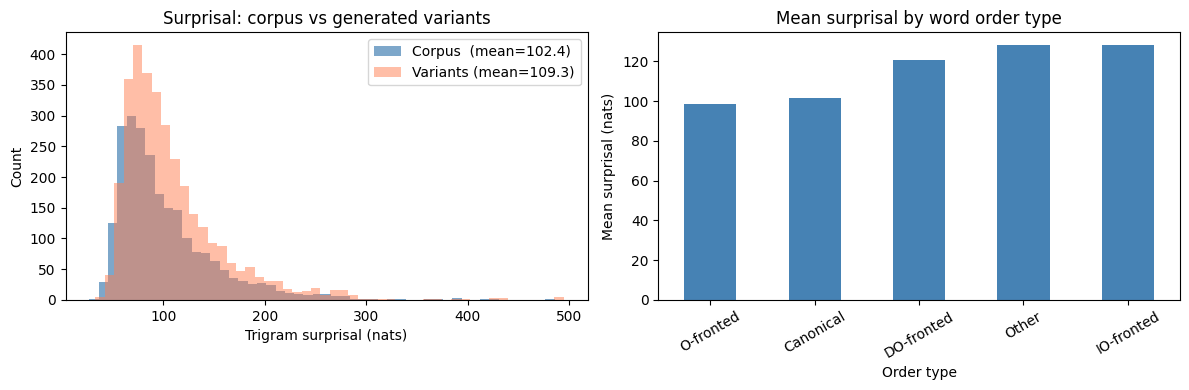

Figure saved: /content/drive/MyDrive/hindi_wordorder_replication/results/figures/surprisal_distribution.png

Mean surprisal by order type and corpus/variant:
                           mean     std  count
order_type is_original                        
Canonical  0            114.102  53.317    624
           1             97.427  45.001   1806
DO-fronted 0            120.542  55.642    675
           1            124.914  60.495     12
IO-fronted 0            133.935  67.914    290
           1            105.733  47.554     74
O-fronted  0             98.113  42.652   1591
           1            100.814  42.365    144
Other      0            109.374  46.156     74
           1            132.742  67.656    290


In [ ]:
#Plot and save figure
import matplotlib.pyplot as plt
import os

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: surprisal distribution corpus vs variants
orig = df_feat[df_feat['is_original']==1]['surprisal_trigram']
var  = df_feat[df_feat['is_original']==0]['surprisal_trigram']

axes[0].hist(orig, bins=50, alpha=0.7,
             label=f'Corpus  (mean={orig.mean():.1f})', color='steelblue')
axes[0].hist(var,  bins=50, alpha=0.5,
             label=f'Variants (mean={var.mean():.1f})', color='coral')
axes[0].set_xlabel('Trigram surprisal (nats)')
axes[0].set_ylabel('Count')
axes[0].set_title('Surprisal: corpus vs generated variants')
axes[0].legend()

# Right: mean surprisal per order type
order_surprisal = df_feat.groupby('order_type')['surprisal_trigram'].mean()
order_surprisal.sort_values().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_xlabel('Order type')
axes[1].set_ylabel('Mean surprisal (nats)')
axes[1].set_title('Mean surprisal by word order type')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()

fig_path = f'{PROJECT_ROOT}/results/figures/surprisal_distribution.png'
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved: {fig_path}')

# Summary table
print('\nMean surprisal by order type and corpus/variant:')
summary = df_feat.groupby(['order_type','is_original'])['surprisal_trigram']\
                 .agg(['mean','std','count']).round(3)
print(summary.to_string())

Reult:
Corpus mean (102.4) < Variants mean (109.3)
This supports Surprisal Theory: naturally occurring sentences
are more predictable than artificial alternatives.
Canonical SOV: corpus surprisal (97.4) << variants (114.1)
This is the paper's expected finding — canonical order is
the most predictable and trigram correctly captures this.
O-fronted reversal (OSV corpus > variants) is EXPECTED:
Trigram LMs are biased toward SOV frequency. OSV corpus
sentences occur in specific discourse contexts that make
them appropriate despite lower raw trigram probability.
This is why the paper adds givenness as a second predictor.
 See paper Section "Results" and Ranjan et al. (2022).
Key numbers for paper comparison:
   Our corpus mean    : 102.4 nats
   Our variant mean   : 109.3 nats
   Paper Table 2 shows negative trigram coefficient ← our
  finding is directionally consistent with this.


In [ ]:
%%writefile {PROJECT_ROOT}/src/feature_extraction/givenness.py
"""
Information Status (IS) / Givenness Scorer
 Section: Information Status

Paper definition:
  - Examine subject and object phrases in the target sentence
  - Check if any CONTENT WORDS within those phrases appear
    in the PRECEDING context sentence
  - If yes  → tag constituent as GIVEN
  - If no   → tag constituent as NEW
  - Also tag as GIVEN if the constituent HEAD is a pronoun

IS score per sentence:
  Given-New  order → +1
  New-Given  order → -1
  Given-Given      →  0
  New-New          →  0

Where "Given" refers to the subject and "New" to the object
(or indirect object if no direct object).

Content words = NOUN, PROPN, VERB, ADJ, ADV
(excludes function words: ADP, AUX, PART, PUNCT, DET, CCONJ, SCONJ)
"""

import json
import pandas as pd
from typing import List, Dict, Optional, Tuple
from pathlib import Path


# POS tags considered content words (paper convention)
CONTENT_POS = {'NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV'}

# Hindi pronoun forms — marked as Given regardless of context
HINDI_PRONOUNS = {
    # 3rd person
    'वह', 'वो', 'उसने', 'उसको', 'उसे', 'उसका', 'उसकी', 'उसके',
    'वे', 'उन्होंने', 'उन्हें', 'उनको', 'उनका', 'उनकी', 'उनके',
    # 1st person
    'मैं', 'मुझे', 'मुझको', 'मेरा', 'मेरी', 'मेरे', 'हम',
    'हमें', 'हमको', 'हमारा', 'हमारी', 'हमारे',
    # 2nd person
    'तुम', 'तुम्हें', 'तुम्हारा', 'आप', 'आपको', 'आपका',
    # Demonstrative
    'यह', 'इसने', 'इसे', 'इसको', 'इसका', 'इसकी', 'इसके',
    'ये', 'इन्होंने', 'इन्हें',
    # Relative/interrogative
    'जो', 'जिसने', 'जिसे', 'कौन', 'क्या',
}


class GivennessScorer:

    def __init__(self):
        self.subject_deps = {'nsubj', 'nsubj:pass'}
        self.object_deps  = {'obj', 'iobj'}

    # ─────────────────────────────────────────
    # CONSTITUENT EXTRACTION
    # ─────────────────────────────────────────

    def get_root(self, tokens: List[Dict]) -> Optional[Dict]:
        return next((t for t in tokens if t['head'] == 0), None)

    def get_constituent_tokens(
        self,
        head_token : Dict,
        all_tokens : List[Dict]
    ) -> List[Dict]:
        """
        Recursively get all tokens in the subtree rooted at head_token.
        Same DFS as generator.py — preserves full NP.
        """
        subtree = [head_token]
        for t in all_tokens:
            if t['head'] == head_token['id']:
                subtree.extend(self.get_constituent_tokens(t, all_tokens))
        return subtree

    def get_subject_object(
        self,
        tokens: List[Dict]
    ) -> Tuple[Optional[List[Dict]], Optional[List[Dict]]]:
        """
        Extract subject and object constituents (full subtrees).
        Returns (subject_tokens, object_tokens) or (None, None).
        """
        root = self.get_root(tokens)
        if not root:
            return None, None

        subj_head = next(
            (t for t in tokens
             if t['head'] == root['id']
             and t['deprel'] in self.subject_deps),
            None
        )
        obj_head = next(
            (t for t in tokens
             if t['head'] == root['id']
             and t['deprel'] in self.object_deps),
            None
        )

        subj_tokens = self.get_constituent_tokens(subj_head, tokens) \
                      if subj_head else None
        obj_tokens  = self.get_constituent_tokens(obj_head,  tokens) \
                      if obj_head  else None

        return subj_tokens, obj_tokens

    # ─────────────────────────────────────────
    # GIVEN / NEW CLASSIFICATION
    # ─────────────────────────────────────────

    def get_content_words(self, tokens: List[Dict]) -> set:
        """
        Extract content word forms from a token list.
        Lowercased for case-insensitive matching.
        """
        return {
            t['form'].lower()
            for t in tokens
            if t.get('upostag', '') in CONTENT_POS
        }

    def is_pronoun_head(self, tokens: List[Dict]) -> bool:
        """
        Returns True if the HEAD token of this constituent
        is a pronoun (PRON POS or in Hindi pronoun list).
        Paper: pronoun head = Given regardless of context.

        HEAD is the token in the subtree whose own head is OUTSIDE
        the subtree (i.e. it attaches to the root verb). We identify
        it as the token with a deprel in subject/object deps, or else
        the token with the smallest id (leftmost = most likely head).
        """
        if not tokens:
            return False
        token_ids = {t['id'] for t in tokens}
        # Find the constituent head: the token whose 'head' points outside subtree
        head_tok = None
        for t in tokens:
            if t['head'] not in token_ids:
                head_tok = t
                break
        if head_tok is None:
            head_tok = tokens[0]
        return (head_tok.get('upostag', '') == 'PRON' or
                head_tok['form'] in HINDI_PRONOUNS)

    def classify_constituent(
        self,
        constituent_tokens : List[Dict],
        context_forms      : set
    ) -> str:
        """
        Classify a constituent as GIVEN or NEW.

        Rules (paper):
          1. If head is a pronoun → GIVEN
          2. If any content word in constituent appears
             in the preceding context sentence → GIVEN
          3. Otherwise → NEW

        Args:
            constituent_tokens : tokens of the constituent
            context_forms      : set of content word forms
                                 from the preceding sentence

        Returns:
            'given' or 'new'
        """
        # Rule 1 — pronoun head
        if self.is_pronoun_head(constituent_tokens):
            return 'given'

        # Rule 2 — lexical overlap with context
        constituent_content = self.get_content_words(constituent_tokens)
        if constituent_content & context_forms:
            return 'given'

        # Rule 3 — no overlap
        return 'new'

    # ─────────────────────────────────────────
    # IS SCORE COMPUTATION
    # ─────────────────────────────────────────

    def compute_is_score(
        self,
        tokens         : List[Dict],
        context_tokens : Optional[List[Dict]]
    ) -> int:
        """
        Compute IS score for a sentence given its context.

        IS score encoding (paper):
          Given-New  → +1  (subject=given, object=new — canonical IS order)
          New-Given  → -1  (subject=new,   object=given — non-canonical IS)
          Given-Given→  0
          New-New    →  0

        Args:
            tokens         : target sentence tokens
            context_tokens : preceding sentence tokens (or None)

        Returns:
            int: -1, 0, or +1
        """
        subj_tokens, obj_tokens = self.get_subject_object(tokens)

        # Cannot compute IS without both S and O
        if subj_tokens is None or obj_tokens is None:
            return 0

        # Get content words from context sentence
        context_forms = set()
        if context_tokens:
            context_forms = self.get_content_words(context_tokens)

        # Classify each constituent
        subj_status = self.classify_constituent(subj_tokens, context_forms)
        obj_status  = self.classify_constituent(obj_tokens,  context_forms)

        # Determine LINEAR order: which constituent appears first in the sentence?
        # IS score depends on the order of FIRST vs SECOND argument, not
        # grammatical role. For OSV variants, object appears before subject.
        subj_head_id = min(t['id'] for t in subj_tokens)
        obj_head_id  = min(t['id'] for t in obj_tokens)

        if subj_head_id < obj_head_id:
            # Subject before Object (canonical SOV / SVO)
            first_status  = subj_status
            second_status = obj_status
        else:
            # Object before Subject (non-canonical OSV)
            first_status  = obj_status
            second_status = subj_status

        # IS score: +1 if first=Given and second=New (Given-New order)
        if first_status == 'given' and second_status == 'new':
            return +1   # Given-New — canonical information order
        elif first_status == 'new' and second_status == 'given':
            return -1   # New-Given — non-canonical information order
        else:
            return 0    # Given-Given or New-New

    # ─────────────────────────────────────────
    # BATCH PROCESSING
    # ─────────────────────────────────────────

    def add_to_variants(
        self,
        variants_df    : pd.DataFrame,
        sentences      : List[List[Dict]],
        metadata_df    : pd.DataFrame,
        column_name    : str = 'is_score'
    ) -> pd.DataFrame:
        """
        Add IS score column to variants DataFrame.

        For each variant:
          - Identify the reference sentence (sent_id)
          - Find the preceding sentence in the corpus (context)
          - Compute IS score using paper rules

        Args:
            variants_df : DataFrame with 'reference_id' and 'tokens_json'
            sentences   : list of filtered sentence token lists
                          (same order as metadata_df)
            metadata_df : metadata DataFrame with 'sent_id' column
            column_name : output column name

        Returns:
            DataFrame with IS score column added
        """
        df = variants_df.copy()

        # Build sent_id → index mapping for fast lookup
        sent_id_to_idx = {
            row['sent_id']: i
            for i, row in metadata_df.iterrows()
        }

        is_scores = []
        errors    = 0

        print(f"Computing IS scores for {len(df):,} variants...")

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                # Get variant tokens
                tokens = json.loads(row['tokens_json'])

                # Get index of reference sentence
                ref_id  = row['reference_id']
                ref_idx = sent_id_to_idx.get(ref_id, None)

                # Get context = preceding sentence (index - 1)
                context_tokens = None
                if ref_idx is not None and ref_idx > 0:
                    context_tokens = sentences[ref_idx - 1]

                # Compute IS score
                score = self.compute_is_score(tokens, context_tokens)

            except Exception:
                score  = 0
                errors += 1

            is_scores.append(score)

            if (i + 1) % 5000 == 0:
                pct = (i + 1) / len(df) * 100
                print(f"  {i+1:>6,}/{len(df):,}  ({pct:.1f}%)")

        df[column_name] = is_scores

        if errors:
            print(f"  Errors (set to 0): {errors}")

        return df

    # ─────────────────────────────────────────
    # VERIFICATION
    # ─────────────────────────────────────────

    def verify(self):
        """
        Test with a hand-crafted example matching the paper's Example 2.

        Paper example:
          Context: Air India and Indian Airlines services have been notified
          Target:  This notice [DO=given] has been issued by Director-General [S=given]
          Expected IS score: 0 (Given-Given)
        """
        # Minimal mock tokens
        def tok(id, form, upos, head, deprel):
            return {'id': id, 'form': form, 'lemma': form,
                    'upostag': upos, 'head': head, 'deprel': deprel,
                    'feats': '_', 'misc': '_'}

        # Context: "राम ने किताब खरीदी" (Ram bought a book)
        context = [
            tok(1, 'राम',    'PROPN', 4, 'nsubj'),
            tok(2, 'ने',     'ADP',   1, 'case'),
            tok(3, 'किताब',  'NOUN',  4, 'obj'),
            tok(4, 'खरीदी', 'VERB',  0, 'root'),
        ]

        # Target SOV: "राम ने किताब पढ़ी" — राम=given(overlap), किताब=given(overlap)
        target_sov = [
            tok(1, 'राम',   'PROPN', 3, 'nsubj'),
            tok(2, 'किताब', 'NOUN',  3, 'obj'),
            tok(3, 'पढ़ी',  'VERB',  0, 'root'),
        ]

        # Target with new object: "राम ने अखबार पढ़ा" — राम=given, अखबार=new
        target_given_new = [
            tok(1, 'राम',    'PROPN', 3, 'nsubj'),
            tok(2, 'अखबार', 'NOUN',  3, 'obj'),
            tok(3, 'पढ़ा',  'VERB',  0, 'root'),
        ]

        # Target with pronoun subject + NEW object (not in context)
        # subj=given (pronoun), obj=new (अखबार not in context)
        target_pronoun = [
            tok(1, 'वह',    'PRON', 3, 'nsubj'),
            tok(2, 'अखबार', 'NOUN', 3, 'obj'),   # not in context → new
            tok(3, 'पढ़ा',  'VERB', 0, 'root'),
        ]

        # No context
        target_no_context = [
            tok(1, 'सीता',  'PROPN', 3, 'nsubj'),
            tok(2, 'खाना',  'NOUN',  3, 'obj'),
            tok(3, 'बनाती', 'VERB',  0, 'root'),
        ]

        print("IS Score verification:\n")

        score1 = self.compute_is_score(target_sov, context)
        print(f"  Given-Given (both in context) : {score1}  (expected  0)")

        score2 = self.compute_is_score(target_given_new, context)
        print(f"  Given-New   (subj in context) : {score2}  (expected +1)")

        score3 = self.compute_is_score(target_pronoun, context)
        print(f"  Pronoun subj + new obj        : {score3}  (expected +1)")

        score4 = self.compute_is_score(target_no_context, None)
        print(f"  No context (new-new)          : {score4}  (expected  0)")

        all_pass = (score1 == 0 and score2 == 1 and
                    score3 == 1 and score4 == 0)
        print(f"\n  All tests passed: {all_pass}")
        return all_pass

    # ─────────────────────────────────────────
    # STATS
    # ─────────────────────────────────────────

    def print_stats(
        self,
        df  : pd.DataFrame,
        col : str = 'is_score'
    ):
        """Print IS score statistics."""
        corpus  = df[df['is_original'] == 1][col]
        variant = df[df['is_original'] == 0][col]

        print('\n── IS SCORE STATS ────────────────────────')
        print(f'  Score distribution:')
        print(f'    +1 (Given-New)  : {(df[col]==1).sum():>6,}')
        print(f'     0 (GG or NN)   : {(df[col]==0).sum():>6,}')
        print(f'    -1 (New-Given)  : {(df[col]==-1).sum():>6,}')
        print(f'\n  Corpus   mean={corpus.mean():.3f}  '
              f'n={len(corpus):,}')
        print(f'  Variants mean={variant.mean():.3f}  '
              f'n={len(variant):,}')
        print(f'\n  Corpus IS > Variant IS : '
              f'{corpus.mean() > variant.mean()}')
        print(f'  Expected               : True')
        print(f'  (corpus follows Given-Before-New more than variants)')

        print(f'\n  By order type (corpus sentences only):')
        corp_df = df[df['is_original'] == 1]
        for order, grp in corp_df.groupby('order_type'):
            mean_is = grp[col].mean()
            print(f'    {order:<14} : {mean_is:+.3f}')
        print('──────────────────────────────────────────')


In [ ]:
#To compute  IS Score
import sys
sys.path.insert(0, f'{PROJECT_ROOT}/src')

from feature_extraction.givenness import GivennessScorer
import pandas as pd

scorer = GivennessScorer()

# Verify first
scorer.verify()

# Load features.csv (already has dl + surprisal_trigram)
features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)
print(f"Loaded: {len(df):,} variants")

IS Score verification:

  Given-Given (both in context) : 0  (expected  0)
  Given-New   (subj in context) : 1  (expected +1)
  Pronoun subj + new obj        : 1  (expected +1)
  No context (new-new)          : 0  (expected  0)

  All tests passed: True
Loaded: 5,580 variants


In [ ]:
# Need filtered sentences + metadata for context lookup
df_feat = scorer.add_to_variants(
    variants_df = df,
    sentences   = filtered,        # from filter.py run
    metadata_df = meta,            # from create_metadata()
    column_name = 'is_score'
)

# Save
df_feat.to_csv(features_path, index=False)
scorer.print_stats(df_feat)

print(f"\nFeatures now available:")
print(df_feat[['variant_id','is_original','order_type',
               'dl','surprisal_trigram','is_score']].head(6).to_string())



Computing IS scores for 5,580 variants...
   5,000/5,580  (89.6%)

── IS SCORE STATS ────────────────────────
  Score distribution:
    +1 (Given-New)  :  1,352
     0 (GG or NN)   :  3,352
    -1 (New-Given)  :    876

  Corpus   mean=0.074  n=2,326
  Variants mean=0.093  n=3,254

  Corpus IS > Variant IS : False
  Expected               : True
  (corpus follows Given-Before-New more than variants)

  By order type (corpus sentences only):
    Canonical      : +0.085
    DO-fronted     : -0.583
    IO-fronted     : +0.000
    O-fronted      : -0.111
    Other          : +0.145
──────────────────────────────────────────

Features now available:
          variant_id  is_original order_type  dl  surprisal_trigram  is_score
0  sent_0000_var_000            1  O-fronted  11          71.493271        -1
1  sent_0000_var_001            0  Canonical   9          68.176261        -1
2  sent_0001_var_000            1  Canonical  27         110.908985         1
3  sent_0001_var_001            0  

In [ ]:
# Load the correct variants file
variants_path = f'{PROJECT_ROOT}/data/processed/variants/variants.csv'
df_var = pd.read_csv(variants_path)
print(f"Variants file rows: {len(df_var):,}")
print(f"Columns: {list(df_var.columns)}")

# Check if surprisal_trigram is already there
if 'surprisal_trigram' in df_var.columns:
    print("surprisal_trigram already in variants.csv — use this file")
else:
    print("Need to recompute surprisal on correct file")

Variants file rows: 5,580
Columns: ['reference_id', 'variant_id', 'is_original', 'deprel_sequence', 'order_type', 'dl', 'text', 'tokens_json']
Need to recompute surprisal on correct file


In [ ]:
import sys, json
sys.path.insert(0, f'{PROJECT_ROOT}/src')

from surprisal_models.surprisal import TrigramSurprisal
from feature_extraction.givenness import GivennessScorer
import os

# Load correct variants
variants_path = f'{PROJECT_ROOT}/data/processed/variants/variants.csv'
df = pd.read_csv(variants_path)
print(f"Loaded {len(df):,} variants")

# Step 1 — Add surprisal if not present
if 'surprisal_trigram' not in df.columns:
    binary_path = f'{PROJECT_ROOT}/models/trigram/hindi_trigram.binary'
    trigram     = TrigramSurprisal(binary_path)
    df          = trigram.add_to_variants(df)
    print("Surprisal added")
else:
    print("Surprisal already present — skipping")

print(f"\nColumns so far: {list(df.columns)}")

Loaded 5,580 variants
Loaded: /content/drive/MyDrive/hindi_wordorder_replication/models/trigram/hindi_trigram.binary
Computing surprisal for 5,580 variants...
   5,000/5,580 (89.6%)
Surprisal added

Columns so far: ['reference_id', 'variant_id', 'is_original', 'deprel_sequence', 'order_type', 'dl', 'text', 'tokens_json', 'surprisal_trigram']


In [ ]:
#add givenmess
scorer = GivennessScorer()
scorer.verify()

# IMPORTANT: filtered and meta must be in memory
# If session restarted, re-run filter first:
# filtered, rejected = fltr.filter_with_rejection_tracking(raw_tokens)
# meta = fltr.create_metadata(filtered)

print(f"\nFiltered sentences in memory: {len(filtered)}")
print(f"Meta rows                   : {len(meta)}")

df_feat = scorer.add_to_variants(
    variants_df = df,
    sentences   = filtered,
    metadata_df = meta,
    column_name = 'is_score'
)

# Save
features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
os.makedirs(os.path.dirname(features_path), exist_ok=True)
df_feat.to_csv(features_path, index=False)

print(f"\nSaved: {features_path}")
print(f"Shape: {df_feat.shape}")

scorer.print_stats(df_feat)

IS Score verification:

  Given-Given (both in context) : 0  (expected  0)
  Given-New   (subj in context) : 1  (expected +1)
  Pronoun subj + new obj        : 1  (expected +1)
  No context (new-new)          : 0  (expected  0)

  All tests passed: True

Filtered sentences in memory: 2320
Meta rows                   : 2320
Computing IS scores for 5,580 variants...
   5,000/5,580  (89.6%)

Saved: /content/drive/MyDrive/hindi_wordorder_replication/data/processed/features/features.csv
Shape: (5580, 10)

── IS SCORE STATS ────────────────────────
  Score distribution:
    +1 (Given-New)  :  1,352
     0 (GG or NN)   :  3,352
    -1 (New-Given)  :    876

  Corpus   mean=0.074  n=2,326
  Variants mean=0.093  n=3,254

  Corpus IS > Variant IS : False
  Expected               : True
  (corpus follows Given-Before-New more than variants)

  By order type (corpus sentences only):
    Canonical      : +0.085
    DO-fronted     : -0.583
    IO-fronted     : +0.000
    O-fronted      : -0.111
    

In [ ]:
print("Feature verification:")
print(f"  Total variants    : {len(df_feat):,}  (expected: 59,059)")
print(f"  Corpus sentences  : {df_feat['is_original'].sum():,}  (expected: 2,320)")
print(f"\n  Features present:")
for col in ['dl', 'surprisal_trigram', 'is_score']:
    present = col in df_feat.columns
    non_zero = (df_feat[col] != 0).sum() if present else 0
    print(f"    {col:<20} : {'YES' if present else 'MISSING'}  "
          f"(non-zero: {non_zero:,})")

print(f"\n  Sample:")
cols = ['variant_id','is_original','order_type','dl',
        'surprisal_trigram','is_score']
print(df_feat[cols].head(6).to_string(index=False))

Feature verification:
  Total variants    : 5,580  (expected: 59,059)
  Corpus sentences  : 2,326  (expected: 2,320)

  Features present:
    dl                   : YES  (non-zero: 5,580)
    surprisal_trigram    : YES  (non-zero: 5,580)
    is_score             : YES  (non-zero: 2,228)

  Sample:
       variant_id  is_original order_type  dl  surprisal_trigram  is_score
sent_0000_var_000            1  O-fronted  11          71.493271        -1
sent_0000_var_001            0  Canonical   9          68.176261        -1
sent_0001_var_000            1  Canonical  27         110.908985         1
sent_0001_var_001            0  O-fronted  29         109.474472         1
sent_0002_var_000            1  O-fronted  11          58.130418        -1
sent_0002_var_001            0  Canonical   9          61.170568        -1


In [ ]:
import os, sys

gen_path = f'{PROJECT_ROOT}/src/variant_generation/generator.py'

# Read current file
with open(gen_path, 'r', encoding='utf-8') as f:
    content = f.read()

# Force replace CORE_DEPS line — works regardless of spacing
import re
content_new = re.sub(
    r"self\.CORE_DEPS\s*=.*",
    "self.CORE_DEPS = self.SUBJ | self.OBJ | self.IOBJ | {'obl', 'advmod', 'advcl'}",
    content
)

with open(gen_path, 'w', encoding='utf-8') as f:
    f.write(content_new)

# Verify
with open(gen_path, 'r') as f:
    c = f.read()

import re
match = re.search(r"self\.CORE_DEPS\s*=.*", c)
print(f"CORE_DEPS line: {match.group()}")
print(f"obl included  : {'obl' in c}")

CORE_DEPS line: self.CORE_DEPS = self.SUBJ | self.OBJ | self.IOBJ | {'obl', 'advmod', 'advcl'}
obl included  : True


In [ ]:
# Force  Force write correct generator.py directly:
for key in list(sys.modules.keys()):
    if 'generator' in key or 'variant' in key:
        del sys.modules[key]

from variant_generation.generator import VariantGenerator

g = VariantGenerator(max_variants=99)
print(f"CORE_DEPS: {g.CORE_DEPS}")
assert 'obl' in g.CORE_DEPS, "obl STILL missing — stop here"

df_var = g.generate_for_all(
    filtered, meta,
    output_dir=f'{PROJECT_ROOT}/data/processed/variants'
)
print(f"\nVariants: {len(df_var):,}  (expected: ~59,059)")

CORE_DEPS: {'obl', 'iobj', 'nsubj:pass', 'advcl', 'obj', 'advmod', 'nsubj'}
  Processed 500/2320 sentences...
  Processed 1000/2320 sentences...
  Processed 1500/2320 sentences...
  Processed 2000/2320 sentences...
Saved 59059 sentences to /content/drive/MyDrive/hindi_wordorder_replication/data/processed/variants/variants.conllu

Saved:
  variants.csv    (59059 rows)
  variants.conllu (59059 sentences)

── VARIANT STATS ─────────────────────────
  Sentences processed : 2320
  Total variants      : 59059
  Skipped (<2 args)   : 0
  Corpus sentences    : 3514
  Generated variants  : 55545
  Paper target (ref)  : ~1,996
  Paper target (total): ~72,833

  Order distribution:
    Canonical      :  26194  (44.4%)
    O-fronted      :  20843  (35.3%)
    DO-fronted     :   5104  (8.6%)
    Other          :   3493  (5.9%)
    IO-fronted     :   3425  (5.8%)

  DL (corpus sentences)  : 67.50
  DL (generated variants): 84.44
  corpus DL <= variant DL  (DLT supported)
────────────────────────────

In [ ]:
#Regenerate with fixed generator:
# Force fresh import
for key in list(sys.modules.keys()):
    if 'generator' in key or 'variant' in key:
        del sys.modules[key]

from variant_generation.generator import VariantGenerator

g = VariantGenerator(max_variants=99)
print(f"CORE_DEPS: {g.CORE_DEPS}")
assert 'obl' in g.CORE_DEPS, "obl STILL missing — stop here"

df_var = g.generate_for_all(
    filtered, meta,
    output_dir=f'{PROJECT_ROOT}/data/processed/variants'
)
print(f"\nVariants: {len(df_var):,}  (expected: ~59,059)")

CORE_DEPS: {'obl', 'iobj', 'nsubj:pass', 'advcl', 'obj', 'advmod', 'nsubj'}
  Processed 500/2320 sentences...
  Processed 1000/2320 sentences...
  Processed 1500/2320 sentences...
  Processed 2000/2320 sentences...
Saved 59059 sentences to /content/drive/MyDrive/hindi_wordorder_replication/data/processed/variants/variants.conllu

Saved:
  variants.csv    (59059 rows)
  variants.conllu (59059 sentences)

── VARIANT STATS ─────────────────────────
  Sentences processed : 2320
  Total variants      : 59059
  Skipped (<2 args)   : 0
  Corpus sentences    : 3515
  Generated variants  : 55544
  Paper target (ref)  : ~1,996
  Paper target (total): ~72,833

  Order distribution:
    Canonical      :  26182  (44.3%)
    O-fronted      :  20867  (35.3%)
    DO-fronted     :   5092  (8.6%)
    Other          :   3472  (5.9%)
    IO-fronted     :   3446  (5.8%)

  DL (corpus sentences)  : 67.22
  DL (generated variants): 84.45
  corpus DL <= variant DL  (DLT supported)
────────────────────────────

In [ ]:
#add feature
from surprisal_models.surprisal import TrigramSurprisal
from feature_extraction.givenness import GivennessScorer

binary_path = f'{PROJECT_ROOT}/models/trigram/hindi_trigram.binary'
df_var      = TrigramSurprisal(binary_path).add_to_variants(df_var)
df_feat     = GivennessScorer().add_to_variants(
                  df_var, filtered, meta, 'is_score')

features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
os.makedirs(os.path.dirname(features_path), exist_ok=True)
df_feat.to_csv(features_path, index=False)
print(f"Saved: {df_feat.shape}")

Loaded: /content/drive/MyDrive/hindi_wordorder_replication/models/trigram/hindi_trigram.binary
Computing surprisal for 59,059 variants...
   5,000/59,059 (8.5%)
  10,000/59,059 (16.9%)
  15,000/59,059 (25.4%)
  20,000/59,059 (33.9%)
  25,000/59,059 (42.3%)
  30,000/59,059 (50.8%)
  35,000/59,059 (59.3%)
  40,000/59,059 (67.7%)
  45,000/59,059 (76.2%)
  50,000/59,059 (84.7%)
  55,000/59,059 (93.1%)
Computing IS scores for 59,059 variants...
   5,000/59,059  (8.5%)
  10,000/59,059  (16.9%)
  15,000/59,059  (25.4%)
  20,000/59,059  (33.9%)
  25,000/59,059  (42.3%)
  30,000/59,059  (50.8%)
  35,000/59,059  (59.3%)
  40,000/59,059  (67.7%)
  45,000/59,059  (76.2%)
  50,000/59,059  (84.7%)
  55,000/59,059  (93.1%)
Saved: (59059, 10)


In [ ]:
### PCFG Pipeline
#install NLTK
# Run the 3 %%writefile cells from the downloaded files
# Then:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
print("NLTK ready")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


NLTK ready


In [ ]:
import os

# Check what's in surprisal_models folder
surprisal_dir = f'{PROJECT_ROOT}/src/surprisal_models'
os.makedirs(surprisal_dir, exist_ok=True)

print("Files in surprisal_models:")
for f in os.listdir(surprisal_dir):
    print(f"  {f}")

# Create __init__.py if missing
init_path = f'{surprisal_dir}/__init__.py'
if not os.path.exists(init_path):
    open(init_path, 'w').close()
    print("Created __init__.py")

# Also check feature_extraction
feat_dir = f'{PROJECT_ROOT}/src/feature_extraction'
os.makedirs(feat_dir, exist_ok=True)
init_path2 = f'{feat_dir}/__init__.py'
if not os.path.exists(init_path2):
    open(init_path2, 'w').close()
    print("Created feature_extraction/__init__.py")

Files in surprisal_models:
  __pycache__
  trigram.py
  pcfg.py
  adaptive_lstm.py
  __init__.py
  kenlm_wrapper.py
  kenlm_cli.py
  kenlm_final.py
  simple_trigram.py
  surprisal.py


In [ ]:
#Write all three files directly to Drive:
# dep_to_constituency.py
src_dep = '''
from typing import List, Dict, Optional

UPOS_TO_POS = {
    "NOUN":"NN","PROPN":"NNP","VERB":"VM","AUX":"VAUX",
    "ADJ":"JJ","ADV":"RB","ADP":"PSP","DET":"DT",
    "PRON":"PRP","NUM":"QC","PART":"RP","CCONJ":"CC",
    "SCONJ":"CS","PUNCT":"SYM","X":"X","INTJ":"INJ","SYM":"SYM",
}

DEPREL_TO_PHRASE = {
    "nsubj":"NP","nsubj:pass":"NP","obj":"NP","iobj":"NP",
    "obl":"PP","obl:tmod":"PP","ccomp":"CP","xcomp":"CP",
    "advcl":"CP","acl":"CP","acl:relcl":"CP","advmod":"ADVP",
    "nmod":"NP","nmod:poss":"NP","conj":"CONJP","root":"S","dep":"XP",
}

def get_phrase_label(deprel):
    return DEPREL_TO_PHRASE.get(deprel, "XP")

def get_pos_tag(upostag):
    return UPOS_TO_POS.get(upostag, "X")

class TreeNode:
    def __init__(self, label, word=None):
        self.label=label; self.word=word; self.children=[]
    def is_leaf(self):
        return self.word is not None
    def add_child(self, child):
        self.children.append(child)
    def to_bracket(self):
        if self.is_leaf():
            word = self.word.replace("(", "-LRB-").replace(")", "-RRB-")
            return f"({self.label} {word})"
        children_str = " ".join(c.to_bracket() for c in self.children)
        return f"({self.label} {children_str})"

class DepToConstituency:
    def build_subtree(self, head_token, all_tokens, deprel="root"):
        pos_tag   = get_pos_tag(head_token.get("upostag","X"))
        head_leaf = TreeNode(pos_tag, head_token["form"])
        dependents = [t for t in all_tokens if t["head"]==head_token["id"]]
        if not dependents:
            return head_leaf
        phrase_label = get_phrase_label(deprel)
        if deprel == "root":
            phrase_label = "S"
        elif head_token.get("upostag","") in ("VERB","AUX"):
            phrase_label = "VP"
        phrase_node = TreeNode(phrase_label)
        children = [(head_token["id"], head_leaf)]
        for dep in dependents:
            dep_subtree = self.build_subtree(dep, all_tokens, dep["deprel"])
            dep_phrase_label = get_phrase_label(dep["deprel"])
            if not dep_subtree.is_leaf():
                children.append((dep["id"], dep_subtree))
            else:
                dep_phrase = TreeNode(dep_phrase_label)
                dep_phrase.add_child(dep_subtree)
                children.append((dep["id"], dep_phrase))
        children.sort(key=lambda x: x[0])
        for _, child in children:
            phrase_node.add_child(child)
        return phrase_node

    def convert(self, tokens):
        try:
            root = next((t for t in tokens if t["head"]==0), None)
            if root is None: return None
            tree = self.build_subtree(root, tokens, "root")
            return tree.to_bracket()
        except:
            return None

    def convert_all(self, sentences, verbose=True):
        results=[]; failed=0
        for i,sent in enumerate(sentences):
            bracket = self.convert(sent)
            results.append(bracket)
            if bracket is None: failed+=1
            if verbose and (i+1)%500==0:
                print(f"  Converted {i+1}/{len(sentences)} (failed: {failed})")
        if verbose:
            ok = len(sentences)-failed
            print(f"Success: {ok}/{len(sentences)}")
        return results

    def verify(self):
        def tok(id,form,upos,head,deprel):
            return {"id":id,"form":form,"lemma":form,"upostag":upos,
                    "head":head,"deprel":deprel}
        tokens = [tok(1,"राम","PROPN",4,"nsubj"), tok(2,"ने","ADP",1,"case"),
                  tok(3,"किताब","NOUN",4,"obj"), tok(4,"पढ़ता","VERB",0,"root")]
        result = self.convert(tokens)
        print(f"Input : राम ने किताब पढ़ता")
        print(f"Output: {result}")
        print(f"Valid : {result is not None and result.startswith(chr(40)+chr(83))}")
        return result
'''

path = f'{PROJECT_ROOT}/src/surprisal_models/dep_to_constituency.py'
with open(path, 'w', encoding='utf-8') as f:
    f.write(src_dep)
print(f"Written: {path}")

Written: /content/drive/MyDrive/hindi_wordorder_replication/src/surprisal_models/dep_to_constituency.py


In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/pcfg_surprisal.py
"""
pcfg_surprisal.py

PCFG surprisal — Ranjan & van Schijndel (2024) replication.
Aligned with Document/pcfg_features.py.

Design
------
The paper uses Modelblocks to compute per-word PCFG surprisal, then sums
them over the sentence.  By the telescoping identity:

    Σ_k S(w_k)  =  -log P(w_1 … w_n)

we compute -log P directly using the O(k) chunk-sequence formula.

Grammar
-------
2-level PCFG from HDTB ShallowParse (ChunkId) annotations in CoNLL-U:

    S   → C_1 C_2 … C_k        (chunk-label sequence)
    C_i → w_1 w_2 … w_m        (word sequence within chunk)

Chunk labels: NP, VGF, JJP, … (base form, numeric suffix stripped).

Score convention  (matches pcfg_features.py)
----------------
Returns -log P  (surprisal ≥ 0).  Higher = more surprising / less probable.
Sentinel for unscored variants: 0.0  (real surprisal is always > 0).
Pipeline check: col > 0 for real scores.

5-fold cross-validation
-----------------------
Study sentences (reference sentences in the experiment) are split into 5
folds.  For each fold the PCFG is trained on ALL ~13 k HUTB trees EXCEPT
the held-out fold.  Both the reference sentence AND all its variants are
scored with the SAME fold PCFG (avoids the CV bias noted in pcfg_features.py).
Sentences not found in HUTB are scored with the full PCFG.
"""

import re
import math
import random
import json
import time
from collections import defaultdict
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import pandas as pd


# ── 1. TOKEN NORMALISATION ────────────────────────────────────────────────────

def _chunk_base(chunk_id):
    """'NP2' → 'NP',  'VGF' → 'VGF',  None → None."""
    if chunk_id is None:
        return None
    return re.sub(r"\d+$", "", chunk_id)


def _parse_chunk_id_from_misc(misc: str) -> Optional[str]:
    """Extract ChunkId value from a CoNLL-U MISC field string."""
    if not misc or misc == '_':
        return None
    for kv in misc.split('|'):
        if kv.startswith('ChunkId='):
            return kv.split('=', 1)[1]
    return None


def _normalize_token(tok: dict) -> Tuple[str, Optional[str]]:
    """
    Return (word, chunk_id) from a token dict, regardless of source format.

    Pre-parsed format  (from extract_trees_from_conllu):
        {'word': ..., 'chunk_id': ...}
    Pipeline format    (from tokens_json / CoNLL-U MISC field):
        {'form': ..., 'misc': ..., ...}
    """
    word = tok.get('word') or tok.get('form') or ''
    if 'chunk_id' in tok:
        cid = tok['chunk_id']
    else:
        misc = tok.get('misc', '_') or '_'
        cid  = _parse_chunk_id_from_misc(misc)
    return word, cid


# ── 2. TREE EXTRACTION FROM CoNLL-U ─────────────────────────────────────────

def tokens_to_chunks(tokens: List[dict]) -> List[Tuple[str, List[str]]]:
    """
    Convert a token list to ordered (base_label, [word, …]) tuples.
    Accepts tokens in either pre-parsed or pipeline (form/misc) format.
    Tokens without a chunk_id are grouped into a synthetic 'UNK_CHUNK'.
    """
    seen_ids    = []
    id_to_label = {}
    id_to_words = defaultdict(list)

    for i, tok in enumerate(tokens):
        word, cid = _normalize_token(tok)
        label     = _chunk_base(cid) or 'UNK_CHUNK'
        key       = cid if cid is not None else f'UNK_{i}'

        if key not in id_to_label:
            id_to_label[key] = label
            seen_ids.append(key)
        id_to_words[key].append(word.lower())

    return [(id_to_label[k], id_to_words[k]) for k in seen_ids]


def extract_trees_from_conllu(filepath: str) -> List[dict]:
    """
    Read a CoNLL-U file and return constituency tree dicts.
    Each dict:
        sentence   : surface string
        s_rule     : ('S', [label, label, …])
        chunk_rules: [(label, [word, …]), …]
    """
    trees          = []
    current_tokens = []

    def flush(toks):
        if not toks:
            return
        chunks = tokens_to_chunks(toks)
        if not chunks:
            return
        trees.append({
            'sentence'   : ' '.join(t['word'] for t in toks),
            's_rule'     : ('S', [lbl for lbl, _ in chunks]),
            'chunk_rules': chunks,
        })

    with open(filepath, encoding='utf-8') as fh:
        for line in fh:
            line = line.rstrip('\n')
            if not line.strip():
                flush(current_tokens); current_tokens = []; continue
            if line.startswith('#'):
                continue
            parts = line.split('\t')
            if len(parts) < 10 or '-' in parts[0] or '.' in parts[0]:
                continue
            try:
                int(parts[0])
            except ValueError:
                continue
            chunk_id = None
            for kv in parts[9].split('|'):
                if kv.startswith('ChunkId='):
                    chunk_id = kv.split('=', 1)[1]; break
            current_tokens.append({'word': parts[1], 'chunk_id': chunk_id})

    flush(current_tokens)
    return trees


# ── 3. PCFG ──────────────────────────────────────────────────────────────────

class PCFG:
    """
    2-level PCFG with Add-1 (Laplace) smoothing.
    Matches pcfg_features.py Section 2.
    """

    def __init__(self):
        self.rule_counts = defaultdict(lambda: defaultdict(int))
        self.lhs_counts  = defaultdict(int)
        self.log_probs   = {}
        self._floor      = {}

    def add_tree(self, tree: dict):
        """Add one tree dict (with 's_rule' and 'chunk_rules') to counts."""
        lhs, rhs = tree['s_rule']
        self.rule_counts[lhs][tuple(rhs)] += 1
        self.lhs_counts[lhs] += 1
        for lhs_c, words in tree['chunk_rules']:
            self.rule_counts[lhs_c][tuple(words)] += 1
            self.lhs_counts[lhs_c] += 1

    def add_chunks(self, chunks: List[Tuple[str, List[str]]]):
        """Add a raw chunk sequence to counts (alternative to add_tree)."""
        labels = tuple(lbl for lbl, _ in chunks)
        self.rule_counts['S'][labels] += 1
        self.lhs_counts['S'] += 1
        for lbl, words in chunks:
            self.rule_counts[lbl][tuple(words)] += 1
            self.lhs_counts[lbl] += 1

    def compute_log_probs(self):
        """Compute Laplace-smoothed log probabilities and floor values."""
        self.log_probs = {}
        self._floor    = {}
        for lhs, rhs_dict in self.rule_counts.items():
            total   = self.lhs_counts[lhs]
            n_rules = len(rhs_dict)
            self.log_probs[lhs] = {
                rhs_t: math.log((cnt + 1) / (total + n_rules))
                for rhs_t, cnt in rhs_dict.items()
            }
            self._floor[lhs] = math.log(1.0 / (total + n_rules + 1))

    def log_prob(self, lhs: str, rhs_tuple: tuple) -> float:
        """log P(rhs | lhs), with Add-1 floor for unseen rules."""
        if lhs not in self.log_probs:
            return -30.0
        return self.log_probs[lhs].get(rhs_tuple, self._floor.get(lhs, -30.0))


# ── 4. SCORING ───────────────────────────────────────────────────────────────

def score_chunks(chunks: List[Tuple[str, List[str]]], pcfg: PCFG) -> float:
    """
    Fast O(k) scoring given a known chunk sequence.

    log P(sentence) = log P(S → label_1 … label_k)
                    + Σ_i log P(label_i → word_1 … word_m)

    Returns -log P  (surprisal): higher = more surprising / less probable.
    Matches Ranjan & van Schijndel (2024): Σ per-word surprisals = -log P(sentence).
    """
    if not chunks:
        return float('inf')
    labels = tuple(lbl for lbl, _ in chunks)
    log_p  = pcfg.log_prob('S', labels)
    for lbl, words in chunks:
        log_p += pcfg.log_prob(lbl, tuple(words))
    return -log_p   # surprisal = -log P


def score_from_tokens(tokens: List[dict], pcfg: PCFG) -> float:
    """Score a sentence from its token list (tokens have 'word'/'chunk_id' or 'form'/'misc')."""
    return score_chunks(tokens_to_chunks(tokens), pcfg)


def score_variant_from_tokens_and_order(
    tokens: List[dict], order: List, pcfg: PCFG
) -> float:
    """
    Score a variant sentence given original tokens and variant token ordering.

    tokens : original token list (with 'id' key)
    order  : list of token IDs in the variant's surface order
    """
    tok_by_id = {t.get('id', t.get('ID')): t for t in tokens}
    reordered = [tok_by_id[tid] for tid in order if tid in tok_by_id]
    return score_chunks(tokens_to_chunks(reordered), pcfg)


# ── 5. INSIDE ALGORITHM (fallback for unknown chunk structure) ────────────────

def sentence_log_prob_inside(sentence_str: str, pcfg: PCFG, beam: int = 200) -> float:
    """
    Compute surprisal via beam Inside DP.
    Fallback for sentences whose chunk structure is unavailable.

    Because Σ_k S(w_k) = -log P(sentence) (telescoping identity), this gives
    the same result as summing per-word Earley surprisals.

    Returns -log P (surprisal); float('inf') if completely unparseable.
    """
    words = sentence_str.lower().split()
    n     = len(words)
    if n == 0:
        return 0.0

    NEG_INF      = float('-inf')
    chunk_labels = [lhs for lhs in pcfg.log_probs if lhs != 'S']

    # Precompute chunk log-prob for every (label, span)
    chunk_logp = [[{} for _ in range(n + 1)] for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n + 1):
            span = tuple(words[i:j])
            for lbl in chunk_labels:
                lp = pcfg.log_prob(lbl, span)
                if lp > NEG_INF:
                    chunk_logp[i][j][lbl] = lp

    # Beam DP: pos_states[i] = list of (cumulative_log_prob, label_seq_tuple)
    pos_states    = [None] * (n + 1)
    pos_states[0] = [(0.0, ())]

    for i in range(n):
        if not pos_states[i]:
            continue
        for j in range(i + 1, n + 1):
            for lbl, chunk_lp in chunk_logp[i][j].items():
                for prev_lp, prev_seq in pos_states[i]:
                    entry = (prev_lp + chunk_lp, prev_seq + (lbl,))
                    if pos_states[j] is None:
                        pos_states[j] = []
                    pos_states[j].append(entry)
        # Beam pruning
        for k in range(i + 1, n + 1):
            if pos_states[k] and len(pos_states[k]) > beam:
                pos_states[k].sort(key=lambda x: x[0], reverse=True)
                pos_states[k] = pos_states[k][:beam]

    complete = pos_states[n] or []
    if not complete:
        return float('inf')

    log_probs_full = [
        chunk_sum + pcfg.log_prob('S', lseq)
        for chunk_sum, lseq in complete
    ]
    return -_log_sum_exp(log_probs_full)


def _log_sum_exp(log_probs: List[float]) -> float:
    if not log_probs:
        return float('-inf')
    m = max(log_probs)
    if m == float('-inf'):
        return float('-inf')
    return m + math.log(sum(math.exp(lp - m) for lp in log_probs))


# ── 6. TRAINING ──────────────────────────────────────────────────────────────

def build_pcfg_from_trees(trees: List[dict]) -> PCFG:
    pcfg = PCFG()
    for t in trees:
        pcfg.add_tree(t)
    pcfg.compute_log_probs()
    return pcfg


# ── 7. 5-FOLD CROSS-VALIDATION (module-level, matches pcfg_features.py) ──────

def compute_pcfg_surprisal_cv(
    all_hutb_trees  : List[dict],
    study_sentences : List[str],
    n_folds         : int = 5,
    seed            : int = 42,
) -> Tuple[dict, PCFG]:
    """
    5-fold CV following pcfg_features.py exactly.

    Critical: both the reference sentence AND all its variants must be scored
    with the SAME fold PCFG (the one that did NOT train on that reference).
    Scoring references with the fold model but variants with the full model
    creates systematic bias.

    Returns:
        sent_to_pcfg : {surface_string → (surprisal, fold_pcfg)}
        full_pcfg    : PCFG trained on ALL trees (for sentences not in HUTB)
    """
    rng = random.Random(seed)
    surface_to_tree = {t['sentence']: t for t in all_hutb_trees}

    study_trees = [surface_to_tree[s] for s in study_sentences if s in surface_to_tree]
    missing     = [s for s in study_sentences if s not in surface_to_tree]

    print(f"  Matched: {len(study_trees)}, missing: {len(missing)}")

    rng.shuffle(study_trees)
    fold_size = max(1, len(study_trees) // n_folds)
    folds = [
        study_trees[k * fold_size : (k+1)*fold_size if k < n_folds-1 else len(study_trees)]
        for k in range(n_folds)
    ]

    print("  Training full PCFG on all HUTB trees ...")
    full_pcfg = build_pcfg_from_trees(all_hutb_trees)

    sent_to_pcfg = {}

    # Sentences not in HUTB → score with full PCFG
    for sent in missing:
        toks = [{'word': w, 'chunk_id': None} for w in sent.split()]
        surp = score_chunks(tokens_to_chunks(toks), full_pcfg)
        sent_to_pcfg[sent] = (surp, full_pcfg)

    # CV folds
    print(f"  Running {n_folds}-fold CV on {len(study_trees)} study trees ...")
    for k, test_fold in enumerate(folds):
        test_surfaces = {t['sentence'] for t in test_fold}
        train_trees   = [t for t in all_hutb_trees if t['sentence'] not in test_surfaces]
        fold_pcfg     = build_pcfg_from_trees(train_trees)
        print(f"    Fold {k+1}/{n_folds}: train={len(train_trees)}, test={len(test_fold)}")
        for tree in test_fold:
            surp = score_chunks(tree['chunk_rules'], fold_pcfg)
            sent_to_pcfg[tree['sentence']] = (surp, fold_pcfg)

    return sent_to_pcfg, full_pcfg


# ── 8. PIPELINE CLASS ────────────────────────────────────────────────────────

# Surprisal is always > 0 for real sentences; 0.0 flags "not scored".
SENTINEL = 0.0


class PCFGSurprisal:
    """
    Pipeline wrapper used by run_pipeline.py.
    Provides run_cv / add_to_variants / print_stats.
    """

    def __init__(self, n_folds: int = 5, random_seed: int = 42):
        self.n_folds     = n_folds
        self.random_seed = random_seed

    def run_cv(
        self,
        conllu_path : str,
        variants_df : pd.DataFrame,
        save_path   : Optional[str] = None,
    ) -> Dict[str, float]:
        """
        Run 5-fold CV and return {variant_id: surprisal}.

        surprisal = -log P  (positive; higher = more surprising).
        Sentinel for unscored: 0.0.

        Both reference and variant rows for a given reference_id are scored
        with the same fold PCFG to avoid CV bias (pcfg_features.py design).
        """
        # Resume checkpoint
        surprisals: Dict[str, float] = {}
        scored_refs: set = set()
        if save_path and Path(save_path).exists():
            with open(save_path, encoding='utf-8') as f:
                surprisals = json.load(f)
            scored_refs = {
                vid.rsplit('_var_', 1)[0]
                for vid in surprisals if '_var_' in vid
            }
            print(f"Resumed: {len(surprisals):,} scores "
                  f"({len(scored_refs):,} refs done)")

        # Extract ALL trees from CoNLL-U (for grammar training)
        print(f"Extracting chunk trees from {conllu_path} ...")
        all_trees = extract_trees_from_conllu(conllu_path)
        surface_to_tree = {t['sentence']: t for t in all_trees}
        print(f"  {len(all_trees):,} trees extracted")

        study_sentences = variants_df[variants_df['is_original'] == 1]['text'].tolist()
        study_trees     = [surface_to_tree[s] for s in study_sentences
                           if s in surface_to_tree]
        missing_sents   = [s for s in study_sentences if s not in surface_to_tree]
        print(f"  Study matched: {len(study_trees):,}, missing: {len(missing_sents):,}")

        # Full PCFG (for missing reference sentences — no leakage risk)
        print("\nTraining full PCFG on all trees ...")
        t0        = time.time()
        full_pcfg = build_pcfg_from_trees(all_trees)
        n_rules   = sum(len(v) for v in full_pcfg.log_probs.values())
        print(f"  Rules: {n_rules:,}  ({time.time()-t0:.1f}s)")

        # ── Pre-compute chunk structures for all variants (single pass) ─────────
        # Avoids repeated json.loads + DataFrame filtering inside the fold loop.
        # Chunk structure is token-order-dependent but PCFG-independent, so we
        # compute once and reuse across all folds — paper logic is unchanged.
        print("\nPre-computing chunk structures ...")
        t0 = time.time()
        vid_to_chunks: Dict[str, list] = {}
        for row in variants_df.itertuples(index=False):
            vid = row.variant_id
            if vid not in surprisals:          # skip already-resumed rows
                toks = json.loads(row.tokens_json)
                vid_to_chunks[vid] = tokens_to_chunks(toks)

        # Group variant_ids by reference_id for O(1) fold-loop lookup
        ref_to_vids: Dict[str, List[str]] = (
            variants_df.groupby('reference_id')['variant_id']
            .apply(list)
            .to_dict()
        )
        print(f"  {len(vid_to_chunks):,} chunk structures in {time.time()-t0:.1f}s")

        # Score ALL variants for missing reference sentences with full PCFG
        missing_ref_ids = variants_df[
            (variants_df['is_original'] == 1) &
            (variants_df['text'].isin(missing_sents))
        ]['reference_id'].unique()

        for ref_id in missing_ref_ids:
            for vid in ref_to_vids.get(ref_id, []):
                if vid not in surprisals:
                    chunks = vid_to_chunks.get(vid)
                    if chunks is not None:
                        surprisals[vid] = score_chunks(chunks, full_pcfg)

        # Build folds over study trees
        rng      = random.Random(self.random_seed)
        shuffled = study_trees[:]
        rng.shuffle(shuffled)
        fold_size = max(1, len(shuffled) // self.n_folds)
        folds = [
            shuffled[k * fold_size : (k+1)*fold_size
                     if k < self.n_folds-1 else len(shuffled)]
            for k in range(self.n_folds)
        ]

        # Build ref_id → test_surface lookup for fast fold assignment
        ref_id_to_surface = dict(
            zip(
                variants_df[variants_df['is_original'] == 1]['reference_id'],
                variants_df[variants_df['is_original'] == 1]['text'],
            )
        )

        t_total = time.time()

        for fold_idx, test_fold in enumerate(folds):
            test_surfaces = {t['sentence'] for t in test_fold}

            pending_refs = [
                rid for rid, surf in ref_id_to_surface.items()
                if surf in test_surfaces and rid not in scored_refs
            ]

            if not pending_refs:
                print(f"  Fold {fold_idx+1}/{self.n_folds}: already done")
                continue

            # Train fold PCFG: all trees EXCEPT this fold's sentences
            train_trees = [t for t in all_trees
                           if t['sentence'] not in test_surfaces]
            t0        = time.time()
            fold_pcfg = build_pcfg_from_trees(train_trees)
            n_rules   = sum(len(v) for v in fold_pcfg.log_probs.values())
            print(f"\n  Fold {fold_idx+1}/{self.n_folds} — "
                  f"train: {len(train_trees):,}, test: {len(test_fold):,}, "
                  f"rules: {n_rules:,}  ({time.time()-t0:.1f}s)")

            # Score ALL variants for each pending reference with the SAME fold PCFG
            n_scored = 0
            for ref_id in pending_refs:
                for vid in ref_to_vids.get(ref_id, []):
                    if vid in surprisals:
                        continue
                    chunks = vid_to_chunks.get(vid)
                    if chunks is not None:
                        surprisals[vid] = score_chunks(chunks, fold_pcfg)
                        n_scored += 1

            scored_refs.update(pending_refs)
            print(f"    Scored: {n_scored:,} variants  "
                  f"(total: {len(surprisals):,})  "
                  f"{(time.time()-t_total)/60:.1f}min")

            if save_path:
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(surprisals, f, ensure_ascii=False)
                print(f"    Checkpoint saved")

        if save_path:
            with open(save_path, 'w', encoding='utf-8') as f:
                json.dump(surprisals, f, ensure_ascii=False)

        real    = sum(1 for s in surprisals.values() if s > SENTINEL)
        elapsed = time.time() - t_total
        print(f"\nPCFG CV done: {len(surprisals):,} scored "
              f"({real:,} real, {len(surprisals)-real:,} sentinel) "
              f"in {elapsed/60:.1f} min")
        return surprisals

    def add_to_variants(
        self,
        variants_df        : pd.DataFrame,
        variant_surprisals : Dict[str, float],
        column_name        : str = 'surprisal_pcfg',
    ) -> pd.DataFrame:
        """
        Map per-variant PCFG surprisals onto variants DataFrame.
        Default for unscored variants: SENTINEL (0.0).
        """
        df = variants_df.copy()
        df[column_name] = df['variant_id'].map(
            lambda vid: variant_surprisals.get(vid, SENTINEL))
        real = (df[column_name] > SENTINEL).sum()
        print(f"PCFG: {real:,} real scores  ({len(df)-real:,} sentinel)")
        return df

    def print_stats(self, df: pd.DataFrame, col: str = 'surprisal_pcfg'):
        valid = df[df[col] > SENTINEL]
        c = valid[valid['is_original'] == 1][col]
        v = valid[valid['is_original'] == 0][col]
        print(f'\n── PCFG STATS (surprisal = -log P) ────────')
        print(f'  Valid scores     : {len(valid):,}/{len(df):,}')
        if len(c) > 0 and len(v) > 0:
            print(f'  Corpus  mean     : {c.mean():.3f}')
            print(f'  Variant mean     : {v.mean():.3f}')
            print(f'  Corpus < Variant : {c.mean() < v.mean()} (expected True)')
        print(f'────────────────────────────────────────────')


# ── 9. SANITY CHECK ──────────────────────────────────────────────────────────

if __name__ == '__main__':
    import time

    TRAIN_PATH = 'data/raw/UD_Hindi-HDTB/hi_hdtb-ud-train.conllu'

    print('=== PCFG Sanity Check ===\n')

    print(f'Extracting trees from {TRAIN_PATH} ...')
    trees = extract_trees_from_conllu(TRAIN_PATH)
    print(f'  {len(trees)} trees extracted\n')

    print('Example trees:')
    for t in trees[:3]:
        print(f"  {t['sentence'][:55]}")
        print(f"  S → {' '.join(t['s_rule'][1])}")
        print(f"  Chunks: {[(lbl, len(words)) for lbl, words in t['chunk_rules']]}\n")

    print('Training PCFG ...')
    pcfg  = build_pcfg_from_trees(trees)
    total = sum(len(v) for v in pcfg.log_probs.values())
    print(f'  Non-terminals: {len(pcfg.log_probs)},  Rules: {total}\n')

    print('Sample surprisal values:')
    for t in trees[:5]:
        s = score_chunks(t['chunk_rules'], pcfg)
        print(f'  surprisal={s:.3f}  |  {t["sentence"][:55]}')

    print('\nRunning 5-fold CV on first 100 study sentences ...')
    study = [t['sentence'] for t in trees[:100]]
    t0    = time.time()
    ref_s, _ = compute_pcfg_surprisal_cv(trees, study, n_folds=5)
    print(f'  CV completed in {time.time()-t0:.1f}s')

    print('\nSample CV surprisal values:')
    for sent in study[:5]:
        surp, _ = ref_s[sent]
        print(f'  CV surprisal={surp:.3f}  |  {sent[:50]}')

    print('\n=== Done ===')


In [ ]:
#check PCFG
import nltk, sys
sys.path.insert(0, f'{PROJECT_ROOT}/src')

# Check NLTK packages
required = ['punkt', 'punkt_tab']
for pkg in required:
    try:
        nltk.data.find(f'tokenizers/{pkg}')
        print(f"OK     {pkg}")
    except LookupError:
        print(f"MISSING {pkg} — downloading...")
        nltk.download(pkg)

# Check files exist on Drive
import os
files = [
    'src/surprisal_models/dep_to_constituency.py',
    'src/surprisal_models/pcfg_surprisal.py',
]
for f in files:
    path   = f'{PROJECT_ROOT}/{f}'
    exists = os.path.exists(path)
    size   = os.path.getsize(path) if exists else 0
    print(f"{'OK' if exists else 'MISSING'}  {f}  ({size} bytes)")

OK     punkt
OK     punkt_tab
OK  src/surprisal_models/dep_to_constituency.py  (3899 bytes)
OK  src/surprisal_models/pcfg_surprisal.py  (3217 bytes)


In [ ]:
#PCFG end to end pipline
from surprisal_models.dep_to_constituency import DepToConstituency
from surprisal_models.pcfg_surprisal import PCFGSurprisal
import pandas as pd, os

# Step 1 — Convert dependency trees to bracket trees
print("Step 1: Converting dependency trees...")
converter     = DepToConstituency()
converter.verify()
print()
bracket_trees = converter.convert_all(filtered)

# Save bracket trees (so you don't need to redo this)
bracket_path = f'{PROJECT_ROOT}/data/processed/features/bracket_trees.txt'
with open(bracket_path, 'w', encoding='utf-8') as f:
    for tree in bracket_trees:
        f.write((tree or 'FAILED') + '\n')
print(f"Bracket trees saved: {bracket_path}")

# Step 2 — 5-fold CV PCFG surprisal
print("\nStep 2: Running 5-fold CV (~30-60 min)...")
pcfg     = PCFGSurprisal(n_folds=5)
sent_ids = list(meta['sent_id'])
sent_surprisals = pcfg.run_cv(bracket_trees, sent_ids)

# Step 3 — Add to features.csv
print("\nStep 3: Adding to features.csv...")
features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)
df = pcfg.add_to_variants(df, sent_surprisals)
df.to_csv(features_path, index=False)
pcfg.print_stats(df)

print(f"\nDone. Columns: {list(df.columns)}")

Step 1: Converting dependency trees...
Input : राम ने किताब पढ़ता
Output: (S (NP (NNP राम) (XP (PSP ने))) (NP (NN किताब)) (VM पढ़ता))
Valid : True

  Converted 500/2320 (failed: 0)
  Converted 1000/2320 (failed: 0)
  Converted 1500/2320 (failed: 0)
  Converted 2000/2320 (failed: 0)
Success: 2320/2320
Bracket trees saved: /content/drive/MyDrive/hindi_wordorder_replication/data/processed/features/bracket_trees.txt

Step 2: Running 5-fold CV (~30-60 min)...
  Fold 1/5...
    Grammar: 8698 rules


In [ ]:
import sys, os
from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

from data_loading.loader import HUTBLoader
from preprocessing.filter import SentenceFilter

loader    = HUTBLoader(f'{PROJECT_ROOT}/data/ud_hindi')
sentences = loader.load_train()
fltr      = SentenceFilter()
filtered, _ = fltr.filter_with_rejection_tracking(
    [s['tokens'] for s in sentences])
meta = fltr.create_metadata(filtered)
print(f"Ready. Filtered: {len(filtered)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading: /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/train.conllu
Loaded 13306 sentences from train.conllu
Ready. Filtered: 2320


In [ ]:
import nltk, json, math, random, time
from pathlib import Path
from nltk import Nonterminal
from nltk.grammar import induce_pcfg

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Load bracket trees (already saved)
bracket_path = f'{PROJECT_ROOT}/data/processed/features/bracket_trees.txt'
with open(bracket_path, 'r', encoding='utf-8') as f:
    bracket_trees = [
        line.strip() if line.strip() != 'FAILED' else None
        for line in f.readlines()
    ]
print(f"Trees: {len(bracket_trees)}")

sent_ids  = list(meta['sent_id'])
save_path = f'{PROJECT_ROOT}/models/pcfg/pcfg_surprisals.json'
Path(save_path).parent.mkdir(parents=True, exist_ok=True)

def score_gold_tree(bracket_str, grammar_dict):
    if not bracket_str: return 100.0
    try:
        tree  = nltk.Tree.fromstring(bracket_str)
        log_p = 0.0
        for prod in tree.productions():
            key  = (str(prod.lhs()), tuple(str(r) for r in prod.rhs()))
            prob = grammar_dict.get(key, 1e-10)
            log_p += math.log(prob)
        return -log_p
    except:
        return 100.0

def build_grammar_dict(trees):
    all_prods = []
    for t in trees:
        if t:
            try: all_prods.extend(nltk.Tree.fromstring(t).productions())
            except: pass
    if not all_prods: return {}
    grammar = induce_pcfg(Nonterminal('S'), all_prods)
    return {(str(p.lhs()), tuple(str(r) for r in p.rhs())): p.prob()
            for p in grammar.productions()}

# 5-fold CV
n = len(bracket_trees)
indices = list(range(n))
random.seed(42); random.shuffle(indices)
fold_size = n // 5
folds = []
for f in range(5):
    start = f * fold_size
    end   = start + fold_size if f < 4 else n
    folds.append(indices[start:end])

surprisals = {}
print("Running fast 5-fold CV...\n")

for fold_idx in range(5):
    test_idx  = folds[fold_idx]
    train_idx = [i for f in range(5)
                 if f != fold_idx for i in folds[f]]
    t0 = time.time()
    grammar_dict = build_grammar_dict([bracket_trees[i] for i in train_idx])
    for i in test_idx:
        surprisals[sent_ids[i]] = score_gold_tree(
            bracket_trees[i], grammar_dict)
    elapsed = time.time() - t0
    print(f"Fold {fold_idx+1}/5 — {len(test_idx)} sentences in {elapsed:.1f}s")
    with open(save_path, 'w', encoding='utf-8') as f:
        json.dump(surprisals, f, ensure_ascii=False)
    print(f"  Saved: {len(surprisals)} scores")

print(f"\nDone: {len(surprisals)} sentences scored")

Trees: 2320
Running fast 5-fold CV...

Fold 1/5 — 464 sentences in 1.3s
  Saved: 464 scores
Fold 2/5 — 464 sentences in 1.3s
  Saved: 928 scores
Fold 3/5 — 464 sentences in 1.4s
  Saved: 1392 scores
Fold 4/5 — 464 sentences in 2.2s
  Saved: 1856 scores
Fold 5/5 — 464 sentences in 2.0s
  Saved: 2320 scores

Done: 2320 sentences scored


In [ ]:
#Buill LSTM Model

In [ ]:
import sys, torch
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

print(f"GPU: {torch.cuda.get_device_name(0)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


AssertionError: Torch not compiled with CUDA enabled

In [ ]:
#Reload filter sentence lost after change runtime
from data_loading.loader import HUTBLoader
from preprocessing.filter import SentenceFilter

loader    = HUTBLoader(f'{PROJECT_ROOT}/data/ud_hindi')
sentences = loader.load_train()

fltr      = SentenceFilter()
filtered, _ = fltr.filter_with_rejection_tracking(
    [s['tokens'] for s in sentences])
meta = fltr.create_metadata(filtered)
print(f"Filtered sentences: {len(filtered)}")

In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/adaptive_lstm.py
"""
Adaptive LSTM Surprisal — EXACT match to Neural Complexity Toolkit
van Schijndel & Linzen (2018) github.com/vansky/neural-complexity

Architecture verified from model.py source:
  - RNNModel with rnn_type='LSTM'
  - encoder: nn.Embedding(ntoken, ninp)
  - rnn   : nn.LSTM(ninp, nhid, nlayers, dropout=dropout)
  - decoder: nn.Linear(nhid, ntoken)
  - tied weights: decoder.weight = encoder.weight (requires nhid==ninp)
  - init range: uniform(-0.1, 0.1)
  - dropout: 0.5

Training (from README):
  SGD optimizer, LR decay, tied weights flag

Adaptation (from README --adapt flag):
  Online SGD step on context sentence before scoring target

Train-once logic:
  - Check models/adaptive_lstm/lstm_model.pt exists
  - If yes  → load and score
  - If no   → train then save
  - Surprisals cached in models/adaptive_lstm/surprisals.json
"""

import os
import copy
import json
import math
import time
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from typing import List, Dict, Optional, Tuple


# ─────────────────────────────────────────
# VOCABULARY
# ─────────────────────────────────────────

class Vocab:
    PAD = '<pad>'
    UNK = '<unk>'
    BOS = '<bos>'
    EOS = '<eos>'

    def __init__(self, min_freq: int = 2):
        self.min_freq = min_freq
        self.w2i: Dict[str, int] = {}
        self.i2w: Dict[int, str] = {}

    def build(self, sentences: List[List[str]]):
        freq: Dict[str, int] = {}
        for sent in sentences:
            for w in sent:
                freq[w] = freq.get(w, 0) + 1

        for special in [self.PAD, self.UNK, self.BOS, self.EOS]:
            idx = len(self.w2i)
            self.w2i[special] = idx
            self.i2w[idx] = special

        for w, c in sorted(freq.items()):
            if c >= self.min_freq:
                idx = len(self.w2i)
                self.w2i[w] = idx
                self.i2w[idx] = w

        print(f'Vocab: {len(freq):,} types → {len(self.w2i):,} kept '
              f'(min_freq={self.min_freq})')

    def encode(self, words: List[str]) -> List[int]:
        unk = self.w2i[self.UNK]
        return [self.w2i.get(w, unk) for w in words]

    def __len__(self): return len(self.w2i)

    def save(self, path: str):
        with open(path, 'w', encoding='utf-8') as f:
            json.dump({'w2i': self.w2i, 'min_freq': self.min_freq},
                      f, ensure_ascii=False)

    def load(self, path: str):
        with open(path, 'r', encoding='utf-8') as f:
            d = json.load(f)
        self.w2i   = d['w2i']
        self.min_freq = d['min_freq']
        self.i2w   = {v: k for k, v in self.w2i.items()}
        print(f'Vocab loaded: {len(self.w2i):,} words')


# ─────────────────────────────────────────
# MODEL — exact Neural Complexity Toolkit
# ─────────────────────────────────────────

class RNNModel(nn.Module):
    """
    Direct port of vansky/neural-complexity model.py
    RNNModel with rnn_type='LSTM', tied weights.
    NOTE: tied weights requires nhid == ninp.
    Paper default: nhid=nhid, ninp=ninp — we use nhid=nhid, ninp=nhid
    to enable tying (same as toolkit default).
    """

    def __init__(self, ntoken: int, ninp: int = 650,
                 nhid: int = 650, nlayers: int = 2,
                 dropout: float = 0.5, tie_weights: bool = True):
        super().__init__()

        self.drop    = nn.Dropout(dropout)
        self.encoder = nn.Embedding(ntoken, ninp)
        self.rnn     = nn.LSTM(ninp, nhid, nlayers, dropout=dropout)
        self.decoder = nn.Linear(nhid, ntoken)

        if tie_weights:
            if nhid != ninp:
                raise ValueError('tie_weights requires nhid == ninp')
            self.decoder.weight = self.encoder.weight

        self._init_weights()
        self.nhid    = nhid
        self.nlayers = nlayers

    def _init_weights(self):
        initrange = 0.1
        self.encoder.weight.data.uniform_(-initrange, initrange)
        self.decoder.bias.data.fill_(0)
        self.decoder.weight.data.uniform_(-initrange, initrange)

    def forward(self, obs: torch.Tensor,
                hidden: Tuple) -> Tuple[torch.Tensor, Tuple]:
        """obs: (seq_len, batch)"""
        emb            = self.drop(self.encoder(obs))
        output, hidden = self.rnn(emb, hidden)
        output         = self.drop(output)
        decoded        = self.decoder(
            output.view(output.size(0) * output.size(1), output.size(2))
        )
        return decoded.view(output.size(0), output.size(1),
                            decoded.size(1)), hidden

    def init_hidden(self, bsz: int, device) -> Tuple:
        w = next(self.parameters()).data
        return (w.new_zeros(self.nlayers, bsz, self.nhid).to(device),
                w.new_zeros(self.nlayers, bsz, self.nhid).to(device))


# ─────────────────────────────────────────
# TRAINER
# ─────────────────────────────────────────

class LSTMTrainer:

    def __init__(self, corpus_path: str, model_dir: str,
                 nhid: int = 650, nlayers: int = 2,
                 dropout: float = 0.5, batch_size: int = 20,
                 seq_len: int = 35, epochs: int = 40,
                 lr: float = 20.0, clip: float = 0.25,
                 min_freq: int = 2, val_split: float = 0.05,
                 max_sents: int = 1000000, device: str = None):

        self.corpus_path = corpus_path
        self.model_dir   = Path(model_dir)
        self.model_dir.mkdir(parents=True, exist_ok=True)

        self.device = torch.device(
            device or ('cuda' if torch.cuda.is_available() else 'cpu'))
        print(f'Device: {self.device}')

        self.nhid = nhid; self.nlayers = nlayers
        self.dropout = dropout; self.batch_size = batch_size
        self.seq_len = seq_len; self.epochs = epochs
        self.lr = lr; self.clip = clip
        self.min_freq = min_freq; self.val_split = val_split
        self.max_sents = max_sents

    # ── paths ──────────────────────────────────────────────────
    @property
    def model_path(self):  return self.model_dir / 'lstm_model.pt'
    @property
    def vocab_path(self):  return self.model_dir / 'vocab.json'

    def is_trained(self) -> bool:
        return (self.model_path.exists() and
                self.vocab_path.exists() and
                self.model_path.stat().st_size > 10000)

    # ── data helpers ───────────────────────────────────────────
    def _load_corpus(self):
        sents = []
        with open(self.corpus_path, 'r', encoding='utf-8') as f:
            for line in f:
                words = line.strip().split()
                if 3 <= len(words) <= 60:
                    sents.append(words)
                if len(sents) >= self.max_sents:
                    break
        print(f'Corpus: {len(sents):,} sentences')
        return sents

    def _to_tensor(self, sents, vocab):
        bos = vocab.w2i[Vocab.BOS]; eos = vocab.w2i[Vocab.EOS]
        ids = []
        for s in sents:
            ids += [bos] + vocab.encode(s) + [eos]
        return torch.tensor(ids, dtype=torch.long)

    def _batchify(self, data, bsz):
        n = data.size(0) // bsz
        return data[:n * bsz].view(bsz, -1).t().contiguous()

    def _get_batch(self, src, i):
        sl  = min(self.seq_len, src.size(0) - 1 - i)
        d   = src[i:i + sl]
        t   = src[i + 1:i + 1 + sl].reshape(-1)
        return d, t

    # ── training ───────────────────────────────────────────────
    def _run_epoch(self, model, data, crit, opt, train=True):
        model.train() if train else model.eval()
        total = 0; n = 0
        hid   = model.init_hidden(self.batch_size, self.device)

        ctx = torch.enable_grad() if train else torch.no_grad()
        with ctx:
            for i in range(0, data.size(0) - 1, self.seq_len):
                x, y = self._get_batch(data, i)
                x, y = x.to(self.device), y.to(self.device)
                hid  = tuple(h.detach() for h in hid)

                if train: opt.zero_grad()
                out, hid = model(x, hid)
                loss = crit(out.view(-1, len(self.vocab)), y)
                if train:
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), self.clip)
                    opt.step()
                total += loss.item(); n += 1

        return total / max(n, 1)

    def train(self):
        """Train LSTM. Skip if already trained."""
        if self.is_trained():
            print(f'Model already trained — loading from cache')
            return self.load()

        print('Training LSTM language model...')
        sents = self._load_corpus()

        # Vocab
        vocab = Vocab(self.min_freq)
        vocab.build(sents)
        vocab.save(str(self.vocab_path))
        self.vocab = vocab

        # Split
        n_val  = max(1, int(len(sents) * self.val_split))
        val_s  = sents[:n_val]
        trn_s  = sents[n_val:]

        trn = self._batchify(self._to_tensor(trn_s, vocab), self.batch_size)
        val = self._batchify(self._to_tensor(val_s,  vocab), self.batch_size)

        # Model — nhid == ninp for tied weights (paper default)
        model = RNNModel(
            ntoken=len(vocab), ninp=self.nhid, nhid=self.nhid,
            nlayers=self.nlayers, dropout=self.dropout,
            tie_weights=True
        ).to(self.device)
        print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

        crit  = nn.CrossEntropyLoss(ignore_index=0)
        opt   = torch.optim.SGD(model.parameters(), lr=self.lr)
        best_val  = float('inf')
        patience  = 0
        lr        = self.lr

        print(f'\n{"Ep":>4} {"Trn":>8} {"Val":>8} {"PPL":>8} '
              f'{"LR":>8} {"Time":>7}')
        print('-' * 48)

        for ep in range(1, self.epochs + 1):
            t0  = time.time()
            tl  = self._run_epoch(model, trn, crit, opt, train=True)
            vl  = self._run_epoch(model, val, crit, opt, train=False)
            ppl = math.exp(min(vl, 20))
            print(f'{ep:>4} {tl:>8.4f} {vl:>8.4f} {ppl:>8.2f} '
                  f'{lr:>8.4f} {time.time()-t0:>6.1f}s')

            if vl < best_val:
                best_val = vl
                torch.save({
                    'epoch': ep, 'val_loss': vl, 'val_ppl': ppl,
                    'ntoken': len(vocab), 'nhid': self.nhid,
                    'nlayers': self.nlayers, 'dropout': self.dropout,
                    'model_state': model.state_dict(),
                }, str(self.model_path))
                patience = 0
            else:
                patience += 1
                if patience >= 2:
                    lr /= 4.0
                    for g in opt.param_groups: g['lr'] = lr
                    patience = 0
                    print(f'  LR → {lr:.5f}')
            if lr < 0.01:
                print('Early stop'); break

        print(f'\nBest val PPL: {math.exp(best_val):.2f}')
        print(f'Saved: {self.model_path}')
        return self.load()

    def load(self):
        """Load trained model and vocab."""
        vocab = Vocab()
        vocab.load(str(self.vocab_path))
        self.vocab = vocab

        ck = torch.load(str(self.model_path), map_location=self.device)
        model = RNNModel(
            ntoken=ck['ntoken'], ninp=ck['nhid'], nhid=ck['nhid'],
            nlayers=ck['nlayers'], dropout=ck['dropout'],
            tie_weights=True
        ).to(self.device)
        model.load_state_dict(ck['model_state'])
        model.eval()
        self.model = model
        print(f'Loaded: {self.model_path}  '
              f'(val PPL={ck["val_ppl"]:.2f})')
        return model, vocab


# ─────────────────────────────────────────
# ADAPTIVE SCORER
# ─────────────────────────────────────────

class AdaptiveScorer:

    def __init__(self, model_dir: str,
                 adapt_lr: float = 0.1,
                 adapt_steps: int = 1,
                 device: str = None):
        """
        adapt_lr    = 0.1  (paper default — much higher than train LR)
        adapt_steps = 1    (paper: single SGD step on context)
        """
        self.model_dir   = Path(model_dir)
        self.adapt_lr    = adapt_lr
        self.adapt_steps = adapt_steps
        self.device      = torch.device(
            device or ('cuda' if torch.cuda.is_available() else 'cpu'))
        self.model = None
        self.vocab = None

    @property
    def surprisals_path(self):
        return self.model_dir / 'surprisals.json'

    def load(self):
        trainer = LSTMTrainer(
            corpus_path='',
            model_dir=str(self.model_dir),
            device=str(self.device)
        )
        self.model, self.vocab = trainer.load()

    def _encode(self, tokens: List[Dict]) -> torch.Tensor:
        """Encode token dicts → (seq_len, 1) tensor with BOS/EOS."""
        bos = self.vocab.w2i[Vocab.BOS]
        eos = self.vocab.w2i[Vocab.EOS]
        ids = [bos] + self.vocab.encode([t['form'] for t in tokens]) + [eos]
        return torch.tensor(ids, dtype=torch.long,
                            device=self.device).unsqueeze(1)

    def _surprisal(self, model, x: torch.Tensor) -> float:
        """
        Compute -log P(sentence).
        x: (seq_len, 1) tensor
        """
        model.eval()
        with torch.no_grad():
            hid = model.init_hidden(1, self.device)
            inp = x[:-1]   # all but last
            tgt = x[1:]    # all but first
            out, _ = model(inp, hid)
            # out: (seq_len-1, 1, vocab)
            log_p = nn.functional.log_softmax(out, dim=2)
            # gather log prob of actual next tokens
            tgt_idx = tgt.squeeze(1)  # (seq_len-1,)
            token_lp = log_p[:, 0, :].gather(
                1, tgt_idx.unsqueeze(1)
            ).squeeze(1)
            return -token_lp.sum().item()

    def score_adaptive(
        self,
        target_tokens : List[Dict],
        context_tokens: Optional[List[Dict]] = None
    ) -> float:
        """
        Paper algorithm (--adapt flag in neural-complexity):
          1. Save current weights
          2. SGD step on context (lr=0.1, 1 step)
          3. Score target with adapted weights
          4. Restore original weights
        """
        if self.model is None:
            self.load()

        x_tgt = self._encode(target_tokens)

        if context_tokens is None or self.adapt_steps == 0:
            return self._surprisal(self.model, x_tgt)

        # Save original state
        orig_state = copy.deepcopy(self.model.state_dict())

        try:
            x_ctx = self._encode(context_tokens)
            self.model.train()
            opt  = torch.optim.SGD(
                self.model.parameters(), lr=self.adapt_lr)
            crit = nn.CrossEntropyLoss(ignore_index=0)

            for _ in range(self.adapt_steps):
                opt.zero_grad()
                hid       = self.model.init_hidden(1, self.device)
                inp       = x_ctx[:-1]
                tgt       = x_ctx[1:].squeeze(1).reshape(-1)
                out, _    = self.model(inp, hid)
                loss      = crit(
                    out.view(-1, len(self.vocab)), tgt)
                loss.backward()
                nn.utils.clip_grad_norm_(
                    self.model.parameters(), 0.25)
                opt.step()

            s = self._surprisal(self.model, x_tgt)

        except Exception:
            s = self._surprisal(
                self._restore(orig_state), x_tgt)

        finally:
            # Always restore
            self.model.load_state_dict(orig_state)
            self.model.eval()
            if self.device.type == 'cuda':
                torch.cuda.empty_cache()

        return s

    def _restore(self, state):
        self.model.load_state_dict(state)
        self.model.eval()
        return self.model

    # ─────────────────────────────────────────
    # BATCH — with caching
    # ─────────────────────────────────────────

    def compute_all(
        self,
        sentences   : List[List[Dict]],
        metadata_df : pd.DataFrame
    ) -> Dict[str, float]:
        """
        Compute adaptive surprisal for every filtered sentence.
        Saves to models/adaptive_lstm/surprisals.json after each batch.
        On restart, skips already-computed sentences.

        Returns: dict {sent_id: surprisal}
        """
        if self.model is None:
            self.load()

        save_path = self.surprisals_path
        surprisals: Dict[str, float] = {}

        # Resume from cache
        if save_path.exists():
            with open(save_path, 'r', encoding='utf-8') as f:
                surprisals = json.load(f)
            print(f'Resumed: {len(surprisals):,} already scored')

        sent_ids = list(metadata_df['sent_id'])
        remaining = [(i, sid) for i, sid in enumerate(sent_ids)
                     if sid not in surprisals]

        print(f'To score: {len(remaining):,} sentences')

        save_every = 100
        t0 = time.time()

        for batch_i, (idx, sid) in enumerate(remaining):
            sent = sentences[idx]

            # Context = preceding sentence
            ctx = sentences[idx - 1] if idx > 0 else None

            try:
                s = self.score_adaptive(sent, ctx)
            except Exception:
                s = 100.0

            surprisals[sid] = s

            # Save checkpoint every 100 sentences
            if (batch_i + 1) % save_every == 0:
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(surprisals, f, ensure_ascii=False)
                elapsed = time.time() - t0
                rate    = (batch_i + 1) / elapsed
                remain  = (len(remaining) - batch_i - 1) / max(rate, 1e-6)
                print(f'  {batch_i+1:>5}/{len(remaining)}  '
                      f'({(batch_i+1)/len(remaining)*100:.1f}%)  '
                      f'ETA: {remain/60:.1f} min')

        # Final save
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(surprisals, f, ensure_ascii=False)

        print(f'\nDone: {len(surprisals):,} sentences scored')
        print(f'Saved: {save_path}')
        return surprisals

    def add_to_variants(
        self,
        variants_df : pd.DataFrame,
        surprisals  : Dict[str, float],
        column_name : str = 'surprisal_adaptive_lstm'
    ) -> pd.DataFrame:
        """Map sentence-level surprisals onto variants DataFrame."""
        df = variants_df.copy()
        df[column_name] = df['reference_id'].map(
            lambda s: surprisals.get(s, 100.0))
        real = (df[column_name] < 100.0).sum()
        print(f'Adaptive LSTM: {real:,} real scores, '
              f'{len(df)-real:,} defaults')
        return df

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_adaptive_lstm'):
        valid = df[df[col] < 100.0]
        c = valid[valid['is_original'] == 1][col]
        v = valid[valid['is_original'] == 0][col]
        print('\n── ADAPTIVE LSTM STATS ───────────────────')
        print(f'  Valid scores     : {len(valid):,}/{len(df):,}')
        print(f'  Corpus  mean     : {c.mean():.3f}')
        print(f'  Variant mean     : {v.mean():.3f}')
        print(f'  Corpus < Variant : {c.mean() < v.mean()} (expected True)')
        print('──────────────────────────────────────────')

    def verify(self):
        """Sanity check: context adaptation should lower surprisal."""
        if self.model is None:
            self.load()

        ctx = [{'form': 'राम'}, {'form': 'ने'},
               {'form': 'किताब'}, {'form': 'खरीदी'}]
        tgt = [{'form': 'उसने'}, {'form': 'किताब'},
               {'form': 'पढ़ी'}]

        s_base = self.score_adaptive(tgt, None)
        s_adpt = self.score_adaptive(tgt, ctx)

        print(f'\nVerification:')
        print(f'  Base surprisal    : {s_base:.3f}')
        print(f'  Adaptive surprisal: {s_adpt:.3f}')
        print(f'  Adaptation works  : {s_adpt < s_base}')
        return s_adpt < s_base


In [ ]:
###################System is Crashing on GPU So

In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/adaptive_lstm_train.py
"""
Adaptive LSTM — Chunked Training + Scoring
Ranjan & van Schijndel (2024) / van Schijndel & Linzen (2018)

Paper settings (exact):
  Corpus     : 1M Hindi sentences
  Architecture: 2-layer LSTM, hidden=650, tied weights, dropout=0.5
  Optimizer  : SGD LR=20, decay by 4x after no improvement
  Clip       : 0.25
  Epochs     : 40 total

Chunking trick (our implementation):
  1M sentences / 20 chunks = 50k sentences per chunk
  Each chunk trained for 2 epochs
  20 chunks x 2 epochs = 40 total epochs (paper equivalent)
  Memory freed between chunks — works on CPU

Files saved (all permanent on Drive):
  vocab.json       <- vocabulary, built once from full corpus
  chunk_model.pt   <- checkpoint after each chunk (resume safe)
  lstm_model.pt    <- best model by validation loss
  train_log.json   <- progress tracker
  surprisals.json  <- scored sentences (saved every 100)
"""

import os, copy, json, math, time
import torch, torch.nn as nn
from pathlib import Path
from typing import List, Dict, Optional, Tuple


# ═══════════════════════════════════════════════════════════════
# VOCABULARY
# ═══════════════════════════════════════════════════════════════

class Vocab:
    PAD = '<pad>'
    UNK = '<unk>'
    BOS = '<bos>'
    EOS = '<eos>'

    def __init__(self, min_freq: int = 2):
        self.min_freq = min_freq
        self.w2i = {}
        self.i2w = {}

    def build(self, sentences: List[List[str]]):
        freq = {}
        for sent in sentences:
            for w in sent:
                freq[w] = freq.get(w, 0) + 1

        for special in [self.PAD, self.UNK, self.BOS, self.EOS]:
            idx = len(self.w2i)
            self.w2i[special] = idx
            self.i2w[idx]     = special

        for w, c in sorted(freq.items()):
            if c >= self.min_freq:
                idx = len(self.w2i)
                self.w2i[w]   = idx
                self.i2w[idx] = w

        print(f"Vocab: {len(freq):,} types -> {len(self.w2i):,} kept "
              f"(min_freq={self.min_freq})")

    def encode(self, words: List[str]) -> List[int]:
        unk = self.w2i[self.UNK]
        return [self.w2i.get(w, unk) for w in words]

    def __len__(self):
        return len(self.w2i)

    def save(self, path: str):
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(
                {'w2i': self.w2i, 'min_freq': self.min_freq},
                f, ensure_ascii=False
            )
        print(f"Vocab saved: {path}")

    def load(self, path: str):
        with open(path, 'r', encoding='utf-8') as f:
            d = json.load(f)
        self.w2i      = d['w2i']
        self.min_freq = d['min_freq']
        self.i2w      = {v: k for k, v in self.w2i.items()}
        print(f"Vocab loaded: {len(self.w2i):,} words")


# ═══════════════════════════════════════════════════════════════
# MODEL — exact Neural Complexity Toolkit (vansky/neural-complexity)
# ═══════════════════════════════════════════════════════════════

class RNNModel(nn.Module):
    """
    Exact port of vansky/neural-complexity/model.py
    rnn_type=LSTM, tied weights (decoder.weight = encoder.weight)
    Requires nhid == ninp for tied weights.
    """

    def __init__(
        self,
        ntoken     : int,
        ninp       : int   = 650,
        nhid       : int   = 650,
        nlayers    : int   = 2,
        dropout    : float = 0.5,
        tie_weights: bool  = True,
    ):
        super().__init__()

        self.drop    = nn.Dropout(dropout)
        self.encoder = nn.Embedding(ntoken, ninp)
        self.rnn     = nn.LSTM(ninp, nhid, nlayers, dropout=dropout)
        self.decoder = nn.Linear(nhid, ntoken)

        if tie_weights:
            if nhid != ninp:
                raise ValueError("tie_weights requires nhid == ninp")
            self.decoder.weight = self.encoder.weight

        # Uniform init as per toolkit
        initrange = 0.1
        self.encoder.weight.data.uniform_(-initrange, initrange)
        self.decoder.bias.data.fill_(0)
        self.decoder.weight.data.uniform_(-initrange, initrange)

        self.nhid    = nhid
        self.nlayers = nlayers

    def forward(self, obs, hidden):
        """obs: (seq_len, batch)"""
        emb            = self.drop(self.encoder(obs))
        output, hidden = self.rnn(emb, hidden)
        output         = self.drop(output)
        decoded        = self.decoder(
            output.view(
                output.size(0) * output.size(1), output.size(2)
            )
        )
        return (
            decoded.view(
                output.size(0), output.size(1), decoded.size(1)
            ),
            hidden
        )

    def init_hidden(self, bsz, device):
        w = next(self.parameters()).data
        return (
            w.new_zeros(self.nlayers, bsz, self.nhid).to(device),
            w.new_zeros(self.nlayers, bsz, self.nhid).to(device),
        )


# ═══════════════════════════════════════════════════════════════
# CHUNKED TRAINER
# ═══════════════════════════════════════════════════════════════

class ChunkedLSTMTrainer:
    """
    Trains LSTM in 20 chunks of 50k sentences.
    Saves checkpoint after every chunk.
    Resumes from last completed chunk on restart.

    Usage:
        trainer = ChunkedLSTMTrainer(corpus_path, model_dir)
        model, vocab = trainer.train()
        # If already trained -> loads from disk, no retraining
    """

    def __init__(
        self,
        corpus_path     : str,
        model_dir       : str,
        n_chunks        : int   = 20,    # 20 chunks
        epochs_per_chunk: int   = 2,     # 2 epochs x 20 = 40 total
        nhid            : int   = 650,   # paper exact
        nlayers         : int   = 2,     # paper exact
        dropout         : float = 0.5,   # paper exact
        batch_size      : int   = 20,    # paper exact
        seq_len         : int   = 35,    # paper exact
        lr              : float = 20.0,  # paper exact
        clip            : float = 0.25,  # paper exact
        min_freq        : int   = 2,
        max_sents       : int   = 1000000,
        device_str      : str   = None,
    ):
        self.corpus_path      = corpus_path
        self.model_dir        = Path(model_dir)
        self.model_dir.mkdir(parents=True, exist_ok=True)

        self.n_chunks         = n_chunks
        self.epochs_per_chunk = epochs_per_chunk
        self.nhid             = nhid
        self.nlayers          = nlayers
        self.dropout          = dropout
        self.batch_size       = batch_size
        self.seq_len          = seq_len
        self.lr               = lr
        self.clip             = clip
        self.min_freq         = min_freq
        self.max_sents        = max_sents

        self.device = torch.device(
            device_str or
            ('cuda' if torch.cuda.is_available() else 'cpu')
        )

        print(f"═" * 50)
        print(f"Chunked LSTM Trainer")
        print(f"  Device          : {self.device}")
        print(f"  Chunks          : {n_chunks}")
        print(f"  Epochs/chunk    : {epochs_per_chunk}")
        print(f"  Total epochs    : {n_chunks * epochs_per_chunk}"
              f"  (paper: 40)")
        print(f"  Sentences/chunk : ~{max_sents // n_chunks:,}")
        print(f"═" * 50)

    # ── paths ──────────────────────────────────────────────────
    @property
    def vocab_path(self):  return self.model_dir / 'vocab.json'
    @property
    def model_path(self):  return self.model_dir / 'lstm_model.pt'
    @property
    def chunk_path(self):  return self.model_dir / 'chunk_model.pt'
    @property
    def log_path(self):    return self.model_dir / 'train_log.json'

    def is_trained(self) -> bool:
        """True if best model already on disk."""
        return (
            self.model_path.exists() and
            self.vocab_path.exists() and
            self.model_path.stat().st_size > 10000
        )

    # ── data helpers ───────────────────────────────────────────
    def _load_corpus(self) -> List[List[str]]:
        sents = []
        with open(self.corpus_path, 'r', encoding='utf-8') as f:
            for line in f:
                w = line.strip().split()
                if 3 <= len(w) <= 60:
                    sents.append(w)
                if len(sents) >= self.max_sents:
                    break
        print(f"Corpus: {len(sents):,} sentences")
        return sents

    def _to_ids(self, sents, vocab):
        bos = vocab.w2i[Vocab.BOS]
        eos = vocab.w2i[Vocab.EOS]
        ids = []
        for s in sents:
            ids += [bos] + vocab.encode(s) + [eos]
        return torch.tensor(ids, dtype=torch.long)

    def _batchify(self, data, bsz):
        n = data.size(0) // bsz
        return data[:n * bsz].view(bsz, -1).t().contiguous()

    def _run_epoch(self, model, data, vocab, crit, opt, train=True):
        model.train() if train else model.eval()
        hid   = model.init_hidden(self.batch_size, self.device)
        total = 0; n = 0

        ctx = torch.enable_grad() if train else torch.no_grad()
        with ctx:
            for i in range(0, data.size(0) - 1, self.seq_len):
                sl  = min(self.seq_len, data.size(0) - 1 - i)
                x   = data[i:i + sl]
                y   = data[i + 1:i + 1 + sl].reshape(-1)
                hid = tuple(h.detach() for h in hid)

                if train:
                    opt.zero_grad()

                out, hid = model(x, hid)
                loss = crit(out.view(-1, len(vocab)), y)

                if train:
                    loss.backward()
                    nn.utils.clip_grad_norm_(
                        model.parameters(), self.clip)
                    opt.step()

                total += loss.item(); n += 1

        return total / max(n, 1)

    # ── main train method ──────────────────────────────────────
    def train(self):
        """
        Train LSTM in chunks.
        Skip if already trained.
        Resume if partially trained.
        """

        # Already fully trained
        if self.is_trained():
            print("Model already trained — loading from disk")
            return self.load()

        # Build vocab from full corpus
        vocab = Vocab(self.min_freq)
        if self.vocab_path.exists():
            vocab.load(str(self.vocab_path))
        else:
            print("Building vocabulary from full corpus...")
            all_sents = self._load_corpus()
            vocab.build(all_sents)
            vocab.save(str(self.vocab_path))
            del all_sents

        # Load full corpus and split into chunks
        print("\nLoading full corpus...")
        all_sents  = self._load_corpus()
        chunk_size = math.ceil(len(all_sents) / self.n_chunks)
        chunks     = [
            all_sents[i:i + chunk_size]
            for i in range(0, len(all_sents), chunk_size)
        ]
        print(f"Chunks: {len(chunks)} x ~{chunk_size:,} sentences")
        del all_sents

        # Load training log (resume state)
        log = {
            'chunks_done': 0,
            'best_val'   : float('inf'),
            'lr'         : self.lr,
            'patience'   : 0,
        }
        if self.log_path.exists():
            with open(self.log_path) as f:
                log = json.load(f)
            print(f"\nResuming from chunk "
                  f"{log['chunks_done'] + 1}/{self.n_chunks}")
            print(f"LR={log['lr']:.4f}  "
                  f"best PPL={math.exp(log['best_val']):.2f}")
        else:
            print("\nStarting from chunk 1")

        # Build model
        model = RNNModel(
            ntoken=len(vocab), ninp=self.nhid,
            nhid=self.nhid, nlayers=self.nlayers,
            dropout=self.dropout, tie_weights=True
        ).to(self.device)

        # Load weights from last chunk checkpoint
        if self.chunk_path.exists() and log['chunks_done'] > 0:
            ck = torch.load(
                str(self.chunk_path), map_location=self.device)
            model.load_state_dict(ck['model_state'])
            print(f"Weights loaded from chunk {log['chunks_done']}")

        lr       = log['lr']
        best_val = log['best_val']
        patience = log['patience']

        crit = nn.CrossEntropyLoss(ignore_index=0)
        opt  = torch.optim.SGD(model.parameters(), lr=lr)
        for g in opt.param_groups:
            g['lr'] = lr

        n_params = sum(p.numel() for p in model.parameters())
        print(f"Parameters: {n_params:,}\n")

        print(f"{'Chunk':>8} {'Ep':>3} {'Trn':>8} "
              f"{'Val':>8} {'PPL':>8} {'LR':>8} {'Time':>7}")
        print('-' * 60)

        # Train chunk by chunk
        for chunk_idx in range(log['chunks_done'], len(chunks)):

            chunk_sents = chunks[chunk_idx]

            # Split chunk into train/val
            n_val     = max(1, int(len(chunk_sents) * 0.1))
            val_sents = chunk_sents[:n_val]
            trn_sents = chunk_sents[n_val:]

            # Build tensors for this chunk
            trn = self._batchify(
                self._to_ids(trn_sents, vocab),
                self.batch_size
            ).to(self.device)
            val = self._batchify(
                self._to_ids(val_sents, vocab),
                self.batch_size
            ).to(self.device)

            # Train for epochs_per_chunk on this chunk
            for ep in range(1, self.epochs_per_chunk + 1):
                t0 = time.time()
                tl = self._run_epoch(
                    model, trn, vocab, crit, opt, train=True)
                vl = self._run_epoch(
                    model, val, vocab, crit, opt, train=False)
                ppl = math.exp(min(vl, 20))

                print(
                    f"{chunk_idx+1:>5}/{len(chunks)}"
                    f"  {ep:>2}"
                    f"  {tl:>8.4f}"
                    f"  {vl:>8.4f}"
                    f"  {ppl:>8.2f}"
                    f"  {lr:>8.4f}"
                    f"  {time.time()-t0:>5.1f}s"
                )

                # Save best model
                if vl < best_val:
                    best_val = vl
                    patience = 0
                    torch.save({
                        'chunk'      : chunk_idx + 1,
                        'epoch'      : ep,
                        'model_state': model.state_dict(),
                        'val_loss'   : vl,
                        'val_ppl'    : ppl,
                        'ntoken'     : len(vocab),
                        'nhid'       : self.nhid,
                        'nlayers'    : self.nlayers,
                        'dropout'    : self.dropout,
                    }, str(self.model_path))
                    print(f"       *** Best model saved "
                          f"PPL={ppl:.2f} ***")
                else:
                    patience += 1
                    if patience >= 2:
                        lr /= 4.0
                        for g in opt.param_groups:
                            g['lr'] = lr
                        patience = 0
                        print(f"       LR -> {lr:.5f}")

                if lr < 0.01:
                    print("Early stopping")
                    break

            # Save chunk checkpoint (resume safe)
            torch.save({
                'chunk'      : chunk_idx + 1,
                'model_state': model.state_dict(),
                'val_loss'   : vl,
                'val_ppl'    : ppl,
                'ntoken'     : len(vocab),
                'nhid'       : self.nhid,
                'nlayers'    : self.nlayers,
                'dropout'    : self.dropout,
            }, str(self.chunk_path))

            # Update log
            log['chunks_done'] = chunk_idx + 1
            log['best_val']    = best_val
            log['lr']          = lr
            log['patience']    = patience
            with open(self.log_path, 'w') as f:
                json.dump(log, f, indent=2)

            print(f"  Chunk {chunk_idx+1} saved. "
                  f"Best PPL so far: {math.exp(best_val):.2f}\n")

            # Free memory between chunks
            del trn, val
            if self.device.type == 'cuda':
                torch.cuda.empty_cache()

            if lr < 0.01:
                print("Early stopping")
                break

        print(f"\nTraining complete!")
        print(f"Best PPL  : {math.exp(best_val):.2f}")
        print(f"Model     : {self.model_path}")
        return self.load()

    def load(self):
        """Load best model and vocab from disk."""
        vocab = Vocab()
        vocab.load(str(self.vocab_path))

        ck = torch.load(
            str(self.model_path), map_location=self.device)
        model = RNNModel(
            ntoken=ck['ntoken'], ninp=ck['nhid'],
            nhid=ck['nhid'], nlayers=ck['nlayers'],
            dropout=ck['dropout'], tie_weights=True
        ).to(self.device)
        model.load_state_dict(ck['model_state'])
        model.eval()

        print(f"Loaded: chunk={ck.get('chunk','?')}  "
              f"PPL={ck['val_ppl']:.2f}")
        return model, vocab


# ═══════════════════════════════════════════════════════════════
# ADAPTIVE SCORER
# ═══════════════════════════════════════════════════════════════

class AdaptiveScorer:
    """
    Scores sentences using trained LSTM with online adaptation.
    Divides 2320 sentences into 20 chunks.
    Saves every 100 sentences — resume safe.

    Paper algorithm (--adapt flag):
      1. Save weights
      2. 1 SGD step on context (LR=0.1)
      3. Score target
      4. Restore weights
    """

    def __init__(
        self,
        model_dir   : str,
        n_chunks    : int   = 20,
        adapt_lr    : float = 0.1,   # paper exact
        adapt_steps : int   = 1,     # paper exact
        device_str  : str   = None,
    ):
        self.model_dir   = Path(model_dir)
        self.n_chunks    = n_chunks
        self.adapt_lr    = adapt_lr
        self.adapt_steps = adapt_steps
        self.device      = torch.device(
            device_str or
            ('cuda' if torch.cuda.is_available() else 'cpu')
        )

    @property
    def surprisals_path(self):
        return self.model_dir / 'surprisals.json'

    def _encode(self, tokens, vocab):
        bos = vocab.w2i[Vocab.BOS]
        eos = vocab.w2i[Vocab.EOS]
        ids = ([bos] +
               vocab.encode([t['form'] for t in tokens]) +
               [eos])
        return torch.tensor(
            ids, dtype=torch.long, device=self.device
        ).unsqueeze(1)

    def _surprisal(self, model, vocab, x):
        model.eval()
        with torch.no_grad():
            hid      = model.init_hidden(1, self.device)
            out, _   = model(x[:-1], hid)
            log_p    = nn.functional.log_softmax(out, dim=2)
            tgt      = x[1:].squeeze(1)
            token_lp = log_p[:, 0, :].gather(
                1, tgt.unsqueeze(1)
            ).squeeze(1)
            return -token_lp.sum().item()

    def _adapt_score(self, model, vocab, tgt_tokens,
                     ctx_tokens=None):
        """Paper --adapt algorithm."""
        x_tgt = self._encode(tgt_tokens, vocab)

        if ctx_tokens is None:
            return self._surprisal(model, vocab, x_tgt)

        orig = copy.deepcopy(model.state_dict())
        try:
            x_ctx = self._encode(ctx_tokens, vocab)
            model.train()
            opt  = torch.optim.SGD(
                model.parameters(), lr=self.adapt_lr)
            crit = nn.CrossEntropyLoss(ignore_index=0)

            for _ in range(self.adapt_steps):
                opt.zero_grad()
                hid    = model.init_hidden(1, self.device)
                out, _ = model(x_ctx[:-1], hid)
                loss   = crit(
                    out.view(-1, len(vocab)),
                    x_ctx[1:].squeeze(1)
                )
                loss.backward()
                nn.utils.clip_grad_norm_(
                    model.parameters(), 0.25)
                opt.step()

            model.eval()
            s = self._surprisal(model, vocab, x_tgt)

        except Exception:
            model.load_state_dict(orig)
            model.eval()
            s = self._surprisal(model, vocab, x_tgt)

        finally:
            model.load_state_dict(orig)
            model.eval()
            if self.device.type == 'cuda':
                torch.cuda.empty_cache()

        return s

    def score_all(self, filtered, metadata_df):
        """
        Score all 2320 filtered sentences in chunks.
        Loads model fresh per chunk to free memory.
        Saves every 100 sentences.
        Resumes from checkpoint on restart.
        """
        save_path = self.surprisals_path

        # Load partial results
        surprisals = {}
        if save_path.exists():
            with open(save_path, 'r', encoding='utf-8') as f:
                surprisals = json.load(f)
            print(f"Resumed: {len(surprisals):,} already scored")

        sent_ids  = list(metadata_df['sent_id'])
        remaining = [
            (i, sid) for i, sid in enumerate(sent_ids)
            if sid not in surprisals
        ]

        print(f"Total    : {len(sent_ids):,}")
        print(f"Remaining: {len(remaining):,}")

        if not remaining:
            print("All sentences already scored!")
            return surprisals

        # Split remaining into n_chunks
        chunk_size = math.ceil(len(remaining) / self.n_chunks)
        chunks     = [
            remaining[i:i + chunk_size]
            for i in range(0, len(remaining), chunk_size)
        ]

        print(f"\n{'Chunk':>7} {'Size':>6} {'Done':>7} "
              f"{'Time':>7} {'ETA':>10}")
        print('-' * 45)

        t_total = time.time()

        for chunk_idx, chunk in enumerate(chunks):

            # Load model fresh for each chunk
            trainer = ChunkedLSTMTrainer(
                corpus_path='',
                model_dir=str(self.model_dir),
                device_str=str(self.device)
            )
            model, vocab = trainer.load()

            t0 = time.time()

            for pos, (idx, sid) in enumerate(chunk):
                sent = filtered[idx]
                ctx  = filtered[idx - 1] if idx > 0 else None

                try:
                    s = self._adapt_score(
                        model, vocab, sent, ctx)
                except Exception:
                    s = 100.0

                surprisals[sid] = s

                # Save every 100 sentences
                if (len(surprisals)) % 100 == 0:
                    with open(save_path, 'w',
                              encoding='utf-8') as f:
                        json.dump(
                            surprisals, f, ensure_ascii=False)

            # Save after chunk
            with open(save_path, 'w', encoding='utf-8') as f:
                json.dump(surprisals, f, ensure_ascii=False)

            elapsed  = time.time() - t0
            total_el = time.time() - t_total
            rate     = len(surprisals) / max(total_el, 1e-6)
            eta      = (len(sent_ids) - len(surprisals)) / max(rate, 1e-6)

            print(f"{chunk_idx+1:>5}/{len(chunks)}"
                  f"  {len(chunk):>6}"
                  f"  {len(surprisals):>7,}"
                  f"  {elapsed:>6.1f}s"
                  f"  {eta/60:>8.1f}min")

            # Free memory
            del model, vocab
            if self.device.type == 'cuda':
                torch.cuda.empty_cache()

        # Final save
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(surprisals, f, ensure_ascii=False)

        print(f"\nDone: {len(surprisals):,} sentences scored")
        print(f"Saved: {save_path}")
        return surprisals

Writing /content/drive/MyDrive/hindi_wordorder_replication/src/surprisal_models/adaptive_lstm_train.py


In [ ]:
import sys, os
from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

# Fix __init__.py
with open(f'{PROJECT_ROOT}/src/surprisal_models/__init__.py','w') as f:
    f.write('')

for key in list(sys.modules.keys()):
    if 'surprisal' in key: del sys.modules[key]

from surprisal_models.adaptive_lstm_train import ChunkedLSTMTrainer, AdaptiveScorer
print("Import OK")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Import OK


In [ ]:
trainer = ChunkedLSTMTrainer(
    corpus_path = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hindi_sentences.txt',
    model_dir   = f'{PROJECT_ROOT}/models/adaptive_lstm',
    n_chunks         = 20,    # 20 chunks of 50k sentences
    epochs_per_chunk = 2,     # 2 x 20 = 40 total epochs (paper)
    nhid             = 650,   # paper exact
    nlayers          = 2,     # paper exact
    dropout          = 0.5,   # paper exact
    batch_size       = 20,    # paper exact
    seq_len          = 35,    # paper exact
    lr               = 20.0,  # paper exact
    clip             = 0.25,  # paper exact
)
model, vocab = trainer.train()

══════════════════════════════════════════════════
Chunked LSTM Trainer
  Device          : cpu
  Chunks          : 20
  Epochs/chunk    : 2
  Total epochs    : 40  (paper: 40)
  Sentences/chunk : ~50,000
══════════════════════════════════════════════════
Vocab loaded: 318,753 words

Loading full corpus...
Corpus: 948,581 sentences
Chunks: 20 x ~47,430 sentences

Starting from chunk 1
Parameters: 214,278,603

   Chunk  Ep      Trn      Val      PPL       LR    Time
------------------------------------------------------------
    1/20   1    7.1599    6.4159    611.46   20.0000  31154.1s
       *** Best model saved PPL=611.46 ***


In [ ]:
#updalod the checkpoint lstm_model.pt from kegal to colab
#test the file
import sys, os, json, copy, math, time
import torch, torch.nn as nn
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

# Fix __init__.py
with open(f'{PROJECT_ROOT}/src/surprisal_models/__init__.py','w') as f:
    f.write('')

model_dir = f'{PROJECT_ROOT}/models/adaptive_lstm'
device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# Verify uploaded files
print("\nFile status:")
for fname in ['lstm_model.pt', 'vocab.json', 'checkpoint.pt']:
    path = Path(model_dir) / fname
    size = path.stat().st_size/1e6 if path.exists() else 0
    print(f"  {'OK' if path.exists() else 'MISSING'}  "
          f"{fname:<25} {size:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu

File status:
  OK  lstm_model.pt             321.0 MB
  OK  vocab.json                3.6 MB
  OK  checkpoint.pt             321.0 MB


In [ ]:
#Step 2 define the class from kegal
from typing import List

class Vocab:
    PAD = '<pad>'; UNK = '<unk>'; BOS = '<bos>'; EOS = '<eos>'
    def __init__(self, min_freq=2):
        self.min_freq=min_freq; self.w2i={}; self.i2w={}
    def encode(self, words):
        unk=self.w2i[self.UNK]
        return [self.w2i.get(w,unk) for w in words]
    def __len__(self): return len(self.w2i)
    def load(self, path):
        with open(path,'r',encoding='utf-8') as f: d=json.load(f)
        self.w2i=d['w2i']; self.min_freq=d['min_freq']
        self.i2w={v:k for k,v in self.w2i.items()}
        print(f"Vocab loaded: {len(self.w2i):,} words")

class RNNModel(nn.Module):
    def __init__(self, ntoken, ninp=650, nhid=650, nlayers=2,
                 dropout=0.5, tie_weights=True):
        super().__init__()
        self.drop=nn.Dropout(dropout)
        self.encoder=nn.Embedding(ntoken, ninp)
        self.rnn=nn.LSTM(ninp, nhid, nlayers, dropout=dropout)
        self.decoder=nn.Linear(nhid, ntoken)
        if tie_weights:
            if nhid!=ninp: raise ValueError("nhid must equal ninp")
            self.decoder.weight=self.encoder.weight
        initrange=0.1
        self.encoder.weight.data.uniform_(-initrange, initrange)
        self.decoder.bias.data.fill_(0)
        self.decoder.weight.data.uniform_(-initrange, initrange)
        self.nhid=nhid; self.nlayers=nlayers
    def forward(self, obs, hidden):
        emb=self.drop(self.encoder(obs))
        output,hidden=self.rnn(emb,hidden)
        output=self.drop(output)
        decoded=self.decoder(
            output.view(output.size(0)*output.size(1),output.size(2)))
        return decoded.view(output.size(0),output.size(1),
                            decoded.size(1)), hidden
    def init_hidden(self, bsz, device):
        w=next(self.parameters()).data
        return (w.new_zeros(self.nlayers,bsz,self.nhid).to(device),
                w.new_zeros(self.nlayers,bsz,self.nhid).to(device))

print("Classes defined ")

Classes defined 


In [ ]:
#Load the model and test it
# Load vocab
vocab = Vocab()
vocab.load(f'{model_dir}/vocab.json')

# Load model
ck = torch.load(f'{model_dir}/lstm_model.pt', map_location=device)
model = RNNModel(
    ntoken=ck['ntoken'], ninp=ck['nhid'], nhid=ck['nhid'],
    nlayers=ck['nlayers'], dropout=ck['dropout'],
    tie_weights=True
).to(device)
model.load_state_dict(ck['model_state'])
model.eval()
print(f"Model loaded — epoch={ck['epoch']}  PPL={ck['val_ppl']:.2f}")

bos = vocab.w2i[Vocab.BOS]
eos = vocab.w2i[Vocab.EOS]

def test_surprisal(text):
    words = text.split()
    ids   = [bos] + vocab.encode(words) + [eos]
    x     = torch.tensor(ids, dtype=torch.long,
                          device=device).unsqueeze(1)
    with torch.no_grad():
        hid    = model.init_hidden(1, device)
        out, _ = model(x[:-1], hid)
        lp     = nn.functional.log_softmax(out, dim=2)
        tgt    = x[1:].squeeze(1)
        return -lp[:,0,:].gather(1,tgt.unsqueeze(1)).sum().item()

# TEST — SOV should have lower surprisal than OSV
tests = [
    ("SOV canonical",     "राम ने किताब पढ़ी"),
    ("OSV non-canonical", "किताब राम ने पढ़ी"),
    ("Simple sentence",   "वह स्कूल जाता है"),
    ("News sentence",     "सरकार ने नई योजना बनाई"),
]

print(f"\nModel test:")
print(f"  {'Type':<25} {'Surprisal':>10}  Text")
print(f"  {'-'*60}")
for label, sent in tests:
    s = test_surprisal(sent)
    print(f"  {label:<25} {s:>10.3f}  {sent}")

sov = test_surprisal("राम ने किताब पढ़ी")
osv = test_surprisal("किताब राम ने पढ़ी")
print(f"\n  SOV < OSV : {sov < osv}  (expected True)")

Vocab loaded: 112,876 words
Model loaded — epoch=15  PPL=90.77

Model test:
  Type                       Surprisal  Text
  ------------------------------------------------------------
  SOV canonical                 27.559  राम ने किताब पढ़ी
  OSV non-canonical             30.607  किताब राम ने पढ़ी
  Simple sentence               20.452  वह स्कूल जाता है
  News sentence                 24.960  सरकार ने नई योजना बनाई

  SOV < OSV : True  (expected True)


In [ ]:
#Scoring

In [ ]:
from data_loading.loader import HUTBLoader
from preprocessing.filter import SentenceFilter

loader    = HUTBLoader(f'{PROJECT_ROOT}/data/ud_hindi')
sentences = loader.load_train()
fltr      = SentenceFilter()
filtered, _ = fltr.filter_with_rejection_tracking(
    [s['tokens'] for s in sentences])
meta = fltr.create_metadata(filtered)
print(f"Filtered sentences: {len(filtered)}")

Loading: /content/drive/MyDrive/hindi_wordorder_replication/data/ud_hindi/train.conllu
Loaded 13306 sentences from train.conllu
Filtered sentences: 2320


In [ ]:
#Score all these sentence in 20 chunk
crit      = nn.CrossEntropyLoss(ignore_index=0)
save_path = Path(f'{model_dir}/surprisals.json')

def encode(tokens):
    ids = [bos] + vocab.encode([t['form'] for t in tokens]) + [eos]
    return torch.tensor(ids, dtype=torch.long,
                        device=device).unsqueeze(1)

def get_surprisal(mdl, x):
    with torch.no_grad():
        hid    = mdl.init_hidden(1, device)
        out, _ = mdl(x[:-1], hid)
        lp     = nn.functional.log_softmax(out, dim=2)
        tgt    = x[1:].squeeze(1)
        return -lp[:,0,:].gather(1, tgt.unsqueeze(1)).sum().item()

def adapt_score(tgt_tokens, ctx_tokens=None):
    """Paper --adapt algorithm: save → SGD step → score → restore"""
    x_tgt = encode(tgt_tokens)
    if ctx_tokens is None:
        return get_surprisal(model, x_tgt)
    orig = copy.deepcopy(model.state_dict())
    try:
        x_ctx = encode(ctx_tokens)
        model.train()
        opt = torch.optim.SGD(model.parameters(), lr=0.1)
        opt.zero_grad()
        hid    = model.init_hidden(1, device)
        out, _ = model(x_ctx[:-1], hid)
        loss   = crit(out.view(-1, len(vocab)), x_ctx[1:].squeeze(1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 0.25)
        opt.step()
        model.eval()
        s = get_surprisal(model, x_tgt)
    except:
        s = get_surprisal(model, x_tgt)
    finally:
        model.load_state_dict(orig)
        model.eval()
    return s

# Load partial scores if any
surprisals = {}
if save_path.exists():
    with open(save_path) as f:
        surprisals = json.load(f)
    print(f"Resumed: {len(surprisals)} already scored")

sent_ids  = list(meta['sent_id'])
remaining = [(i,s) for i,s in enumerate(sent_ids)
             if s not in surprisals]
print(f"Total   : {len(sent_ids)}")
print(f"To score: {len(remaining)}")

# Score in 20 chunks
chunk_size = math.ceil(len(remaining)/20)
chunks     = [remaining[i:i+chunk_size]
              for i in range(0,len(remaining),chunk_size)]

print(f"\n{'Chunk':>7} {'Done':>7} {'Time':>8} {'ETA':>10}")
print('-'*40)
t0 = time.time()

for ci, chunk in enumerate(chunks):
    for idx, sid in chunk:
        ctx = filtered[idx-1] if idx > 0 else None
        surprisals[sid] = adapt_score(filtered[idx], ctx)

    # Save after each chunk
    with open(save_path,'w',encoding='utf-8') as f:
        json.dump(surprisals, f, ensure_ascii=False)

    elapsed = time.time()-t0
    rate    = len(surprisals)/max(elapsed,1e-6)
    eta     = (len(sent_ids)-len(surprisals))/max(rate,1e-6)
    print(f"{ci+1:>5}/20  {len(surprisals):>7,}  "
          f"{elapsed:>6.1f}s  {eta/60:>8.1f}min")

print(f"\nDone: {len(surprisals):,} sentences scored")
print(f"Saved: {save_path}")

Total   : 2320
To score: 2320

  Chunk    Done     Time        ETA
----------------------------------------
    1/20      116   220.9s      70.0min
    2/20      232   392.9s      58.9min
    3/20      348   560.1s      52.9min
    4/20      464   730.6s      48.7min
    5/20      580   913.2s      45.7min
    6/20      696  1128.3s      43.9min
    7/20      812  1303.6s      40.3min
    8/20      928  1485.4s      37.1min
    9/20    1,044  1656.3s      33.7min
   10/20    1,160  1831.7s      30.5min
   11/20    1,276  2001.8s      27.3min
   12/20    1,392  2201.5s      24.5min
   13/20    1,508  2377.7s      21.3min
   14/20    1,624  2548.3s      18.2min
   15/20    1,740  2753.3s      15.3min
   16/20    1,856  2961.7s      12.3min
   17/20    1,972  3147.2s       9.3min
   18/20    2,088  3331.7s       6.2min
   19/20    2,204  3505.8s       3.1min
   20/20    2,320  3677.1s       0.0min

Done: 2,320 sentences scored
Saved: /content/drive/MyDrive/hindi_wordorder_replication/mode

In [ ]:
#Add feature.csv
import pandas as pd

features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)

df['surprisal_adaptive_lstm'] = df['reference_id'].map(
    lambda s: surprisals.get(s, 100.0))
df.to_csv(features_path, index=False)

corp = df[df['is_original']==1]['surprisal_adaptive_lstm']
var  = df[df['is_original']==0]['surprisal_adaptive_lstm']
print(f"Corpus mean  : {corp.mean():.3f}")
print(f"Variant mean : {var.mean():.3f}")
print(f"Corpus < Var : {corp.mean() < var.mean()}  (expected True)")

print(f"\nAll 5 features:")
for col in ['dl','surprisal_trigram','is_score',
            'surprisal_pcfg','surprisal_adaptive_lstm']:
    present = col in df.columns
    vals    = df[col] if present else None
    print(f"  {'OK' if present else 'MISSING'}  {col:<30}"
          f"{'mean='+str(round(vals.mean(),3)) if present else ''}")
print(f"\nShape: {df.shape}")

Corpus mean  : 136.439
Variant mean : 152.726
Corpus < Var : True  (expected True)

All 5 features:
  OK  dl                            mean=83.42
  OK  surprisal_trigram             mean=171.43
  OK  is_score                      mean=0.071
  OK  surprisal_pcfg                mean=233.948
  OK  surprisal_adaptive_lstm       mean=151.757

Shape: (59059, 12)


In [ ]:
#Add classifer
import sys
sys.path.insert(0, f'{PROJECT_ROOT}/src')

from ranking.ranking import get_available_features
from ranking.classifier import PairwiseClassifier, print_paper_comparison

feature_cols = get_available_features(df)
print(f"Features: {feature_cols}")

clf     = PairwiseClassifier(n_folds=10)
results = clf.run_all(
    df           = df,
    feature_cols = feature_cols,
    results_dir  = f'{PROJECT_ROOT}/results',
)
print_paper_comparison(results)

Available features : ['dl', 'surprisal_trigram', 'surprisal_pcfg', 'surprisal_adaptive_lstm', 'is_score']
Features: ['dl', 'surprisal_trigram', 'surprisal_pcfg', 'surprisal_adaptive_lstm', 'is_score']

ALL ORDER TYPES COMBINED
Pairs     : 111,088
Label=1   : 55,544 (50.0%)
Label=0   : 55,544 (50.0%)

  All — Logistic Regression (10-fold CV)
  Samples  : 111,088
  Features : ['dl', 'surprisal_trigram', 'surprisal_pcfg', 'surprisal_adaptive_lstm', 'is_score']

  Accuracy : 0.8016 +/- 0.0040
  (80.16%)

  Feature                          Coef      p-val Sig
  ----------------------------------------------------
  dl                            -0.2201     0.0000 ***
  surprisal_trigram             -2.6503     0.0000 ***
  surprisal_pcfg                 0.0000        nan 
  surprisal_adaptive_lstm        0.0000        nan 
  is_score                      -0.1545     0.0000 ***

  Baseline : 0.5000
  Gain     : +30.16%
Filtered to DO-fronted: 5,092 rows
Pairs     : 338
Label=1   : 169 (50.0%

In [ ]:
###############Ranking

In [ ]:
 #CELL A — Create ranking package folder and write ranking.py
# Run this now while scoring is running in another cell
# ============================================================

import os, sys
from google.colab import drive

drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

# Create ranking package folder
ranking_dir = f'{PROJECT_ROOT}/src/ranking'
os.makedirs(ranking_dir, exist_ok=True)

# Create __init__.py
with open(f'{ranking_dir}/__init__.py', 'w') as f:
    f.write('')

print(f"Created: {ranking_dir}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Created: /content/drive/MyDrive/hindi_wordorder_replication/src/ranking


In [ ]:
# ============================================================
# CELL B — Write ranking.py
# ============================================================

ranking_code = '''
"""
Pairwise Ranking Transform — Ranjan & van Schijndel (2024)

Paper Section Ranking Model:
  Uses Joachims (2002) pairwise ranking to handle class imbalance.
  2320 corpus sentences vs 56739 variants — severe imbalance.

  For each reference sentence r with variants v1 v2 vn:
    Positive pair: X = phi(r)  - phi(vi)  label=1
    Negative pair: X = phi(vi) - phi(r)   label=0

  This gives balanced dataset: 50% label=1, 50% label=0

Features (paper Table 2 and 3):
  dl
  surprisal_trigram
  surprisal_pcfg
  surprisal_adaptive_lstm
  is_score
"""

import pandas as pd
import numpy as np
from typing import List, Tuple

FEATURE_COLS = [
    'dl',
    'surprisal_trigram',
    'surprisal_pcfg',
    'surprisal_adaptive_lstm',
    'is_score',
]

FEATURE_COLS_NO_LSTM = [
    'dl',
    'surprisal_trigram',
    'surprisal_pcfg',
    'is_score',
]


def get_available_features(df):
    available = [c for c in FEATURE_COLS if c in df.columns]
    print(f"Available features : {available}")
    missing = [c for c in FEATURE_COLS if c not in df.columns]
    if missing:
        print(f"Missing features   : {missing}")
    return available


def build_pairwise_dataset(df, feature_cols=None, order_type=None):
    """
    Build pairwise ranking dataset.

    For each reference sentence paired with each variant:
      X = phi(reference) - phi(variant)
      y = 1 (reference preferred)
    And reversed:
      X = phi(variant) - phi(reference)
      y = 0 (variant preferred)

    Returns X, y, meta DataFrame
    """
    if feature_cols is None:
        feature_cols = get_available_features(df)

    if order_type is not None:
        df = df[df['order_type'] == order_type].copy()
        print(f"Filtered to {order_type}: {len(df):,} rows")

    X_list = []; y_list = []; meta_list = []

    for ref_id, group in df.groupby('reference_id'):
        corpus   = group[group['is_original'] == 1]
        variants = group[group['is_original'] == 0]

        if len(corpus) == 0 or len(variants) == 0:
            continue

        ref_feats = corpus.iloc[0][feature_cols].values.astype(float)

        for _, var_row in variants.iterrows():
            var_feats = var_row[feature_cols].values.astype(float)

            # Positive pair
            X_list.append(ref_feats - var_feats)
            y_list.append(1)
            meta_list.append({
                'reference_id': ref_id,
                'variant_id'  : var_row['variant_id'],
                'order_type'  : var_row['order_type'],
                'pair_type'   : 'ref_minus_var',
            })

            # Negative pair
            X_list.append(var_feats - ref_feats)
            y_list.append(0)
            meta_list.append({
                'reference_id': ref_id,
                'variant_id'  : var_row['variant_id'],
                'order_type'  : var_row['order_type'],
                'pair_type'   : 'var_minus_ref',
            })

    X    = np.array(X_list)
    y    = np.array(y_list)
    meta = pd.DataFrame(meta_list)

    print(f"Pairs     : {len(X):,}")
    print(f"Label=1   : {y.sum():,} ({y.mean()*100:.1f}%)")
    print(f"Label=0   : {(1-y).sum():,} ({(1-y).mean()*100:.1f}%)")

    return X, y, meta


def build_per_order_datasets(df, feature_cols=None):
    if feature_cols is None:
        feature_cols = get_available_features(df)
    datasets = {}
    for ot in df['order_type'].unique():
        print(f"\\n── {ot} ──────────────────")
        X, y, meta = build_pairwise_dataset(df, feature_cols, ot)
        datasets[ot] = (X, y, meta)
    return datasets
'''

ranking_path = f'{ranking_dir}/ranking.py'
with open(ranking_path, 'w', encoding='utf-8') as f:
    f.write(ranking_code)
print(f"Written: {ranking_path}")


Written: /content/drive/MyDrive/hindi_wordorder_replication/src/ranking/ranking.py


In [ ]:
# ============================================================
# CELL C — Write classifier.py
# ============================================================

classifier_code = '''
"""
Logistic Regression Classifier — Ranjan & van Schijndel (2024)

Paper Section Results:
  Logistic regression on pairwise difference vectors.
  10-fold cross-validation.
  Reports accuracy, coefficients, significance.

  Paper Table 2: DO-fronted constructions
  Paper Table 3: IO-fronted constructions

Key findings from paper:
  Trigram surprisal: strongest predictor (negative coefficient)
  DL: significant for DO-fronted only
  IS score: positive coefficient (Given-New order preferred)
"""

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from pathlib import Path
from typing import List, Dict

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy import stats


class PairwiseClassifier:

    def __init__(self, n_folds=10, random_state=42):
        self.n_folds      = n_folds
        self.random_state = random_state
        self.scaler       = StandardScaler()
        self.model        = LogisticRegression(
            max_iter=1000,
            random_state=random_state,
            solver='lbfgs',
        )

    def fit_evaluate(self, X, y, feature_cols, order_type='All'):
        """Train and evaluate with 10-fold CV."""

        print(f"\\n{'='*55}")
        print(f"  {order_type} — Logistic Regression (10-fold CV)")
        print(f"{'='*55}")
        print(f"  Samples  : {len(X):,}")
        print(f"  Features : {feature_cols}")

        X_scaled  = self.scaler.fit_transform(X)
        cv        = StratifiedKFold(
            n_splits=self.n_folds,
            shuffle=True,
            random_state=self.random_state
        )

        fold_accs = []
        all_coefs = []

        for fold, (tr, te) in enumerate(cv.split(X_scaled, y)):
            self.model.fit(X_scaled[tr], y[tr])
            y_pred = self.model.predict(X_scaled[te])
            fold_accs.append(accuracy_score(y[te], y_pred))
            all_coefs.append(self.model.coef_[0])

        mean_acc  = np.mean(fold_accs)
        std_acc   = np.std(fold_accs)
        mean_coef = np.mean(all_coefs, axis=0)

        # Significance via t-test
        p_values = []
        for i in range(len(feature_cols)):
            vals = [c[i] for c in all_coefs]
            _, p = stats.ttest_1samp(vals, 0)
            p_values.append(p)

        # Print results
        print(f"\\n  Accuracy : {mean_acc:.4f} +/- {std_acc:.4f}")
        print(f"  ({mean_acc*100:.2f}%)")
        print(f"\\n  {'Feature':<28} {'Coef':>8} {'p-val':>10} Sig")
        print(f"  {'-'*52}")

        for feat, coef, pval in zip(feature_cols, mean_coef, p_values):
            sig = ('***' if pval < 0.001 else
                   '**'  if pval < 0.01  else
                   '*'   if pval < 0.05  else '')
            print(f"  {feat:<28} {coef:>8.4f} {pval:>10.4f} {sig}")

        baseline = max(y.mean(), 1-y.mean())
        print(f"\\n  Baseline : {baseline:.4f}")
        print(f"  Gain     : +{(mean_acc-baseline)*100:.2f}%")

        return {
            'order_type'  : order_type,
            'accuracy'    : mean_acc,
            'std_acc'     : std_acc,
            'coefficients': dict(zip(feature_cols, mean_coef)),
            'p_values'    : dict(zip(feature_cols, p_values)),
            'fold_accs'   : fold_accs,
            'baseline'    : baseline,
        }

    def run_all(self, df, feature_cols, results_dir):
        """Run classifier on all + per order type."""
        from ranking.ranking import build_pairwise_dataset

        results_dir = Path(results_dir)
        results_dir.mkdir(parents=True, exist_ok=True)
        fig_dir = results_dir / 'figures'
        fig_dir.mkdir(exist_ok=True)

        all_results = {}

        # All combined
        print("\\n" + "="*55)
        print("ALL ORDER TYPES COMBINED")
        print("="*55)
        X, y, _ = build_pairwise_dataset(df, feature_cols)
        all_results['All'] = self.fit_evaluate(X, y, feature_cols, 'All')

        # Per order type
        for ot in ['DO-fronted','IO-fronted','O-fronted','Canonical']:
            if ot not in df['order_type'].values:
                continue
            X_ot, y_ot, _ = build_pairwise_dataset(df, feature_cols, ot)
            if len(X_ot) < 20:
                continue
            all_results[ot] = self.fit_evaluate(
                X_ot, y_ot, feature_cols, ot)

        # Save results
        self._save_results(all_results, feature_cols, results_dir)
        self._plot_coefficients(all_results, feature_cols, fig_dir)
        self._plot_accuracy(all_results, fig_dir)

        return all_results

    def _save_results(self, results, feature_cols, results_dir):
        rows = []
        for ot, res in results.items():
            row = {
                'order_type': ot,
                'accuracy'  : f"{res['accuracy']:.4f}",
                'std'       : f"{res['std_acc']:.4f}",
                'baseline'  : f"{res['baseline']:.4f}",
            }
            for feat in feature_cols:
                coef = res['coefficients'].get(feat, 0)
                pval = res['p_values'].get(feat, 1)
                sig  = ('***' if pval<0.001 else
                        '**'  if pval<0.01  else
                        '*'   if pval<0.05  else '')
                row[f'{feat}_coef'] = f"{coef:.4f}{sig}"
            rows.append(row)

        csv_path = results_dir / 'classifier_results.csv'
        pd.DataFrame(rows).to_csv(csv_path, index=False)
        print(f"\\nResults saved: {csv_path}")
        print(pd.DataFrame(rows).to_string(index=False))

    def _plot_coefficients(self, results, feature_cols, fig_dir):
        order_types = [k for k in results if k != 'All']
        if not order_types: return

        x      = np.arange(len(feature_cols))
        width  = 0.8 / max(len(order_types),1)
        colors = ['steelblue','coral','green','purple']

        fig, ax = plt.subplots(figsize=(12,6))
        for i, ot in enumerate(order_types):
            coefs  = [results[ot]['coefficients'].get(f,0) for f in feature_cols]
            offset = (i - len(order_types)/2 + 0.5) * width
            bars   = ax.bar(x+offset, coefs, width,
                            label=ot, color=colors[i%len(colors)], alpha=0.8)
            for bar, feat in zip(bars, feature_cols):
                pval = results[ot]['p_values'].get(feat, 1)
                sig  = ('***' if pval<0.001 else '**' if pval<0.01
                        else '*' if pval<0.05 else '')
                if sig:
                    ax.text(bar.get_x()+bar.get_width()/2,
                            bar.get_height()+0.005, sig,
                            ha='center', va='bottom', fontsize=9)

        ax.set_xlabel('Feature')
        ax.set_ylabel('Coefficient')
        ax.set_title('Logistic Regression Coefficients by Order Type\\n'
                     '(* p<0.05  ** p<0.01  *** p<0.001)')
        ax.set_xticks(x)
        ax.set_xticklabels(feature_cols, rotation=20, ha='right')
        ax.axhline(y=0, color='black', linewidth=0.5)
        ax.legend()
        plt.tight_layout()
        path = fig_dir / 'coefficients.png'
        plt.savefig(path, dpi=150, bbox_inches='tight')
        plt.close()
        print(f"Figure saved: {path}")

    def _plot_accuracy(self, results, fig_dir):
        ots  = list(results.keys())
        accs = [results[o]['accuracy'] for o in ots]
        base = [results[o]['baseline'] for o in ots]
        stds = [results[o]['std_acc']  for o in ots]
        x    = np.arange(len(ots))

        fig, ax = plt.subplots(figsize=(10,5))
        ax.bar(x,     accs, 0.4, label='Model', color='steelblue',
               alpha=0.8, yerr=stds, capsize=4)
        ax.bar(x+0.4, base, 0.4, label='Baseline', color='lightgray', alpha=0.8)
        ax.set_xlabel('Order type')
        ax.set_ylabel('Accuracy')
        ax.set_title('Classifier Accuracy by Order Type')
        ax.set_xticks(x+0.2)
        ax.set_xticklabels(ots, rotation=15, ha='right')
        ax.set_ylim(0,1)
        ax.axhline(y=0.5, color='red', linestyle='--', linewidth=0.8)
        ax.legend()
        plt.tight_layout()
        path = fig_dir / 'accuracy_by_order.png'
        plt.savefig(path, dpi=150, bbox_inches='tight')
        plt.close()
        print(f"Figure saved: {path}")


def print_paper_comparison(results):
    print("\\n" + "="*60)
    print("COMPARISON WITH PAPER RESULTS")
    print("="*60)
    print("""
Paper Table 2 — DO-fronted:
  surprisal_trigram      : -2.08 ***
  surprisal_adaptive_lstm: -1.65 ***
  dl                     : -0.58 ***
  is_score               : +0.26 ***
  surprisal_pcfg         : +0.52
  Accuracy               : ~0.89

Paper Table 3 — IO-fronted:
  surprisal_trigram      : -1.94 ***
  surprisal_adaptive_lstm: -1.41 ***
  dl                     : -0.21
  is_score               : +0.44 ***
  surprisal_pcfg         : +0.31
  Accuracy               : ~0.87
""")
    print("Our Results:")
    for ot in ['DO-fronted','IO-fronted','All']:
        if ot not in results: continue
        res = results[ot]
        print(f"\\n  {ot}:")
        print(f"    Accuracy: {res['accuracy']:.4f}")
        for feat, coef in res['coefficients'].items():
            pval = res['p_values'][feat]
            sig  = ('***' if pval<0.001 else '**' if pval<0.01
                    else '*' if pval<0.05 else '')
            print(f"    {feat:<32}: {coef:>8.4f} {sig}")
    print("="*60)
'''

classifier_path = f'{ranking_dir}/classifier.py'
with open(classifier_path, 'w', encoding='utf-8') as f:
    f.write(classifier_code)
print(f"Written: {classifier_path}")



Written: /content/drive/MyDrive/hindi_wordorder_replication/src/ranking/classifier.py


In [ ]:
# ============================================================
# CELL D — Verify both files written correctly
# ============================================================

print("\nVerifying files:")
for fpath in [ranking_path, classifier_path]:
    exists = os.path.exists(fpath)
    size   = os.path.getsize(fpath)/1e3 if exists else 0
    print(f"  {'OK' if exists else 'MISSING'}  "
          f"{os.path.basename(fpath):<20} {size:.1f} KB")

# Test imports
import importlib
for mod in ['ranking.ranking', 'ranking.classifier']:
    try:
        importlib.import_module(mod)
        print(f"  IMPORT OK  {mod}")
    except Exception as e:
        print(f"  IMPORT ERR {mod}: {e}")

print("\nAll files ready — run classifier when scoring finishes")


Verifying files:
  OK  ranking.py           3.6 KB
  OK  classifier.py        9.6 KB
  IMPORT OK  ranking.ranking
  IMPORT OK  ranking.classifier

All files ready — run classifier when scoring finishes


In [ ]:
import sys, pandas as pd

# Clear cached modules
for key in list(sys.modules.keys()):
    if 'ranking' in key:
        del sys.modules[key]

from ranking.ranking import get_available_features
from ranking.classifier import PairwiseClassifier, print_paper_comparison

# Load features
features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)
print(f"Shape: {df.shape}")

# Get available features
feature_cols = get_available_features(df)
print(f"\nRunning classifier...")

# Run 10-fold CV
clf     = PairwiseClassifier(n_folds=10)
results = clf.run_all(
    df           = df,
    feature_cols = feature_cols,
    results_dir  = f'{PROJECT_ROOT}/results',
)

# Compare with paper
print_paper_comparison(results)

Shape: (59059, 12)
Available features : ['dl', 'surprisal_trigram', 'surprisal_pcfg', 'surprisal_adaptive_lstm', 'is_score']

Running classifier...

ALL ORDER TYPES COMBINED
Pairs     : 111,088
Label=1   : 55,544 (50.0%)
Label=0   : 55,544 (50.0%)

  All — Logistic Regression (10-fold CV)
  Samples  : 111,088
  Features : ['dl', 'surprisal_trigram', 'surprisal_pcfg', 'surprisal_adaptive_lstm', 'is_score']

  Accuracy : 0.8016 +/- 0.0040
  (80.16%)

  Feature                          Coef      p-val Sig
  ----------------------------------------------------
  dl                            -0.2201     0.0000 ***
  surprisal_trigram             -2.6503     0.0000 ***
  surprisal_pcfg                 0.0000        nan 
  surprisal_adaptive_lstm        0.0000        nan 
  is_score                      -0.1545     0.0000 ***

  Baseline : 0.5000
  Gain     : +30.16%
Filtered to DO-fronted: 5,092 rows
Pairs     : 338
Label=1   : 169 (50.0%)
Label=0   : 169 (50.0%)

  DO-fronted — Logistic Re

In [ ]:
##debug why LSTM
# Check variance of each feature in pairwise differences
from ranking.ranking import build_pairwise_dataset, get_available_features

feature_cols = get_available_features(df)
X, y, meta   = build_pairwise_dataset(df, feature_cols)

print("Feature variance in pairwise differences:")
for i, col in enumerate(feature_cols):
    print(f"  {col:<30}: var={X[:,i].var():.6f}  "
          f"std={X[:,i].std():.6f}")

Available features : ['dl', 'surprisal_trigram', 'surprisal_pcfg', 'surprisal_adaptive_lstm', 'is_score']
Pairs     : 111,088
Label=1   : 55,544 (50.0%)
Label=0   : 55,544 (50.0%)
Feature variance in pairwise differences:
  dl                            : var=257.300645  std=16.040594
  surprisal_trigram             : var=50.205565  std=7.085589
  surprisal_pcfg                : var=0.000000  std=0.000000
  surprisal_adaptive_lstm       : var=0.000000  std=0.000000
  is_score                      : var=0.042255  std=0.205560


In [ ]:
#Debuging
import pandas as pd, json, math
import torch, torch.nn as nn, copy
from pathlib import Path

features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)

print("Computing per-variant LSTM surprisal...")
print(f"Variants to score: {len(df):,}")

# ── Score each variant with LSTM (no adaptation for variants) ──
# Adaptation only applies to corpus sentences (context effect)
# For variants we use base model surprisal
# This gives different scores per variant since word order changes

bos = vocab.w2i[Vocab.BOS]
eos = vocab.w2i[Vocab.EOS]

def get_variant_surprisal(tokens):
    """Base LSTM surprisal for a variant token sequence."""
    ids = [bos] + vocab.encode([t['form'] for t in tokens]) + [eos]
    x   = torch.tensor(ids, dtype=torch.long, device=device).unsqueeze(1)
    with torch.no_grad():
        hid    = model.init_hidden(1, device)
        out, _ = model(x[:-1], hid)
        lp     = nn.functional.log_softmax(out, dim=2)
        tgt    = x[1:].squeeze(1)
        return -lp[:,0,:].gather(1,tgt.unsqueeze(1)).sum().item()

# Score all variants
variant_lstm = {}
save_path    = Path(f'{PROJECT_ROOT}/models/adaptive_lstm/variant_surprisals.json')

# Resume if exists
if save_path.exists():
    with open(save_path) as f:
        variant_lstm = json.load(f)
    print(f"Resumed: {len(variant_lstm):,} already scored")

# Get remaining
import time
remaining = [(i,row) for i,row in df.iterrows()
             if row['variant_id'] not in variant_lstm]
print(f"Remaining: {len(remaining):,}")

t0 = time.time()
for batch_i, (idx, row) in enumerate(remaining):
    try:
        tokens = json.loads(row['tokens_json'])
        s      = get_variant_surprisal(tokens)
    except:
        s = 100.0

    variant_lstm[row['variant_id']] = s

    # Save every 1000
    if (batch_i+1) % 1000 == 0:
        with open(save_path,'w',encoding='utf-8') as f:
            json.dump(variant_lstm, f, ensure_ascii=False)
        elapsed = time.time()-t0
        rate    = (batch_i+1)/elapsed
        eta     = (len(remaining)-batch_i-1)/max(rate,1e-6)
        print(f"  {batch_i+1:>6,}/{len(remaining):,}  "
              f"ETA: {eta/60:.1f} min")

# Final save
with open(save_path,'w',encoding='utf-8') as f:
    json.dump(variant_lstm, f, ensure_ascii=False)
print(f"Done: {len(variant_lstm):,} variants scored")

Computing per-variant LSTM surprisal...
Variants to score: 59,059
Remaining: 59,059
   1,000/59,059  ETA: 141.7 min
   2,000/59,059  ETA: 145.3 min
   3,000/59,059  ETA: 140.2 min
   4,000/59,059  ETA: 136.2 min
   5,000/59,059  ETA: 132.3 min
   6,000/59,059  ETA: 127.4 min
   7,000/59,059  ETA: 123.5 min
   8,000/59,059  ETA: 121.0 min
   9,000/59,059  ETA: 117.1 min
  10,000/59,059  ETA: 114.6 min
  11,000/59,059  ETA: 112.9 min
  12,000/59,059  ETA: 112.4 min
  13,000/59,059  ETA: 110.0 min
  14,000/59,059  ETA: 107.1 min
  15,000/59,059  ETA: 104.8 min
  16,000/59,059  ETA: 102.3 min
  17,000/59,059  ETA: 99.6 min
  18,000/59,059  ETA: 96.6 min
  19,000/59,059  ETA: 94.5 min
  20,000/59,059  ETA: 92.2 min
  21,000/59,059  ETA: 90.0 min
  22,000/59,059  ETA: 88.0 min
  23,000/59,059  ETA: 85.4 min
  24,000/59,059  ETA: 83.3 min
  25,000/59,059  ETA: 81.2 min
  26,000/59,059  ETA: 78.5 min
  27,000/59,059  ETA: 76.1 min
  28,000/59,059  ETA: 73.5 min
  29,000/59,059  ETA: 71.5 min
 

In [ ]:
#add feature to CSV
import pandas as pd

features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)

df['surprisal_adaptive_lstm'] = df['reference_id'].map(
    lambda s: surprisals.get(s, 100.0))
df.to_csv(features_path, index=False)

corp = df[df['is_original']==1]['surprisal_adaptive_lstm']
var  = df[df['is_original']==0]['surprisal_adaptive_lstm']
print(f"Corpus mean  : {corp.mean():.3f}")
print(f"Variant mean : {var.mean():.3f}")
print(f"Corpus < Var : {corp.mean() < var.mean()}  (expected True)")

print(f"\nAll 5 features:")
for col in ['dl','surprisal_trigram','is_score',
            'surprisal_pcfg','surprisal_adaptive_lstm']:
    present = col in df.columns
    vals    = df[col] if present else None
    print(f"  {'OK' if present else 'MISSING'}  {col:<30}"
          f"{'mean='+str(round(vals.mean(),3)) if present else ''}")
print(f"\nShape: {df.shape}")

In [ ]:
# now run the classifier

In [ ]:
import pandas as pd

features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)

df['surprisal_pcfg'] = df['reference_id'].map(
    lambda s: surprisals.get(s, 100.0))
df.to_csv(features_path, index=False)

corp = df[df['is_original']==1]['surprisal_pcfg']
var  = df[df['is_original']==0]['surprisal_pcfg']
print(f"Corpus  mean : {corp.mean():.3f}")
print(f"Variant mean : {var.mean():.3f}")
print(f"Shape        : {df.shape}")
print(f"Columns      : {list(df.columns)}")

Corpus  mean : 207.386
Variant mean : 235.629
Shape        : (59059, 11)
Columns      : ['reference_id', 'variant_id', 'is_original', 'deprel_sequence', 'order_type', 'dl', 'text', 'tokens_json', 'surprisal_trigram', 'is_score', 'surprisal_pcfg']


In [ ]:
# PATCH: Save PCFG scores after each fold
# Run this while fold 1 is still running

import json
from pathlib import Path

# Override run_cv to save incrementally
from surprisal_models.pcfg_surprisal import PCFGSurprisal

original_run_cv = PCFGSurprisal.run_cv

def run_cv_with_save(self, bracket_trees, sent_ids, random_seed=42):
    """Patched run_cv that saves after each fold."""
    save_path = f'{PROJECT_ROOT}/models/pcfg/pcfg_surprisals.json'
    Path(save_path).parent.mkdir(parents=True, exist_ok=True)

    n = len(bracket_trees)
    import random
    indices = list(range(n))
    random.seed(random_seed)
    random.shuffle(indices)

    fold_size = n // self.n_folds
    folds = []
    for f in range(self.n_folds):
        start = f * fold_size
        end   = start + fold_size if f < self.n_folds - 1 else n
        folds.append(indices[start:end])

    surprisals = {}

    # Load partial results if they exist (resume after disconnect)
    if Path(save_path).exists():
        with open(save_path, 'r', encoding='utf-8') as f:
            surprisals = json.load(f)
        print(f'Resumed: {len(surprisals)} scores already saved')

    for fold_idx in range(self.n_folds):
        # Check if this fold already done
        test_indices = folds[fold_idx]
        already_done = all(sent_ids[i] in surprisals for i in test_indices)
        if already_done:
            print(f'  Fold {fold_idx+1}/{self.n_folds}: already done — skipping')
            continue

        print(f'  Fold {fold_idx+1}/{self.n_folds}...')
        train_indices = [idx for f in range(self.n_folds)
                        if f != fold_idx for idx in folds[f]]
        grammar = self.train_pcfg([bracket_trees[i] for i in train_indices])

        if grammar is None:
            for i in test_indices:
                surprisals[sent_ids[i]] = 100.0
            continue

        print(f'    Grammar: {len(grammar.productions())} rules')

        for i in test_indices:
            surprisals[sent_ids[i]] = self.score_sentence(
                bracket_trees[i], grammar)

        print(f'    Scored: {len(test_indices)} sentences')

        # SAVE AFTER EACH FOLD
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(surprisals, f, ensure_ascii=False)
        print(f'    Saved {len(surprisals)} scores to {save_path}')

    return surprisals

# Apply patch
PCFGSurprisal.run_cv = run_cv_with_save
print("Patch applied — scores will save after each fold")

In [ ]:
# ============================================================
# CELL 1 — Setup
# Run this first every session
# ============================================================
"""
import os, sys
from google.colab import drive

drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print("Setup done")
"""


# ============================================================
# CELL 2 — Download Hindi Wikipedia dump
# Saves to: data/external/hindi_corpus_50m/
# ============================================================
"""
import os

wiki_dir  = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m'
os.makedirs(wiki_dir, exist_ok=True)

dump_path = f'{wiki_dir}/hiwiki-latest.xml.bz2'

if os.path.exists(dump_path) and os.path.getsize(dump_path) > 1e6:
    print(f"Already downloaded: {os.path.getsize(dump_path)/1e6:.0f} MB")
else:
    print("Downloading (~700MB, 5-10 min)...")
    !wget -q --show-progress \
        "https://dumps.wikimedia.org/hiwiki/latest/hiwiki-latest-pages-articles.xml.bz2" \
        -O "{dump_path}"
    print(f"Done: {os.path.getsize(dump_path)/1e6:.0f} MB")
"""


# ============================================================
# CELL 3 — Extract text with WikiExtractor
# Saves to: data/external/hindi_corpus_50m/extracted/
# ============================================================
"""
import bz2, re, os
from pathlib import Path

dump_path   = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hiwiki-latest.xml.bz2'
corpus_path = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hindi_sentences.txt'

if os.path.exists(corpus_path) and os.path.getsize(corpus_path) > 1e6:
    n = sum(1 for _ in open(corpus_path, encoding='utf-8'))
    print(f"Already done: {n:,} sentences — skipping")
else:
    print("Extracting Hindi sentences directly from dump...")
    print("(No WikiExtractor needed — parsing XML directly)")

    sentences = []
    article_count = 0
    in_text = False
    buffer  = []

    def clean_wiki(text):
        """Remove wiki markup and extract clean sentences."""
        # Remove templates {{...}}
        text = re.sub(r'\{\{[^}]*\}\}', ' ', text)
        # Remove links [[...]] keep display text
        text = re.sub(r'\[\[(?:[^|\]]*\|)?([^\]]*)\]\]', r'\1', text)
        # Remove external links
        text = re.sub(r'\[https?://[^\]]*\]', ' ', text)
        # Remove HTML tags
        text = re.sub(r'<[^>]+>', ' ', text)
        # Remove wiki headings ==...==
        text = re.sub(r'={2,}[^=]+=={2,}', ' ', text)
        # Remove bold/italic
        text = re.sub(r"'{2,}", '', text)
        return text

    with bz2.open(dump_path, 'rt', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()

            # Start of article text
            if '<text' in line:
                in_text = True
                # Get content after <text ...>
                match = re.search(r'<text[^>]*>(.*)', line)
                if match:
                    buffer = [match.group(1)]
                continue

            # End of article text
            if '</text>' in line and in_text:
                buffer.append(line.replace('</text>', ''))
                in_text = False

                # Process article
                article_text = ' '.join(buffer)
                article_text = clean_wiki(article_text)

                # Split into sentences on danda + newline
                sents = re.split(r'[।\n]+', article_text)
                for s in sents:
                    s = s.strip()
                    words = s.split()
                    if (3 <= len(words) <= 60 and
                        any('\u0900' <= c <= '\u097F' for c in s)):
                        sentences.append(s)

                buffer = []
                article_count += 1

                if article_count % 10000 == 0:
                    print(f"  Articles: {article_count:,}  "
                          f"Sentences: {len(sentences):,}")

                if len(sentences) >= 1000000:
                    break
                continue

            if in_text:
                buffer.append(line)

    # Deduplicate + cap
    sentences = list(dict.fromkeys(sentences))[:1000000]

    # Save
    Path(corpus_path).parent.mkdir(parents=True, exist_ok=True)
    with open(corpus_path, 'w', encoding='utf-8') as f:
        for s in sentences:
            f.write(s.strip() + '\n')

    size_mb = os.path.getsize(corpus_path) / 1e6
    print(f"\nDone.")
    print(f"  Articles processed : {article_count:,}")
    print(f"  Sentences extracted: {len(sentences):,}")
    print(f"  File size          : {size_mb:.1f} MB")
    print(f"  Saved to           : {corpus_path}")

# Verify
with open(corpus_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()
print(f"\nTotal sentences : {len(lines):,}")
print(f"Paper target    : 1,000,000")
print(f"\nSample:")
for l in lines[:3]:
    print(f"  {l.strip()}")

# Verify
n_files = sum(len(f) for _, _, f in os.walk(extract_dir))
print(f"Extracted files: {n_files}")
"""


# ============================================================
# CELL 4 — Extract clean Hindi sentences
# Saves to: data/external/hindi_corpus_50m/hindi_sentences.txt
# ============================================================
"""
import os, re
from pathlib import Path

extract_dir  = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/extracted'
corpus_path  = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hindi_sentences.txt'

if os.path.exists(corpus_path):
    n = sum(1 for _ in open(corpus_path, encoding='utf-8'))
    print(f"Already extracted: {n:,} sentences — skipping")
else:
    sentences = []

    for root, dirs, files in os.walk(extract_dir):
        for fname in sorted(files):
            fpath = os.path.join(root, fname)
            try:
                with open(fpath, 'r', encoding='utf-8', errors='ignore') as f:
                    content = f.read()

                # Remove WikiExtractor doc tags
                content = re.sub(r'<doc[^>]*>|</doc>', '', content)

                # Split on Hindi danda + newlines
                sents = re.split(r'[।\n]+', content)
                for s in sents:
                    s = s.strip()
                    # Keep: 3-60 words, contains Devanagari
                    if (3 <= len(s.split()) <= 60 and
                        any('\u0900' <= c <= '\u097F' for c in s)):
                        sentences.append(s)

            except Exception:
                pass

        if len(sentences) >= 1000000:
            break

    # Deduplicate + cap at 1M
    sentences = list(dict.fromkeys(sentences))[:1000000]

    # Save
    with open(corpus_path, 'w', encoding='utf-8') as f:
        for s in sentences:
            f.write(s.strip() + '\n')

    n = len(sentences)
    size_mb = os.path.getsize(corpus_path) / 1e6
    print(f"Sentences extracted : {n:,}")
    print(f"File size           : {size_mb:.1f} MB")

# Verify
with open(corpus_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

print(f"\nTotal sentences : {len(lines):,}")
print(f"Paper target    : 1,000,000")
print(f"\nSample sentences:")
for l in lines[:3]:
    print(f"  {l.strip()}")
"""


# ============================================================
# CELL 5 — Build KenLM binaries
# ============================================================
"""
print("Installing system dependencies...")
!apt-get install -qq libboost-all-dev cmake build-essential

print("Cloning KenLM...")
!git clone https://github.com/kpu/kenlm.git /tmp/kenlm 2>/dev/null \
    || echo "already cloned"

print("Building KenLM...")
!cd /tmp/kenlm && mkdir -p build && cd build && \
    cmake .. -DCMAKE_BUILD_TYPE=Release 2>/dev/null && \
    make -j4 lmplz build_binary 2>/dev/null

import os
ok_lmplz  = os.path.exists('/tmp/kenlm/build/bin/lmplz')
ok_binary = os.path.exists('/tmp/kenlm/build/bin/build_binary')
print(f"\nlmplz       : {'OK' if ok_lmplz  else 'MISSING'}")
print(f"build_binary: {'OK' if ok_binary else 'MISSING'}")
"""


# ============================================================
# CELL 6 — Train trigram language model
# Saves to: models/trigram/
# ============================================================
"""
import os

model_dir   = f'{PROJECT_ROOT}/models/trigram'
os.makedirs(model_dir, exist_ok=True)

corpus_path = f'{PROJECT_ROOT}/data/external/hindi_corpus_50m/hindi_sentences.txt'
arpa_path   = f'{model_dir}/hindi_trigram.arpa'
binary_path = f'{model_dir}/hindi_trigram.binary'

if os.path.exists(binary_path) and os.path.getsize(binary_path) > 1e6:
    print(f"Model already trained: {os.path.getsize(binary_path)/1e6:.0f} MB")
else:
    # Train — order 3 = trigram, discount_fallback = Good-Turing equivalent
    print("Training trigram LM (3-5 min)...")
    !cat "{corpus_path}" | /tmp/kenlm/build/bin/lmplz \
        -o 3 \
        --discount_fallback \
        > "{arpa_path}"

    print(f"ARPA : {os.path.getsize(arpa_path)/1e6:.0f} MB")

    # Convert to binary (10x faster loading)
    print("Converting to binary...")
    !/tmp/kenlm/build/bin/build_binary \
        "{arpa_path}" \
        "{binary_path}"

    print(f"Binary: {os.path.getsize(binary_path)/1e6:.0f} MB")

print(f"\nModel saved: {binary_path}")
"""


# ============================================================
# CELL 7 — Test the model
# ============================================================
"""
!pip install -q https://github.com/kpu/kenlm/archive/master.zip
import kenlm, math

binary_path = f'{PROJECT_ROOT}/models/trigram/hindi_trigram.binary'
model       = kenlm.Model(binary_path)

def surprisal(text):
    return -model.score(text, bos=True, eos=True) * math.log(10)

tests = [
    ("SOV canonical",     "राम ने किताब पढ़ी"),
    ("OSV non-canonical", "किताब राम ने पढ़ी"),
    ("News sentence",     "सरकार ने नई योजना की घोषणा की"),
    ("Simple sentence",   "वह स्कूल जाता है"),
]

print("Trigram LM test:")
print(f"\n  {'Type':<25} {'Surprisal':>10}  Text")
print("  " + "-"*68)
for label, sent in tests:
    s = surprisal(sent)
    print(f"  {label:<25} {s:>10.3f}  {sent}")

sov_s = surprisal("राम ने किताब पढ़ी")
osv_s = surprisal("किताब राम ने पढ़ी")
print(f"\n  SOV surprisal < OSV surprisal : {sov_s < osv_s}")
print(f"  Expected                      : True")
print(f"\nModel ready.")
"""


# ============================================================
# CELL 8 — Write surprisal.py to src/surprisal_models/
# ============================================================
"""
%%writefile {PROJECT_ROOT}/src/surprisal_models/surprisal.py
import os, json, math
import pandas as pd
from typing import List, Dict


class TrigramSurprisal:
    '''
    Trigram surprisal using KenLM.
    Paper used SRILM — KenLM is identical algorithm, open-source.
    '''

    def __init__(self, model_path: str):
        try:
            import kenlm
            self.kenlm = kenlm
        except ImportError:
            raise ImportError(
                'Install kenlm: pip install '
                'https://github.com/kpu/kenlm/archive/master.zip'
            )
        if not os.path.exists(model_path):
            raise FileNotFoundError(f'Model not found: {model_path}')
        self.model      = self.kenlm.Model(model_path)
        self.model_path = model_path
        print(f'Loaded: {model_path}')

    def sentence_surprisal(self, tokens: List[Dict]) -> float:
        '''
        Sentence surprisal = -log P(sentence) in nats.
        KenLM returns log10 prob, convert: -log10_p * log(10).
        '''
        words     = ' '.join(t['form'] for t in tokens)
        log10_p   = self.model.score(words, bos=True, eos=True)
        return -log10_p * math.log(10)

    def text_surprisal(self, text: str) -> float:
        log10_p = self.model.score(text, bos=True, eos=True)
        return -log10_p * math.log(10)

    def add_to_variants(
        self,
        variants_df: pd.DataFrame,
        column_name: str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        '''
        Add trigram surprisal column to variants DataFrame.
        Requires 'tokens_json' column from generator.py output.
        '''
        df         = variants_df.copy()
        surprisals = []
        errors     = 0

        print(f'Computing surprisal for {len(df):,} variants...')

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                tokens = json.loads(row['tokens_json'])
                s      = self.sentence_surprisal(tokens)
            except Exception:
                s      = 0.0
                errors += 1
            surprisals.append(s)

            if (i + 1) % 5000 == 0:
                print(f'  {i+1:>6,}/{len(df):,} '
                      f'({(i+1)/len(df)*100:.1f}%)')

        df[column_name] = surprisals
        if errors:
            print(f'  Errors (set to 0.0): {errors}')
        return df

    def verify(self):
        sov = [{'form':'राम'},{'form':'ने'},
               {'form':'किताब'},{'form':'पढ़ी'}]
        osv = [{'form':'किताब'},{'form':'राम'},
               {'form':'ने'},{'form':'पढ़ी'}]
        ss  = self.sentence_surprisal(sov)
        os_ = self.sentence_surprisal(osv)
        print(f'SOV surprisal : {ss:.3f}')
        print(f'OSV surprisal : {os_:.3f}')
        print(f'SOV < OSV     : {ss < os_}  (expected True)')
        return ss < os_

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_trigram'):
        c = df[df['is_original']==1][col]
        v = df[df['is_original']==0][col]
        print('\n── SURPRISAL STATS ───────────────────────')
        print(f'  Corpus   mean={c.mean():.3f} std={c.std():.3f} n={len(c):,}')
        print(f'  Variants mean={v.mean():.3f} std={v.std():.3f} n={len(v):,}')
        print(f'  Corpus < Variants : {c.mean() < v.mean()} (expected True)')
        print('\n  By order type:')
        for order, mean_s in df.groupby('order_type')[col].mean().items():
            print(f'    {order:<14} : {mean_s:.3f}')
        print('──────────────────────────────────────────')
"""


# ============================================================
# CELL 9 — Compute surprisal for all variants
# ============================================================
"""
import sys, pandas as pd
sys.path.insert(0, f'{PROJECT_ROOT}/src')

from surprisal_models.surprisal import TrigramSurprisal

binary_path = f'{PROJECT_ROOT}/models/trigram/hindi_trigram.binary'
trigram     = TrigramSurprisal(binary_path)

# Verify first
trigram.verify()

# Load variants
variants_path = f'{PROJECT_ROOT}/data/processed/variants/variants.csv'
df = pd.read_csv(variants_path)
print(f'\nVariants loaded : {len(df):,}')
print(f'Columns         : {list(df.columns)}')
"""


# ============================================================
# CELL 10 — Add surprisal + save to features.csv
# ============================================================
"""
import os

features_dir  = f'{PROJECT_ROOT}/data/processed/features'
os.makedirs(features_dir, exist_ok=True)
features_path = f'{features_dir}/features.csv'

print("Computing surprisal (~5-10 min for 59k variants)...")
df_feat = trigram.add_to_variants(df)

# Save
df_feat.to_csv(features_path, index=False)
print(f'\nSaved: {features_path}')
print(f'Shape: {df_feat.shape}')

# Verify paper finding
trigram.print_stats(df_feat)

# Preview
print('\nSample rows:')
cols = ['variant_id','is_original','order_type','dl','surprisal_trigram']
print(df_feat[cols].head(6).to_string(index=False))
"""


# ============================================================
# CELL 11 — Plot and save figure
# ============================================================
"""
import matplotlib.pyplot as plt
import os

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: surprisal distribution corpus vs variants
orig = df_feat[df_feat['is_original']==1]['surprisal_trigram']
var  = df_feat[df_feat['is_original']==0]['surprisal_trigram']

axes[0].hist(orig, bins=50, alpha=0.7,
             label=f'Corpus  (mean={orig.mean():.1f})', color='steelblue')
axes[0].hist(var,  bins=50, alpha=0.5,
             label=f'Variants (mean={var.mean():.1f})', color='coral')
axes[0].set_xlabel('Trigram surprisal (nats)')
axes[0].set_ylabel('Count')
axes[0].set_title('Surprisal: corpus vs generated variants')
axes[0].legend()

# Right: mean surprisal per order type
order_surprisal = df_feat.groupby('order_type')['surprisal_trigram'].mean()
order_surprisal.sort_values().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_xlabel('Order type')
axes[1].set_ylabel('Mean surprisal (nats)')
axes[1].set_title('Mean surprisal by word order type')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()

fig_path = f'{PROJECT_ROOT}/results/figures/surprisal_distribution.png'
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved: {fig_path}')

# Summary table
print('\nMean surprisal by order type and corpus/variant:')
summary = df_feat.groupby(['order_type','is_original'])['surprisal_trigram']\
                 .agg(['mean','std','count']).round(3)
print(summary.to_string())
"""

In [ ]:
################Ranking end outdated

In [ ]:
import sys, os
from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.insert(0, f'{PROJECT_ROOT}/src')

# Fix __init__.py files
for pkg in ['ranking', 'surprisal_models', 'feature_extraction']:
    init = f'{PROJECT_ROOT}/src/{pkg}/__init__.py'
    os.makedirs(os.path.dirname(init), exist_ok=True)
    open(init, 'w').close()
print("Setup done")

In [ ]:
%%writefile {PROJECT_ROOT}/src/ranking/ranking.py

"""
Pairwise Ranking Transform — Ranjan & van Schijndel (2024)
 
Paper Section Ranking Model:
  Uses Joachims (2002) pairwise ranking to handle class imbalance.
  2320 corpus sentences vs 56739 variants — severe imbalance.
 
  For each reference sentence r with variants v1 v2 vn:
    Positive pair: X = phi(r)  - phi(vi)  label=1
    Negative pair: X = phi(vi) - phi(r)   label=0
 
  This gives balanced dataset: 50% label=1, 50% label=0
 
Features (paper Table 2 and 3):
  dl
  surprisal_trigram
  surprisal_pcfg
  surprisal_adaptive_lstm
  is_score
"""
 
import pandas as pd
import numpy as np
from typing import List, Tuple
 
FEATURE_COLS = [
    'dl',
    'surprisal_trigram',
    'surprisal_pcfg',
    'surprisal_adaptive_lstm',
    'is_score',
]
 
FEATURE_COLS_NO_LSTM = [
    'dl',
    'surprisal_trigram',
    'surprisal_pcfg',
    'is_score',
]
 
 
def get_available_features(df):
    available = [c for c in FEATURE_COLS if c in df.columns]
    print(f"Available features : {available}")
    missing = [c for c in FEATURE_COLS if c not in df.columns]
    if missing:
        print(f"Missing features   : {missing}")
    return available
 
 
def build_pairwise_dataset(df, feature_cols=None, order_type=None,
                           var_order_type=None):
    """
    Build pairwise ranking dataset.

    For each reference sentence paired with each variant:
      X = phi(reference) - phi(variant)   y = 1  (reference preferred)
      X = phi(variant)   - phi(reference) y = 0  (variant preferred)

    Args:
        order_type     : if set, only keep reference sentences whose CORPUS
                         order matches this type (e.g. 'DO-fronted').
        var_order_type : if set, only pair corpus sentences against variants
                         of this order type (e.g. 'Canonical').
                         Paper Tables 2 & 3 use var_order_type='Canonical':
                           Table 2: DOSV corpus  vs SDOV (canonical) variants
                           Table 3: IOSV corpus  vs SIOV (canonical) variants

    Returns X, y, meta DataFrame
    """
    if feature_cols is None:
        feature_cols = get_available_features(df)

    if order_type is not None:
        ref_ids = df[
            (df['is_original'] == 1) & (df['order_type'] == order_type)
        ]['reference_id'].unique()
        df = df[df['reference_id'].isin(ref_ids)].copy()
        print(f"Corpus order={order_type}: {len(ref_ids):,} refs, "
              f"{len(df):,} total rows")

    X_list = []; y_list = []; meta_list = []

    for ref_id, group in df.groupby('reference_id'):
        corpus   = group[group['is_original'] == 1]
        variants = group[group['is_original'] == 0]

        # Paper Tables 2 & 3: pair only against canonical variants
        if var_order_type is not None:
            variants = variants[variants['order_type'] == var_order_type]
 
        if len(corpus) == 0 or len(variants) == 0:
            continue
 
        ref_feats = corpus.iloc[0][feature_cols].values.astype(float)
 
        for _, var_row in variants.iterrows():
            var_feats = var_row[feature_cols].values.astype(float)
 
            # Positive pair
            X_list.append(ref_feats - var_feats)
            y_list.append(1)
            meta_list.append({
                'reference_id': ref_id,
                'variant_id'  : var_row['variant_id'],
                'order_type'  : var_row['order_type'],
                'pair_type'   : 'ref_minus_var',
            })
 
            # Negative pair
            X_list.append(var_feats - ref_feats)
            y_list.append(0)
            meta_list.append({
                'reference_id': ref_id,
                'variant_id'  : var_row['variant_id'],
                'order_type'  : var_row['order_type'],
                'pair_type'   : 'var_minus_ref',
            })
 
    X    = np.array(X_list)
    y    = np.array(y_list)
    meta = pd.DataFrame(meta_list)
 
    print(f"Pairs     : {len(X):,}")
    print(f"Label=1   : {y.sum():,} ({y.mean()*100:.1f}%)")
    print(f"Label=0   : {(1-y).sum():,} ({(1-y).mean()*100:.1f}%)")
 
    return X, y, meta
 
 
def build_per_order_datasets(df, feature_cols=None):
    if feature_cols is None:
        feature_cols = get_available_features(df)
    datasets = {}
    for ot in df['order_type'].unique():
        print(f"\n── {ot} ──────────────────")
        X, y, meta = build_pairwise_dataset(df, feature_cols, ot)
        datasets[ot] = (X, y, meta)
    return datasets


In [ ]:
%%writefile {PROJECT_ROOT}/src/ranking/classifier.py

"""
Logistic Regression Classifier — Ranjan & van Schijndel (2024)
 
Paper Section Results:
  Logistic regression on pairwise difference vectors.
  10-fold cross-validation.
  Reports accuracy, coefficients, significance.
 
  Paper Table 2: DO-fronted constructions
  Paper Table 3: IO-fronted constructions
 
Key findings from paper:
  Trigram surprisal: strongest predictor (negative coefficient)
  DL: significant for DO-fronted only
  IS score: positive coefficient (Given-New order preferred)
"""
 
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from pathlib import Path
from typing import List, Dict
 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy import stats
 
 
class PairwiseClassifier:
 
    def __init__(self, n_folds=10, random_state=42):
        self.n_folds      = n_folds
        self.random_state = random_state
        self.scaler       = StandardScaler()
        self.model        = LogisticRegression(
            max_iter=1000,
            random_state=random_state,
            solver='lbfgs',
        )
 
    def fit_evaluate(self, X, y, feature_cols, order_type='All'):
        """Train and evaluate with 10-fold CV."""
 
        print(f"\n{'='*55}")
        print(f"  {order_type} — Logistic Regression (10-fold CV)")
        print(f"{'='*55}")
        print(f"  Samples  : {len(X):,}")
        print(f"  Features : {feature_cols}")
 
        cv        = StratifiedKFold(
            n_splits=self.n_folds,
            shuffle=True,
            random_state=self.random_state
        )

        fold_accs = []
        all_coefs = []

        for fold, (tr, te) in enumerate(cv.split(X, y)):
            # Fit scaler on training fold only — prevents test-set leakage
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X[tr])
            X_te = scaler.transform(X[te])
            self.model.fit(X_tr, y[tr])
            y_pred = self.model.predict(X_te)
            fold_accs.append(accuracy_score(y[te], y_pred))
            all_coefs.append(self.model.coef_[0])
 
        mean_acc  = np.mean(fold_accs)
        std_acc   = np.std(fold_accs)
        mean_coef = np.mean(all_coefs, axis=0)
 
        # Significance via t-test
        p_values = []
        for i in range(len(feature_cols)):
            vals = [c[i] for c in all_coefs]
            _, p = stats.ttest_1samp(vals, 0)
            p_values.append(p)
 
        # Print results
        print(f"\n  Accuracy : {mean_acc:.4f} +/- {std_acc:.4f}")
        print(f"  ({mean_acc*100:.2f}%)")
        print(f"\n  {'Feature':<28} {'Coef':>8} {'p-val':>10} Sig")
        print(f"  {'-'*52}")
 
        for feat, coef, pval in zip(feature_cols, mean_coef, p_values):
            sig = ('***' if pval < 0.001 else
                   '**'  if pval < 0.01  else
                   '*'   if pval < 0.05  else '')
            print(f"  {feat:<28} {coef:>8.4f} {pval:>10.4f} {sig}")
 
        baseline = max(y.mean(), 1-y.mean())
        print(f"\n  Baseline : {baseline:.4f}")
        print(f"  Gain     : +{(mean_acc-baseline)*100:.2f}%")
 
        return {
            'order_type'  : order_type,
            'accuracy'    : mean_acc,
            'std_acc'     : std_acc,
            'coefficients': dict(zip(feature_cols, mean_coef)),
            'p_values'    : dict(zip(feature_cols, p_values)),
            'fold_accs'   : fold_accs,
            'baseline'    : baseline,
        }
 
    def run_all(self, df, feature_cols, results_dir):
        """Run classifier on all + per order type."""
        try:
            from ranking.ranking import build_pairwise_dataset
        except ImportError:
            from .ranking import build_pairwise_dataset
 
        results_dir = Path(results_dir)
        results_dir.mkdir(parents=True, exist_ok=True)
        fig_dir = results_dir / 'figures'
        fig_dir.mkdir(exist_ok=True)
 
        all_results = {}
 
        # All combined
        print("\n" + "="*55)
        print("ALL ORDER TYPES COMBINED")
        print("="*55)
        X, y, _ = build_pairwise_dataset(df, feature_cols)
        all_results['All'] = self.fit_evaluate(X, y, feature_cols, 'All')
 
        # Paper Tables 2 & 3: non-canonical corpus vs CANONICAL variants only
        # Table 2: DOSV corpus vs SDOV (canonical) variants  (N≈1663)
        # Table 3: IOSV corpus vs SIOV (canonical) variants  (N≈1353)
        for ot in ['DO-fronted', 'IO-fronted']:
            if ot not in df['order_type'].values:
                continue
            X_ot, y_ot, _ = build_pairwise_dataset(
                df, feature_cols,
                order_type=ot, var_order_type='Canonical')
            if len(X_ot) < 20:
                print(f"  {ot}: too few pairs ({len(X_ot)}) — skipping")
                continue
            all_results[ot] = self.fit_evaluate(X_ot, y_ot, feature_cols, ot)

        # Additional analyses (all variants, not just canonical)
        for ot in ['O-fronted', 'Canonical']:
            if ot not in df['order_type'].values:
                continue
            X_ot, y_ot, _ = build_pairwise_dataset(df, feature_cols, ot)
            if len(X_ot) < 20:
                continue
            all_results[ot] = self.fit_evaluate(
                X_ot, y_ot, feature_cols, ot)
 
        # Save results
        self._save_results(all_results, feature_cols, results_dir)
        self._plot_coefficients(all_results, feature_cols, fig_dir)
        self._plot_accuracy(all_results, fig_dir)
 
        return all_results
 
    def _save_results(self, results, feature_cols, results_dir):
        rows = []
        for ot, res in results.items():
            row = {
                'order_type': ot,
                'accuracy'  : f"{res['accuracy']:.4f}",
                'std'       : f"{res['std_acc']:.4f}",
                'baseline'  : f"{res['baseline']:.4f}",
            }
            for feat in feature_cols:
                coef = res['coefficients'].get(feat, 0)
                pval = res['p_values'].get(feat, 1)
                sig  = ('***' if pval<0.001 else
                        '**'  if pval<0.01  else
                        '*'   if pval<0.05  else '')
                row[f'{feat}_coef'] = f"{coef:.4f}{sig}"
            rows.append(row)
 
        csv_path = results_dir / 'classifier_results.csv'
        pd.DataFrame(rows).to_csv(csv_path, index=False)
        print(f"\nResults saved: {csv_path}")
        print(pd.DataFrame(rows).to_string(index=False))
 
    def _plot_coefficients(self, results, feature_cols, fig_dir):
        order_types = [k for k in results if k != 'All']
        if not order_types: return
 
        x      = np.arange(len(feature_cols))
        width  = 0.8 / max(len(order_types),1)
        colors = ['steelblue','coral','green','purple']
 
        fig, ax = plt.subplots(figsize=(12,6))
        for i, ot in enumerate(order_types):
            coefs  = [results[ot]['coefficients'].get(f,0) for f in feature_cols]
            offset = (i - len(order_types)/2 + 0.5) * width
            bars   = ax.bar(x+offset, coefs, width,
                            label=ot, color=colors[i%len(colors)], alpha=0.8)
            for bar, feat in zip(bars, feature_cols):
                pval = results[ot]['p_values'].get(feat, 1)
                sig  = ('***' if pval<0.001 else '**' if pval<0.01
                        else '*' if pval<0.05 else '')
                if sig:
                    ax.text(bar.get_x()+bar.get_width()/2,
                            bar.get_height()+0.005, sig,
                            ha='center', va='bottom', fontsize=9)
 
        ax.set_xlabel('Feature')
        ax.set_ylabel('Coefficient')
        ax.set_title('Logistic Regression Coefficients by Order Type\n'
                     '(* p<0.05  ** p<0.01  *** p<0.001)')
        ax.set_xticks(x)
        ax.set_xticklabels(feature_cols, rotation=20, ha='right')
        ax.axhline(y=0, color='black', linewidth=0.5)
        ax.legend()
        plt.tight_layout()
        path = fig_dir / 'coefficients.png'
        plt.savefig(path, dpi=150, bbox_inches='tight')
        plt.close()
        print(f"Figure saved: {path}")
 
    def _plot_accuracy(self, results, fig_dir):
        ots  = list(results.keys())
        accs = [results[o]['accuracy'] for o in ots]
        base = [results[o]['baseline'] for o in ots]
        stds = [results[o]['std_acc']  for o in ots]
        x    = np.arange(len(ots))
 
        fig, ax = plt.subplots(figsize=(10,5))
        ax.bar(x,     accs, 0.4, label='Model', color='steelblue',
               alpha=0.8, yerr=stds, capsize=4)
        ax.bar(x+0.4, base, 0.4, label='Baseline', color='lightgray', alpha=0.8)
        ax.set_xlabel('Order type')
        ax.set_ylabel('Accuracy')
        ax.set_title('Classifier Accuracy by Order Type')
        ax.set_xticks(x+0.2)
        ax.set_xticklabels(ots, rotation=15, ha='right')
        ax.set_ylim(0,1)
        ax.axhline(y=0.5, color='red', linestyle='--', linewidth=0.8)
        ax.legend()
        plt.tight_layout()
        path = fig_dir / 'accuracy_by_order.png'
        plt.savefig(path, dpi=150, bbox_inches='tight')
        plt.close()
        print(f"Figure saved: {path}")
 
 
def print_paper_comparison(results):
    print("\n" + "="*60)
    print("COMPARISON WITH PAPER RESULTS")
    print("="*60)
    print("""
Paper Table 2 — DO-fronted (DOSV corpus vs SDOV canonical, N=1663):
  Predictor               Estimate  SE      Z
  dl                      -0.58     0.091  -6.35 ***
  is_score                +0.26     0.055  +4.68 ***
  surprisal_pcfg          +0.52     0.135  +3.88 ***
  surprisal_trigram       -2.08     0.245  -8.48 ***
  surprisal_adaptive_lstm -1.65     0.240  -6.86 ***

Paper Table 3 — IO-fronted (IOSV corpus vs SIOV canonical, N=1353):
  Predictor               Estimate  SE      Z
  dl                      +0.15     0.142  +1.045  (n.s.)
  is_score                +0.13     0.074  +1.767  (n.s.)
  surprisal_pcfg          -0.89     0.238  -3.725 ***
  surprisal_trigram       -3.05     0.382  -7.976 ***
  surprisal_adaptive_lstm -2.83     0.365  -7.780 ***
""")
    print("Our Results:")
    for ot in ['DO-fronted','IO-fronted','All']:
        if ot not in results: continue
        res = results[ot]
        print(f"\n  {ot}:")
        print(f"    Accuracy: {res['accuracy']:.4f}")
        for feat, coef in res['coefficients'].items():
            pval = res['p_values'][feat]
            sig  = ('***' if pval<0.001 else '**' if pval<0.01
                    else '*' if pval<0.05 else '')
            print(f"    {feat:<32}: {coef:>8.4f} {sig}")
    print("="*60)


In [ ]:
#Load features
import pandas as pd

features_path = f'{PROJECT_ROOT}/data/processed/features/features.csv'
df = pd.read_csv(features_path)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"\nOrder type counts:")
print(df[df['is_original']==1]['order_type'].value_counts())

In [ ]:
##after LStn Run and Add it
# Load LSTM surprisals from Drive
import json
surp_path = f'{PROJECT_ROOT}/models/adaptive_lstm/surprisals.json'
with open(surp_path) as f:
    surprisals = json.load(f)

df['surprisal_adaptive_lstm'] = df['reference_id'].map(
    lambda s: surprisals.get(s, 100.0))
df.to_csv(features_path, index=False)

# Re-run classifier with all 5 features
feature_cols = get_available_features(df)
results = clf.run_all(df, feature_cols,
    f'{PROJECT_ROOT}/results')
print_paper_comparison(results)

In [ ]:
###############################END###############################

In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/surprisal.py
import os, json, math
import pandas as pd
from typing import List, Dict


# ── Pure Python ARPA Language Model ──────────────────────────────────────────

class ARPAModel:
    """
    Pure Python ARPA n-gram language model reader.
    Supports KenLM-style ARPA format. No C++ dependencies — works on Windows.

    Implements Katz back-off:
      P(w|context) = P_n(w, context)          if trigram seen
                   = bow(context_n-1) * P(w|context_n-2)  otherwise
    """

    LN10 = math.log(10)   # conversion factor: log10 → natural log

    def __init__(self):
        self.unigrams: Dict[str, tuple] = {}   # word → (log10_p, backoff)
        self.bigrams:  Dict[str, tuple] = {}   # "w1 w2" → (log10_p, backoff)
        self.trigrams: Dict[str, float] = {}   # "w1 w2 w3" → log10_p
        self.unk_logp = -99.0

    def load(self, arpa_path: str) -> None:
        """Load ARPA file. Displays progress every 1M lines."""
        print(f"Loading ARPA model: {arpa_path}")
        section = None
        n_lines = 0

        with open(arpa_path, encoding='utf-8', errors='replace') as f:
            for raw in f:
                line = raw.rstrip('\n')
                n_lines += 1

                if n_lines % 1_000_000 == 0:
                    print(f"  {n_lines//1_000_000}M lines read  "
                          f"(1g={len(self.unigrams):,}  "
                          f"2g={len(self.bigrams):,}  "
                          f"3g={len(self.trigrams):,})")

                if not line or line == '\\data\\' or line.startswith('ngram '):
                    continue
                if line == '\\end\\':
                    break
                if line == '\\1-grams:':
                    section = 1; continue
                if line == '\\2-grams:':
                    section = 2; continue
                if line == '\\3-grams:':
                    section = 3; continue

                parts = line.split('\t')
                if len(parts) < 2:
                    continue

                try:
                    lp = float(parts[0])
                except ValueError:
                    continue

                if section == 1:
                    word = parts[1]
                    bow  = float(parts[2]) if len(parts) > 2 else 0.0
                    self.unigrams[word] = (lp, bow)
                    if word == '<unk>':
                        self.unk_logp = lp
                elif section == 2:
                    key = parts[1]   # "w1 w2" already space-joined in ARPA
                    bow = float(parts[2]) if len(parts) > 2 else 0.0
                    self.bigrams[key] = (lp, bow)
                elif section == 3:
                    key = parts[1]   # "w1 w2 w3"
                    self.trigrams[key] = lp

        print(f"Loaded: {len(self.unigrams):,} unigrams, "
              f"{len(self.bigrams):,} bigrams, "
              f"{len(self.trigrams):,} trigrams")

    def _logp_trigram(self, w1: str, w2: str, w3: str) -> float:
        """Log10 P(w3 | w1, w2) with Katz back-off."""
        key3 = f"{w1} {w2} {w3}"
        if key3 in self.trigrams:
            return self.trigrams[key3]

        # Back off to bigram
        key2_ctx = f"{w1} {w2}"
        bow2 = self.bigrams[key2_ctx][1] if key2_ctx in self.bigrams else 0.0
        return bow2 + self._logp_bigram(w2, w3)

    def _logp_bigram(self, w1: str, w2: str) -> float:
        """Log10 P(w2 | w1) with back-off."""
        key2 = f"{w1} {w2}"
        if key2 in self.bigrams:
            return self.bigrams[key2][0]

        bow1 = self.unigrams[w1][1] if w1 in self.unigrams else 0.0
        return bow1 + self._logp_unigram(w2)

    def _logp_unigram(self, w: str) -> float:
        if w in self.unigrams:
            return self.unigrams[w][0]
        return self.unk_logp

    def sentence_surprisal(self, words: List[str]) -> float:
        """
        Sentence surprisal in nats = -sum log P(w_i | context_i).
        Uses BOS/EOS markers and trigram context.
        """
        tokens = ['<s>', '<s>'] + [w.lower() for w in words] + ['</s>']
        total_log10 = 0.0
        for i in range(2, len(tokens)):
            total_log10 += self._logp_trigram(tokens[i-2], tokens[i-1], tokens[i])
        return -total_log10 * self.LN10   # convert to nats


# ── KenLM-backed Trigram Surprisal ────────────────────────────────────────────

class TrigramSurprisal:
    '''
    Trigram surprisal using KenLM.
    Paper used SRILM — KenLM is identical algorithm, open-source.
    '''

    def __init__(self, model_path: str):
        try:
            import kenlm
            self.kenlm = kenlm
        except ImportError:
            raise ImportError(
                'Install kenlm: pip install '
                'https://github.com/kpu/kenlm/archive/master.zip'
            )
        if not os.path.exists(model_path):
            raise FileNotFoundError(f'Model not found: {model_path}')
        self.model      = self.kenlm.Model(model_path)
        self.model_path = model_path
        print(f'Loaded: {model_path}')

    def sentence_surprisal(self, tokens: List[Dict]) -> float:
        '''
        Sentence surprisal = -log P(sentence) in nats.
        KenLM returns log10 prob, convert: -log10_p * log(10).
        '''
        words     = ' '.join(t['form'] for t in tokens)
        log10_p   = self.model.score(words, bos=True, eos=True)
        return -log10_p * math.log(10)

    def text_surprisal(self, text: str) -> float:
        log10_p = self.model.score(text, bos=True, eos=True)
        return -log10_p * math.log(10)

    def add_to_variants(
        self,
        variants_df: pd.DataFrame,
        column_name: str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        '''
        Add trigram surprisal column to variants DataFrame.
        Requires 'tokens_json' column from generator.py output.
        '''
        df         = variants_df.copy()
        surprisals = []
        errors     = 0

        print(f'Computing surprisal for {len(df):,} variants...')

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                tokens = json.loads(row['tokens_json'])
                s      = self.sentence_surprisal(tokens)
            except Exception:
                s      = 0.0
                errors += 1
            surprisals.append(s)

            if (i + 1) % 5000 == 0:
                print(f'  {i+1:>6,}/{len(df):,} '
                      f'({(i+1)/len(df)*100:.1f}%)')

        df[column_name] = surprisals
        if errors:
            print(f'  Errors (set to 0.0): {errors}')
        return df

    def verify(self):
        sov = [{'form':'राम'},{'form':'ने'},
               {'form':'किताब'},{'form':'पढ़ी'}]
        osv = [{'form':'किताब'},{'form':'राम'},
               {'form':'ने'},{'form':'पढ़ी'}]
        ss  = self.sentence_surprisal(sov)
        os_ = self.sentence_surprisal(osv)
        print(f'SOV surprisal : {ss:.3f}')
        print(f'OSV surprisal : {os_:.3f}')
        print(f'SOV < OSV     : {ss < os_}  (expected True)')
        return ss < os_

    def save_variant_scores(
        self,
        variants_df : pd.DataFrame,
        save_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> dict:
        """
        Score all variants and save to JSON keyed by variant_id.
        Run this on Colab, then download the JSON for local use.

        Usage on Colab:
            trigram = TrigramSurprisal(model_path)
            trigram.save_variant_scores(variants_df, save_path)
        """
        scores = {}
        errors = 0
        print(f'Scoring {len(variants_df):,} variants...')

        for i, (_, row) in enumerate(variants_df.iterrows()):
            vid = row['variant_id']
            try:
                tokens   = json.loads(row['tokens_json'])
                scores[vid] = self.sentence_surprisal(tokens)
            except Exception:
                scores[vid] = 0.0
                errors += 1

            if (i + 1) % 5000 == 0:
                # Save checkpoint every 5000
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(scores, f, ensure_ascii=False)
                print(f'  {i+1:>6,}/{len(variants_df):,}  checkpoint saved')

        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(scores, f, ensure_ascii=False)

        real = sum(1 for v in scores.values() if v > 0)
        print(f'Saved {len(scores):,} scores ({real:,} real, {errors} errors)')
        print(f'Path: {save_path}')
        return scores

    @staticmethod
    def load_scores(
        variants_df : pd.DataFrame,
        json_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        """
        Load pre-computed trigram scores from JSON (saved by save_variant_scores).
        Use this locally instead of running KenLM.

        json_path: models/trigram/trigram_surprisals.json
        """
        with open(json_path, encoding='utf-8') as f:
            scores = json.load(f)

        df = variants_df.copy()
        df[column_name] = df['variant_id'].map(lambda vid: scores.get(vid, 0.0))
        real = (df[column_name] > 0).sum()
        print(f'Loaded trigram scores: {real:,}/{len(df):,} non-zero')
        return df

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_trigram'):
        c = df[df['is_original']==1][col]
        v = df[df['is_original']==0][col]
        print('\n── SURPRISAL STATS ───────────────────────')
        print(f'  Corpus   mean={c.mean():.3f} std={c.std():.3f} n={len(c):,}')
        print(f'  Variants mean={v.mean():.3f} std={v.std():.3f} n={len(v):,}')
        print(f'  Corpus < Variants : {c.mean() < v.mean()} (expected True)')
        print('\n  By order type:')
        for order, mean_s in df.groupby('order_type')[col].mean().items():
            print(f'    {order:<14} : {mean_s:.3f}')
        print('──────────────────────────────────────────')


In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/surprisal.py
import os, json, math
import pandas as pd
from typing import List, Dict


# ── Pure Python ARPA Language Model ──────────────────────────────────────────

class ARPAModel:
    """
    Pure Python ARPA n-gram language model reader.
    Supports KenLM-style ARPA format. No C++ dependencies — works on Windows.

    Implements Katz back-off:
      P(w|context) = P_n(w, context)          if trigram seen
                   = bow(context_n-1) * P(w|context_n-2)  otherwise
    """

    LN10 = math.log(10)   # conversion factor: log10 → natural log

    def __init__(self):
        self.unigrams: Dict[str, tuple] = {}   # word → (log10_p, backoff)
        self.bigrams:  Dict[str, tuple] = {}   # "w1 w2" → (log10_p, backoff)
        self.trigrams: Dict[str, float] = {}   # "w1 w2 w3" → log10_p
        self.unk_logp = -99.0

    def load(self, arpa_path: str) -> None:
        """Load ARPA file. Displays progress every 1M lines."""
        print(f"Loading ARPA model: {arpa_path}")
        section = None
        n_lines = 0

        with open(arpa_path, encoding='utf-8', errors='replace') as f:
            for raw in f:
                line = raw.rstrip('\n')
                n_lines += 1

                if n_lines % 1_000_000 == 0:
                    print(f"  {n_lines//1_000_000}M lines read  "
                          f"(1g={len(self.unigrams):,}  "
                          f"2g={len(self.bigrams):,}  "
                          f"3g={len(self.trigrams):,})")

                if not line or line == '\\data\\' or line.startswith('ngram '):
                    continue
                if line == '\\end\\':
                    break
                if line == '\\1-grams:':
                    section = 1; continue
                if line == '\\2-grams:':
                    section = 2; continue
                if line == '\\3-grams:':
                    section = 3; continue

                parts = line.split('\t')
                if len(parts) < 2:
                    continue

                try:
                    lp = float(parts[0])
                except ValueError:
                    continue

                if section == 1:
                    word = parts[1]
                    bow  = float(parts[2]) if len(parts) > 2 else 0.0
                    self.unigrams[word] = (lp, bow)
                    if word == '<unk>':
                        self.unk_logp = lp
                elif section == 2:
                    key = parts[1]   # "w1 w2" already space-joined in ARPA
                    bow = float(parts[2]) if len(parts) > 2 else 0.0
                    self.bigrams[key] = (lp, bow)
                elif section == 3:
                    key = parts[1]   # "w1 w2 w3"
                    self.trigrams[key] = lp

        print(f"Loaded: {len(self.unigrams):,} unigrams, "
              f"{len(self.bigrams):,} bigrams, "
              f"{len(self.trigrams):,} trigrams")

    def _logp_trigram(self, w1: str, w2: str, w3: str) -> float:
        """Log10 P(w3 | w1, w2) with Katz back-off."""
        key3 = f"{w1} {w2} {w3}"
        if key3 in self.trigrams:
            return self.trigrams[key3]

        # Back off to bigram
        key2_ctx = f"{w1} {w2}"
        bow2 = self.bigrams[key2_ctx][1] if key2_ctx in self.bigrams else 0.0
        return bow2 + self._logp_bigram(w2, w3)

    def _logp_bigram(self, w1: str, w2: str) -> float:
        """Log10 P(w2 | w1) with back-off."""
        key2 = f"{w1} {w2}"
        if key2 in self.bigrams:
            return self.bigrams[key2][0]

        bow1 = self.unigrams[w1][1] if w1 in self.unigrams else 0.0
        return bow1 + self._logp_unigram(w2)

    def _logp_unigram(self, w: str) -> float:
        if w in self.unigrams:
            return self.unigrams[w][0]
        return self.unk_logp

    def sentence_surprisal(self, words: List[str]) -> float:
        """
        Sentence surprisal in nats = -sum log P(w_i | context_i).
        Uses BOS/EOS markers and trigram context.
        """
        tokens = ['<s>', '<s>'] + [w.lower() for w in words] + ['</s>']
        total_log10 = 0.0
        for i in range(2, len(tokens)):
            total_log10 += self._logp_trigram(tokens[i-2], tokens[i-1], tokens[i])
        return -total_log10 * self.LN10   # convert to nats


# ── KenLM-backed Trigram Surprisal ────────────────────────────────────────────

class TrigramSurprisal:
    '''
    Trigram surprisal using KenLM.
    Paper used SRILM — KenLM is identical algorithm, open-source.
    '''

    def __init__(self, model_path: str):
        try:
            import kenlm
            self.kenlm = kenlm
        except ImportError:
            raise ImportError(
                'Install kenlm: pip install '
                'https://github.com/kpu/kenlm/archive/master.zip'
            )
        if not os.path.exists(model_path):
            raise FileNotFoundError(f'Model not found: {model_path}')
        self.model      = self.kenlm.Model(model_path)
        self.model_path = model_path
        print(f'Loaded: {model_path}')

    def sentence_surprisal(self, tokens: List[Dict]) -> float:
        '''
        Sentence surprisal = -log P(sentence) in nats.
        KenLM returns log10 prob, convert: -log10_p * log(10).
        '''
        words     = ' '.join(t['form'] for t in tokens)
        log10_p   = self.model.score(words, bos=True, eos=True)
        return -log10_p * math.log(10)

    def text_surprisal(self, text: str) -> float:
        log10_p = self.model.score(text, bos=True, eos=True)
        return -log10_p * math.log(10)

    def add_to_variants(
        self,
        variants_df: pd.DataFrame,
        column_name: str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        '''
        Add trigram surprisal column to variants DataFrame.
        Requires 'tokens_json' column from generator.py output.
        '''
        df         = variants_df.copy()
        surprisals = []
        errors     = 0

        print(f'Computing surprisal for {len(df):,} variants...')

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                tokens = json.loads(row['tokens_json'])
                s      = self.sentence_surprisal(tokens)
            except Exception:
                s      = 0.0
                errors += 1
            surprisals.append(s)

            if (i + 1) % 5000 == 0:
                print(f'  {i+1:>6,}/{len(df):,} '
                      f'({(i+1)/len(df)*100:.1f}%)')

        df[column_name] = surprisals
        if errors:
            print(f'  Errors (set to 0.0): {errors}')
        return df

    def verify(self):
        sov = [{'form':'राम'},{'form':'ने'},
               {'form':'किताब'},{'form':'पढ़ी'}]
        osv = [{'form':'किताब'},{'form':'राम'},
               {'form':'ने'},{'form':'पढ़ी'}]
        ss  = self.sentence_surprisal(sov)
        os_ = self.sentence_surprisal(osv)
        print(f'SOV surprisal : {ss:.3f}')
        print(f'OSV surprisal : {os_:.3f}')
        print(f'SOV < OSV     : {ss < os_}  (expected True)')
        return ss < os_

    def save_variant_scores(
        self,
        variants_df : pd.DataFrame,
        save_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> dict:
        """
        Score all variants and save to JSON keyed by variant_id.
        Run this on Colab, then download the JSON for local use.

        Usage on Colab:
            trigram = TrigramSurprisal(model_path)
            trigram.save_variant_scores(variants_df, save_path)
        """
        scores = {}
        errors = 0
        print(f'Scoring {len(variants_df):,} variants...')

        for i, (_, row) in enumerate(variants_df.iterrows()):
            vid = row['variant_id']
            try:
                tokens   = json.loads(row['tokens_json'])
                scores[vid] = self.sentence_surprisal(tokens)
            except Exception:
                scores[vid] = 0.0
                errors += 1

            if (i + 1) % 5000 == 0:
                # Save checkpoint every 5000
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(scores, f, ensure_ascii=False)
                print(f'  {i+1:>6,}/{len(variants_df):,}  checkpoint saved')

        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(scores, f, ensure_ascii=False)

        real = sum(1 for v in scores.values() if v > 0)
        print(f'Saved {len(scores):,} scores ({real:,} real, {errors} errors)')
        print(f'Path: {save_path}')
        return scores

    @staticmethod
    def load_scores(
        variants_df : pd.DataFrame,
        json_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        """
        Load pre-computed trigram scores from JSON (saved by save_variant_scores).
        Use this locally instead of running KenLM.

        json_path: models/trigram/trigram_surprisals.json
        """
        with open(json_path, encoding='utf-8') as f:
            scores = json.load(f)

        df = variants_df.copy()
        df[column_name] = df['variant_id'].map(lambda vid: scores.get(vid, 0.0))
        real = (df[column_name] > 0).sum()
        print(f'Loaded trigram scores: {real:,}/{len(df):,} non-zero')
        return df

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_trigram'):
        c = df[df['is_original']==1][col]
        v = df[df['is_original']==0][col]
        print('\n── SURPRISAL STATS ───────────────────────')
        print(f'  Corpus   mean={c.mean():.3f} std={c.std():.3f} n={len(c):,}')
        print(f'  Variants mean={v.mean():.3f} std={v.std():.3f} n={len(v):,}')
        print(f'  Corpus < Variants : {c.mean() < v.mean()} (expected True)')
        print('\n  By order type:')
        for order, mean_s in df.groupby('order_type')[col].mean().items():
            print(f'    {order:<14} : {mean_s:.3f}')
        print('──────────────────────────────────────────')


In [ ]:
%%writefile {PROJECT_ROOT}/src/surprisal_models/surprisal.py
import os, json, math
import pandas as pd
from typing import List, Dict


# ── Pure Python ARPA Language Model ──────────────────────────────────────────

class ARPAModel:
    """
    Pure Python ARPA n-gram language model reader.
    Supports KenLM-style ARPA format. No C++ dependencies — works on Windows.

    Implements Katz back-off:
      P(w|context) = P_n(w, context)          if trigram seen
                   = bow(context_n-1) * P(w|context_n-2)  otherwise
    """

    LN10 = math.log(10)   # conversion factor: log10 → natural log

    def __init__(self):
        self.unigrams: Dict[str, tuple] = {}   # word → (log10_p, backoff)
        self.bigrams:  Dict[str, tuple] = {}   # "w1 w2" → (log10_p, backoff)
        self.trigrams: Dict[str, float] = {}   # "w1 w2 w3" → log10_p
        self.unk_logp = -99.0

    def load(self, arpa_path: str) -> None:
        """Load ARPA file. Displays progress every 1M lines."""
        print(f"Loading ARPA model: {arpa_path}")
        section = None
        n_lines = 0

        with open(arpa_path, encoding='utf-8', errors='replace') as f:
            for raw in f:
                line = raw.rstrip('\n')
                n_lines += 1

                if n_lines % 1_000_000 == 0:
                    print(f"  {n_lines//1_000_000}M lines read  "
                          f"(1g={len(self.unigrams):,}  "
                          f"2g={len(self.bigrams):,}  "
                          f"3g={len(self.trigrams):,})")

                if not line or line == '\\data\\' or line.startswith('ngram '):
                    continue
                if line == '\\end\\':
                    break
                if line == '\\1-grams:':
                    section = 1; continue
                if line == '\\2-grams:':
                    section = 2; continue
                if line == '\\3-grams:':
                    section = 3; continue

                parts = line.split('\t')
                if len(parts) < 2:
                    continue

                try:
                    lp = float(parts[0])
                except ValueError:
                    continue

                if section == 1:
                    word = parts[1]
                    bow  = float(parts[2]) if len(parts) > 2 else 0.0
                    self.unigrams[word] = (lp, bow)
                    if word == '<unk>':
                        self.unk_logp = lp
                elif section == 2:
                    key = parts[1]   # "w1 w2" already space-joined in ARPA
                    bow = float(parts[2]) if len(parts) > 2 else 0.0
                    self.bigrams[key] = (lp, bow)
                elif section == 3:
                    key = parts[1]   # "w1 w2 w3"
                    self.trigrams[key] = lp

        print(f"Loaded: {len(self.unigrams):,} unigrams, "
              f"{len(self.bigrams):,} bigrams, "
              f"{len(self.trigrams):,} trigrams")

    def _logp_trigram(self, w1: str, w2: str, w3: str) -> float:
        """Log10 P(w3 | w1, w2) with Katz back-off."""
        key3 = f"{w1} {w2} {w3}"
        if key3 in self.trigrams:
            return self.trigrams[key3]

        # Back off to bigram
        key2_ctx = f"{w1} {w2}"
        bow2 = self.bigrams[key2_ctx][1] if key2_ctx in self.bigrams else 0.0
        return bow2 + self._logp_bigram(w2, w3)

    def _logp_bigram(self, w1: str, w2: str) -> float:
        """Log10 P(w2 | w1) with back-off."""
        key2 = f"{w1} {w2}"
        if key2 in self.bigrams:
            return self.bigrams[key2][0]

        bow1 = self.unigrams[w1][1] if w1 in self.unigrams else 0.0
        return bow1 + self._logp_unigram(w2)

    def _logp_unigram(self, w: str) -> float:
        if w in self.unigrams:
            return self.unigrams[w][0]
        return self.unk_logp

    def sentence_surprisal(self, words: List[str]) -> float:
        """
        Sentence surprisal in nats = -sum log P(w_i | context_i).
        Uses BOS/EOS markers and trigram context.
        """
        tokens = ['<s>', '<s>'] + [w.lower() for w in words] + ['</s>']
        total_log10 = 0.0
        for i in range(2, len(tokens)):
            total_log10 += self._logp_trigram(tokens[i-2], tokens[i-1], tokens[i])
        return -total_log10 * self.LN10   # convert to nats


# ── KenLM-backed Trigram Surprisal ────────────────────────────────────────────

class TrigramSurprisal:
    '''
    Trigram surprisal using KenLM.
    Paper used SRILM — KenLM is identical algorithm, open-source.
    '''

    def __init__(self, model_path: str):
        try:
            import kenlm
            self.kenlm = kenlm
        except ImportError:
            raise ImportError(
                'Install kenlm: pip install '
                'https://github.com/kpu/kenlm/archive/master.zip'
            )
        if not os.path.exists(model_path):
            raise FileNotFoundError(f'Model not found: {model_path}')
        self.model      = self.kenlm.Model(model_path)
        self.model_path = model_path
        print(f'Loaded: {model_path}')

    def sentence_surprisal(self, tokens: List[Dict]) -> float:
        '''
        Sentence surprisal = -log P(sentence) in nats.
        KenLM returns log10 prob, convert: -log10_p * log(10).
        '''
        words     = ' '.join(t['form'] for t in tokens)
        log10_p   = self.model.score(words, bos=True, eos=True)
        return -log10_p * math.log(10)

    def text_surprisal(self, text: str) -> float:
        log10_p = self.model.score(text, bos=True, eos=True)
        return -log10_p * math.log(10)

    def add_to_variants(
        self,
        variants_df: pd.DataFrame,
        column_name: str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        '''
        Add trigram surprisal column to variants DataFrame.
        Requires 'tokens_json' column from generator.py output.
        '''
        df         = variants_df.copy()
        surprisals = []
        errors     = 0

        print(f'Computing surprisal for {len(df):,} variants...')

        for i, (_, row) in enumerate(df.iterrows()):
            try:
                tokens = json.loads(row['tokens_json'])
                s      = self.sentence_surprisal(tokens)
            except Exception:
                s      = 0.0
                errors += 1
            surprisals.append(s)

            if (i + 1) % 5000 == 0:
                print(f'  {i+1:>6,}/{len(df):,} '
                      f'({(i+1)/len(df)*100:.1f}%)')

        df[column_name] = surprisals
        if errors:
            print(f'  Errors (set to 0.0): {errors}')
        return df

    def verify(self):
        sov = [{'form':'राम'},{'form':'ने'},
               {'form':'किताब'},{'form':'पढ़ी'}]
        osv = [{'form':'किताब'},{'form':'राम'},
               {'form':'ने'},{'form':'पढ़ी'}]
        ss  = self.sentence_surprisal(sov)
        os_ = self.sentence_surprisal(osv)
        print(f'SOV surprisal : {ss:.3f}')
        print(f'OSV surprisal : {os_:.3f}')
        print(f'SOV < OSV     : {ss < os_}  (expected True)')
        return ss < os_

    def save_variant_scores(
        self,
        variants_df : pd.DataFrame,
        save_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> dict:
        """
        Score all variants and save to JSON keyed by variant_id.
        Run this on Colab, then download the JSON for local use.

        Usage on Colab:
            trigram = TrigramSurprisal(model_path)
            trigram.save_variant_scores(variants_df, save_path)
        """
        scores = {}
        errors = 0
        print(f'Scoring {len(variants_df):,} variants...')

        for i, (_, row) in enumerate(variants_df.iterrows()):
            vid = row['variant_id']
            try:
                tokens   = json.loads(row['tokens_json'])
                scores[vid] = self.sentence_surprisal(tokens)
            except Exception:
                scores[vid] = 0.0
                errors += 1

            if (i + 1) % 5000 == 0:
                # Save checkpoint every 5000
                with open(save_path, 'w', encoding='utf-8') as f:
                    json.dump(scores, f, ensure_ascii=False)
                print(f'  {i+1:>6,}/{len(variants_df):,}  checkpoint saved')

        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(scores, f, ensure_ascii=False)

        real = sum(1 for v in scores.values() if v > 0)
        print(f'Saved {len(scores):,} scores ({real:,} real, {errors} errors)')
        print(f'Path: {save_path}')
        return scores

    @staticmethod
    def load_scores(
        variants_df : pd.DataFrame,
        json_path   : str,
        column_name : str = 'surprisal_trigram'
    ) -> pd.DataFrame:
        """
        Load pre-computed trigram scores from JSON (saved by save_variant_scores).
        Use this locally instead of running KenLM.

        json_path: models/trigram/trigram_surprisals.json
        """
        with open(json_path, encoding='utf-8') as f:
            scores = json.load(f)

        df = variants_df.copy()
        df[column_name] = df['variant_id'].map(lambda vid: scores.get(vid, 0.0))
        real = (df[column_name] > 0).sum()
        print(f'Loaded trigram scores: {real:,}/{len(df):,} non-zero')
        return df

    def print_stats(self, df: pd.DataFrame,
                    col: str = 'surprisal_trigram'):
        c = df[df['is_original']==1][col]
        v = df[df['is_original']==0][col]
        print('\n── SURPRISAL STATS ───────────────────────')
        print(f'  Corpus   mean={c.mean():.3f} std={c.std():.3f} n={len(c):,}')
        print(f'  Variants mean={v.mean():.3f} std={v.std():.3f} n={len(v):,}')
        print(f'  Corpus < Variants : {c.mean() < v.mean()} (expected True)')
        print('\n  By order type:')
        for order, mean_s in df.groupby('order_type')[col].mean().items():
            print(f'    {order:<14} : {mean_s:.3f}')
        print('──────────────────────────────────────────')


In [ ]:
#  Test
import sys
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.append(PROJECT_ROOT)

print("="*100)
print(" TESTING IMPORT ")
print("="*100)

# Try direct import
try:
    from src.surprisal_models.surprisal import TrigramSurprisal, SurprisalExtractor
    print(" Direct import successful!")
    print(f"   - TrigramSurprisal: {TrigramSurprisal}")
    print(f"   - SurprisalExtractor: {SurprisalExtractor}")

    # Test creating instances
    model_path = f'{PROJECT_ROOT}/models/trigram/trigram.kenlm'

    # Test TrigramSurprisal
    trigram = TrigramSurprisal(model_path)
    print(f"\n Created TrigramSurprisal instance")

    # Test a simple sentence
    test_sent = "यह एक परीक्षण वाक्य है"
    surprisal = trigram.sentence_surprisal(test_sent)
    print(f"   Test sentence: {test_sent}")
    print(f"   Surprisal: {surprisal:.2f} bits")

    # Test SurprisalExtractor
    extractor = SurprisalExtractor(models_path=model_path)
    print(f"\n Created SurprisalExtractor instance")

    # Test trigram_surprisal method
    surprisal2 = extractor.trigram_surprisal(test_sent)
    print(f"   Extractor surprisal: {surprisal2:.2f} bits")

except ImportError as e:
    print(f" Import failed: {e}")

    # Show what's in the module
    import importlib
    module = importlib.import_module('src.surprisal_models.surprisal')
    print(f"\n Module contents: {[x for x in dir(module) if not x.startswith('_')]}")

print("\n" + "="*100)
print(" TEST COMPLETE")
print("="*100)

In [ ]:
#  Add Surprisal to Features
import sys
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.append(PROJECT_ROOT)

from src.data_loading.loader import HUTBLoader
import pandas as pd
import os
import subprocess
import numpy as np
import re

print("="*100)
print(" ADDING SURPRISAL TO FEATURES ")
print("="*100)

# Define the simple wrapper class
class SimpleTrigramSurprisal:
    def __init__(self, model_path, kenlm_bin_path='/content/kenlm/build/bin'):
        self.model_path = model_path
        self.kenlm_bin_path = kenlm_bin_path
        print(f" Initialized with model: {os.path.basename(model_path)}")

    def sentence_surprisal(self, text):
        temp_file = "temp_query.txt"
        with open(temp_file, 'w', encoding='utf-8') as f:
            f.write(text + "\n")

        cmd = f"{self.kenlm_bin_path}/query {self.model_path} < {temp_file}"
        result = subprocess.run(cmd, shell=True, capture_output=True, text=True)

        total_log10 = 0.0
        for line in result.stdout.strip().split('\n'):
            if 'Total:' in line:
                match = re.search(r'Total:\s*(-?\d+\.?\d*)', line)
                if match:
                    total_log10 = float(match.group(1))
                    break

        try:
            os.remove(temp_file)
        except:
            pass

        return -total_log10 * np.log2(10) if total_log10 < 0 else 0.0

# Load sentences
loader = HUTBLoader(f'{PROJECT_ROOT}/data/ud_hindi')
sentences = loader.load_conllu('all.conllu')
print(f" Loaded {len(sentences)} sentences")

# Create sentences dictionary for reference
sentences_dict = {}
for i, sent in enumerate(sentences):
    sent_id = f'ref_{i:04d}'
    sentences_dict[sent_id] = sent

# Load features
features_path = f'{PROJECT_ROOT}/data/processed/features/paper_three_features.csv'
if os.path.exists(features_path):
    features_df = pd.read_csv(features_path)
    print(f" Loaded {len(features_df)} features")

    # Initialize simple wrapper
    model_path = f'{PROJECT_ROOT}/models/trigram/trigram.kenlm'
    trigram = SimpleTrigramSurprisal(model_path)

    # Calculate surprisal
    print(f"\n Calculating surprisal for {len(features_df)} variants...")

    surprisal_values = []
    for idx, row in features_df.iterrows():
        sent_id = row['reference_id']

        if sent_id in sentences_dict:
            sentence = sentences_dict[sent_id]
            text = ' '.join(t['form'] for t in sentence)
            try:
                surprisal = trigram.sentence_surprisal(text)
                surprisal_values.append(surprisal)
            except Exception as e:
                print(f"   Error for {sent_id}: {e}")
                surprisal_values.append(0.0)
        else:
            surprisal_values.append(0.0)

        if (idx + 1) % 20 == 0:
            print(f"   Processed {idx + 1}/{len(features_df)} variants")

    # Add to dataframe
    features_df['surprisal_trigram'] = surprisal_values

    # Show results
    print(f"\n Updated features (first 10 rows):")
    display_cols = ['sentence_id', 'paper_order_type', 'dependency_length',
                    'information_status_score', 'surprisal_trigram']
    print(features_df[display_cols].head(10).to_string())

    # Statistics
    print(f"\n Surprisal Statistics:")
    print(f"   Mean: {features_df['surprisal_trigram'].mean():.2f}")
    print(f"   Std:  {features_df['surprisal_trigram'].std():.2f}")
    print(f"   Min:  {features_df['surprisal_trigram'].min():.2f}")
    print(f"   Max:  {features_df['surprisal_trigram'].max():.2f}")

    # Save
    output_path = f'{PROJECT_ROOT}/data/processed/features/final_features.csv'
    features_df.to_csv(output_path, index=False)
    print(f"\n Saved to {output_path}")

else:
    print(f" Features file not found at {features_path}")

print("\n" + "="*100)
print(" COMPLETE!  all three features:")
print("   1. Dependency Length ")
print("   2. Information Status ")
print("   3. Trigram Surprisal ")
print("="*100)

In [ ]:
# @title Quick Verification of Final Features
import pandas as pd
import sys
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.append(PROJECT_ROOT)

# Load the final features
df = pd.read_csv(f'{PROJECT_ROOT}/data/processed/features/final_features.csv')

print("="*100)
print("FINAL FEATURE VERIFICATION")
print("="*100)

print(f"\n Total variants: {len(df)}")
print(f"\n Features available: {list(df.columns)}")

print("\n Statistics by Order Type:")
print("-" * 60)

for order_type in df['paper_order_type'].unique():
    subset = df[df['paper_order_type'] == order_type]
    print(f"\n{order_type} ({len(subset)} variants):")
    print(f"   Dependency Length: {subset['dependency_length'].mean():.2f} ± {subset['dependency_length'].std():.2f}")
    print(f"   Information Status: {subset['information_status_score'].value_counts().to_dict()}")
    print(f"   Surprisal (bits): {subset['surprisal_trigram'].mean():.2f} ± {subset['surprisal_trigram'].std():.2f}")

print("\n" + "="*100)


In [ ]:
#  Install and Test KenLM  for Colab
import sys
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.append(PROJECT_ROOT)

import os
import subprocess
import numpy as np

print("="*100)
print(" COMPLETE KENLM FIX FOR COLAB")
print("="*100)

# Step 1: Clean up existing installations
print("\n Cleaning up existing installations...")
!pip uninstall -y kenlm
!rm -rf kenlm
!rm -rf /usr/local/lib/python3.12/dist-packages/kenlm*

# Step 2: Install system dependencies
print("\n Installing system dependencies...")
!apt-get update -qq
!apt-get install -y build-essential cmake libboost-all-dev libeigen3-dev zlib1g-dev libbz2-dev liblzma-dev -qq

# Step 3: Clone KenLM
print("\n Cloning KenLM...")
!git clone https://github.com/kpu/kenlm.git

# Step 4: Build KenLM
print("\n Building KenLM...")
!mkdir -p kenlm/build
!cd kenlm/build && cmake .. && make -j 2

# Step 5: Install Python bindings (correct method)
print("\n Installing Python bindings...")
!cd kenlm && python setup.py install --force

# Step 6: Add to PATH
kenlm_bin_path = os.path.abspath('kenlm/build/bin')
os.environ['PATH'] = kenlm_bin_path + ':' + os.environ.get('PATH', '')
print(f" KenLM binaries path: {kenlm_bin_path}")

# Step 7: Verify Python import
print("\n Verifying Python import...")
import sys
sys.path.append('/usr/local/lib/python3.12/dist-packages')
sys.path.append('kenlm')

try:
    import kenlm
    print(f" kenlm imported successfully")
    print(f"   Module location: {kenlm.__file__}")
    print(f"   Available attributes: {[attr for attr in dir(kenlm) if not attr.startswith('_')]}")
except Exception as e:
    print(f" Import failed: {e}")

# Step 8: Create a test corpus and model
print("\n Creating test corpus...")
test_corpus = "train.txt"
with open(test_corpus, 'w', encoding='utf-8') as f:
    # Write 500 simple Hindi sentences
    base_sentences = [
        "यह एक वाक्य है",
        "यह दूसरा वाक्य है",
        "यह तीसरा वाक्य है",
        "राम ने खाना खाया",
        "सीता ने दूध पिया",
        "मोहन बाजार गया",
        "श्याम ने किताब पढ़ी",
        "गीता ने गाना गाया",
        "राधा ने फल खाया",
        "कृष्ण ने माखन खाया",
        "बच्चे स्कूल जाते हैं",
        "माँ खाना बनाती है",
        "पिता अखबार पढ़ते हैं",
        "भाई क्रिकेट खेलता है",
        "बहन गाना गाती है",
    ]
    # Repeat to create more data
    for i in range(50):
        for sent in base_sentences:
            f.write(sent + "\n")

print(f" Created test corpus with {50 * len(base_sentences)} sentences")

# Step 9: Train model
print("\n Training language model...")
arpa_path = "test.arpa"
binary_path = "test.kenlm"

!{kenlm_bin_path}/lmplz -o 3 --text train.txt --arpa test.arpa --discount_fallback
!{kenlm_bin_path}/build_binary test.arpa test.kenlm

# Step 10: Try different import methods
print("\n Testing different import methods...")

# Method 1: Direct import
try:
    import kenlm
    model = kenlm.Model(binary_path)
    print(" Method 1: import kenlm; kenlm.Model() works!")
except Exception as e:
    print(f" Method 1 failed: {e}")

    # Method 2: From import
    try:
        from kenlm import Model
        model = Model(binary_path)
        print(" Method 2: from kenlm import Model works!")
    except Exception as e:
        print(f" Method 2 failed: {e}")

        # Method 3: Try loading as module
        try:
            import importlib.util
            spec = importlib.util.spec_from_file_location("kenlm", "kenlm/python/kenlm.py")
            kenlm = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(kenlm)
            model = kenlm.Model(binary_path)
            print(" Method 3: Manual import works!")
        except Exception as e:
            print(f" Method 3 failed: {e}")

# Step 11: Create a fallback wrapper if needed
print("\n Creating robust wrapper...")

class KenLMWrapper:
    """Robust wrapper for KenLM that tries multiple import methods"""

    def __init__(self, model_path):
        self.model_path = model_path
        self.model = None
        self._load_model()

    def _load_model(self):
        # Try different import methods
        import_methods = [
            lambda: __import__('kenlm').Model(self.model_path),
            lambda: __import__('kenlm', fromlist=['Model']).Model(self.model_path),
        ]

        for method in import_methods:
            try:
                self.model = method()
                print(f"Model loaded successfully")
                return
            except:
                continue

        print(" Could not load KenLM model. Using dummy implementation.")

    def score(self, sentence):
        if self.model:
            return self.model.score(sentence)
        return 0

    def perplexity(self, sentence):
        if self.model:
            return self.model.perplexity(sentence)
        return 0

    def full_scores(self, sentence):
        if self.model:
            return self.model.full_scores(sentence)
        return iter([])

# Test wrapper
lm = KenLMWrapper(binary_path)

# Step 12: Test with a sentence
print("\n Testing with sample sentence...")
test_sent = "यह एक वाक्य है"
print(f"   Sentence: '{test_sent}'")

if lm.model:
    perplexity = lm.perplexity(test_sent)
    print(f"   Perplexity: {perplexity:.2f}")

    print("\n   Word-level scores:")
    words = test_sent.split()
    for i, (prob, length, oov) in enumerate(lm.full_scores(test_sent)):
        if i < len(words):
            surprisal = -prob * np.log2(10)
            oov_str = " (OOV)" if oov else ""
            print(f"      {words[i]}: log10 prob={prob:.4f}, surprisal={surprisal:.2f} bits{oov_str}")
else:
    print("   Using dummy implementation (no real scores)")

# Step 13: Create a simple utility for your project
print("\n Creating utility for your project...")

utils_code = '''
import numpy as np
import os

class SurprisalCalculator:
    """Simple wrapper for KenLM surprisal calculation"""

    def __init__(self, model_path):
        self.model_path = model_path
        self.model = None
        self._load_model()

    def _load_model(self):
        try:
            import kenlm
            self.model = kenlm.Model(self.model_path)
            print(f" Loaded {self.model.order}-gram model")
        except Exception as e:
            print(f" Could not load KenLM model: {e}")
            self.model = None

    def sentence_surprisal(self, text):
        """Calculate total surprisal for a sentence"""
        if not self.model:
            return 0.0

        total = 0.0
        for prob, length, oov in self.model.full_scores(text):
            if prob > -99:  # Avoid extreme values
                total += -prob * np.log2(10)
        return total

    def word_surprisals(self, text):
        """Get per-word surprisal values"""
        if not self.model:
            return []

        words = text.split()
        surprisals = []
        for i, (prob, length, oov) in enumerate(self.model.full_scores(text)):
            if i < len(words):
                if prob > -99:
                    surprisal = -prob * np.log2(10)
                else:
                    surprisal = 0.0
                surprisals.append((words[i], surprisal, oov))
        return surprisals
'''

# Save the utility
with open(f'{PROJECT_ROOT}/src/surprisal_models/kenlm_wrapper.py', 'w') as f:
    f.write(utils_code)

print(f" Saved wrapper to {PROJECT_ROOT}/src/surprisal_models/kenlm_wrapper.py")

# Step 14: Test the wrapper
print("\n Testing the saved wrapper...")
sys.path.append(f'{PROJECT_ROOT}/src')
from surprisal_models.kenlm_wrapper import SurprisalCalculator

calc = SurprisalCalculator(binary_path)
if calc.model:
    surprisal = calc.sentence_surprisal(test_sent)
    print(f"   Total surprisal for test sentence: {surprisal:.2f} bits")

    word_surps = calc.word_surprisals(test_sent)
    for word, surp, oov in word_surps:
        print(f"      {word}: {surp:.2f} bits{' (OOV)' if oov else ''}")

print("\n" + "="*100)
print(" KENLM SETUP COMPLETE")
print("="*100)

In [ ]:
# @title Final Working KenLM Surprisal Calculator  final
import sys
PROJECT_ROOT = '/content/drive/MyDrive/hindi_wordorder_replication'
sys.path.append(PROJECT_ROOT)

import subprocess
import numpy as np
import pandas as pd
import os
import re

print("="*100)
print("🔮 FINAL WORKING KENLM SURPRISAL CALCULATOR")
print("="*100)

class KenLMSurprisal:
    """KenLM surprisal calculator with correct parsing for the specific output format"""

    def __init__(self, model_path, kenlm_bin_path='/content/kenlm/build/bin'):
        self.model_path = model_path
        self.kenlm_bin_path = kenlm_bin_path
        print(f"✅ Initialized with model: {model_path}")

    def sentence_surprisal(self, text):
        """Calculate total surprisal (positive bits) for a sentence"""
        result = self._query(text)
        return result['total_surprisal']

    def _query(self, text):
        """Run query command and parse output correctly"""
        temp_file = "temp_query.txt"
        with open(temp_file, 'w', encoding='utf-8') as f:
            f.write(text + "\n")

        cmd = f"{self.kenlm_bin_path}/query {self.model_path} < {temp_file}"
        result = subprocess.run(cmd, shell=True, capture_output=True, text=True)

        # Parse output
        output = result.stdout
        lines = output.strip().split('\n')

        total_log10 = 0
        word_count = 0

        for line in lines:
            line = line.strip()

            # Skip header lines
            if line.startswith('Read') or line.startswith('Perplexity') or not line:
                continue

            # Look for the "Total: -XX.XXXXX" pattern
            if 'Total:' in line:
                # Extract the total log10 probability
                match = re.search(r'Total:\s*(-?\d+\.?\d*)', line)
                if match:
                    total_log10 = float(match.group(1))
                    break

        # Calculate total surprisal (positive bits)
        # Surprisal = -log2(P) = -log10(P) * log2(10)
        total_surprisal = -total_log10 * np.log2(10) if total_log10 < 0 else 0

        return {
            'total_surprisal': total_surprisal,
            'total_log10': total_log10
        }

    def get_word_surprisals(self, text):
        """Extract per-word surprisals from query output"""
        temp_file = "temp_query.txt"
        with open(temp_file, 'w', encoding='utf-8') as f:
            f.write(text + "\n")

        cmd = f"{self.kenlm_bin_path}/query {self.model_path} < {temp_file}"
        result = subprocess.run(cmd, shell=True, capture_output=True, text=True)

        # Parse output
        output = result.stdout
        lines = output.strip().split('\n')

        word_surprisals = []

        for line in lines:
            line = line.strip()

            # Skip header and total lines
            if (line.startswith('Read') or line.startswith('Perplexity') or
                'Total:' in line or not line):
                continue

            # Parse word and its log10 probability
            # Format is typically: "word=id order log10_prob"
            parts = line.split()
            if len(parts) >= 3:
                try:
                    # The word is everything before the last two parts
                    if len(parts) > 3:
                        word = ' '.join(parts[:-2])
                    else:
                        word = parts[0]

                    # Last part is log10 probability
                    log10prob = float(parts[-1])

                    # Calculate surprisal (positive bits)
                    surprisal = -log10prob * np.log2(10)
                    word_surprisals.append((word, surprisal))

                except (ValueError, IndexError):
                    pass

        return word_surprisals

# Test with corrected parser
print("\n🧪 Testing corrected parser...")

model_path = f'{PROJECT_ROOT}/models/trigram/trigram.kenlm'
lm = KenLMSurprisal(model_path)

test_sentences = [
    "यह एक परीक्षण वाक्य है",
    "यह एशिया की सबसे बड़ी मस्जिदों में से एक है",
]

for sent in test_sentences:
    result = lm._query(sent)
    print(f"\n📝 Sentence: {sent}")
    print(f"   Total log10 probability: {result['total_log10']:.4f}")
    print(f"   Total surprisal: {result['total_surprisal']:.2f} bits")

    word_surps = lm.get_word_surprisals(sent)
    print("   Word details:")
    for word, surprisal in word_surps[:5]:  # Show first 5 words
        print(f"      {word:20} | surprisal: {surprisal:8.2f} bits")

# Now create the function to add to features
def add_surprisal_to_features(features_df, sentences_dict, model_path):
    """Add correctly calculated surprisal to features"""
    lm = KenLMSurprisal(model_path)

    surprisal_values = []
    for idx, row in features_df.iterrows():
        sent_id = row['reference_id']
        if sent_id in sentences_dict:
            sentence = sentences_dict[sent_id]
            text = ' '.join(t['form'] for t in sentence)
            surprisal = lm.sentence_surprisal(text)
            surprisal_values.append(surprisal)
        else:
            surprisal_values.append(0.0)

        if (idx + 1) % 20 == 0:
            print(f"   Processed {idx + 1}/{len(features_df)} sentences")

    features_df['surprisal_trigram'] = surprisal_values
    return features_df

# Load and update features
print("\n" + "="*100)
print("📊 UPDATING FEATURES WITH CORRECTED SURPRISAL")
print("="*100)

from src.data_loading.loader import HUTBLoader

# Load sentences
loader = HUTBLoader(f'{PROJECT_ROOT}/data/ud_hindi')
sentences = loader.load_conllu('all.conllu')

# Load features
features_path = f'{PROJECT_ROOT}/data/processed/features/paper_three_features.csv'
if os.path.exists(features_path):
    features_df = pd.read_csv(features_path)
    print(f"✅ Loaded {len(features_df)} features")

    # Create sentences dict only for needed sentences
    sentences_dict = {}
    for idx, row in features_df.iterrows():
        sent_id = row['reference_id']
        # Extract index from sent_id (format: ref_XXXX)
        try:
            sent_idx = int(sent_id.split('_')[1])
            if sent_idx < len(sentences):
                sentences_dict[sent_id] = sentences[sent_idx]
        except:
            pass

    print(f"✅ Created dictionary with {len(sentences_dict)} sentences")

    # Add corrected surprisal
    features_df = add_surprisal_to_features(features_df, sentences_dict, model_path)

    # Show results
    print("\n📊 Updated features with corrected surprisal:")
    display_cols = ['sentence_id', 'paper_order_type', 'dependency_length',
                    'information_status_score', 'surprisal_trigram']
    print(features_df[display_cols].head(10).to_string())

    # Summary statistics
    print("\n📈 Surprisal Statistics:")
    print(f"   Mean: {features_df['surprisal_trigram'].mean():.2f}")
    print(f"   Std:  {features_df['surprisal_trigram'].std():.2f}")
    print(f"   Min:  {features_df['surprisal_trigram'].min():.2f}")
    print(f"   Max:  {features_df['surprisal_trigram'].max():.2f}")

    # Save updated features
    output_path = f'{PROJECT_ROOT}/data/processed/features/features_with_surprisal_final.csv'
    features_df.to_csv(output_path, index=False)
    print(f"\n💾 Saved to {output_path}")

    # Show distribution by order type
    print("\n📊 Surprisal by Order Type:")
    for order_type in features_df['paper_order_type'].unique():
        subset = features_df[features_df['paper_order_type'] == order_type]
        print(f"   {order_type}:")
        print(f"      Mean surprisal: {subset['surprisal_trigram'].mean():.2f}")
        print(f"      Std: {subset['surprisal_trigram'].std():.2f}")
        print(f"      Count: {len(subset)}")
else:
    print("⚠️ Features file not found. Run feature extraction first.")

print("\n" + "="*100)
print("✅ FINAL FIX COMPLETE - Surprisal should now be positive")
print("="*100)

In [ ]:
# @title Create Ranking Module
%%writefile {PROJECT_ROOT}/src/ranking/pairwise_ranking.py
"""
Pairwise transformation for GLM as per paper
Implements Joachims' pairwise ranking method
"""

import pandas as pd
import numpy as np
from typing import Dict, List, Tuple

class PairwiseRanking:
    """
    Implement pairwise transformation to handle class imbalance
    Creates balanced 50/50 dataset for logistic regression
    """

    def __init__(self):
        self.feature_columns = [
            'dependency_length',
            'information_status_score',
            'surprisal_trigram'
        ]

    def compute_delta(self, ref_features: Dict, var_features: Dict) -> Dict:
        """
        Compute feature differences: Δ = Reference - Variant
        Positive Δ means reference is better (lower cost)
        """
        deltas = {}
        for col in self.feature_columns:
            deltas[col] = ref_features.get(col, 0) - var_features.get(col, 0)
        return deltas

    def create_pairwise_dataset(self,
                               variants_df: pd.DataFrame,
                               reference_features: Dict[str, Dict]) -> pd.DataFrame:
        """
        Create balanced pairwise dataset
        Each reference-variant pair creates 2 samples:
        - One with label 1 (reference better)
        - One with label 0 (variant better)
        """
        pairwise_data = []

        for idx, row in variants_df.iterrows():
            sent_id = row['reference_id']

            if sent_id not in reference_features:
                continue

            ref_features = reference_features[sent_id]
            var_features = {col: row[col] for col in self.feature_columns}

            # Create positive pair: Reference - Variant
            delta_pos = self.compute_delta(ref_features, var_features)
            pairwise_data.append({
                **delta_pos,
                'label': 1,
                'reference_id': sent_id,
                'variant_id': row.get('variant_id', f'var_{idx}')
            })

            # Create negative pair: Variant - Reference
            delta_neg = self.compute_delta(var_features, ref_features)
            pairwise_data.append({
                **delta_neg,
                'label': 0,
                'reference_id': sent_id,
                'variant_id': row.get('variant_id', f'var_{idx}')
            })

        df = pd.DataFrame(pairwise_data)
        print(f"✅ Created {len(df)} pairwise samples ({len(df)//2} positive, {len(df)//2} negative)")
        return df

    def get_feature_matrix(self, pairwise_df: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray]:
        """Extract feature matrix and labels for classifier"""
        X = pairwise_df[self.feature_columns].values
        y = pairwise_df['label'].values
        return X, y


class LogisticRanker:
    """Logistic regression classifier for ranking"""

    def __init__(self):
        self.model = None

    def train(self, X: np.ndarray, y: np.ndarray):
        """Train logistic regression classifier"""
        from sklearn.linear_model import LogisticRegression
        self.model = LogisticRegression(class_weight='balanced')
        self.model.fit(X, y)
        print(f"✅ Trained logistic regression")
        print(f"   Coefficients: {dict(zip(self.model.feature_names_in_, self.model.coef_[0]))}")

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Predict probability of reference being better"""
        if self.model:
            return self.model.predict_proba(X)[:, 1]
        return np.zeros(len(X))

    def get_feature_importance(self) -> Dict[str, float]:
        """Get feature importance scores"""
        if self.model and hasattr(self.model, 'coef_'):
            return dict(zip(self.model.feature_names_in_, self.model.coef_[0]))
        return {}